## Activity windows:

This code is used to analyse and compare the burst energy distributions in differential and cumulative way for results of the energies of the 25-meter telescopes and Nancay. <br>

When comparing telescopes we make sure to only use bursts that fall within the same MJD time frame in order to be able to compare apples to apples. <br>
Comparision frame in MJD: 59869 - 59910 <br>

When only plotting a single telescope we use all detections over the entire observational run unless otherwise specified. 

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from astropy import units as u
from matplotlib import rcParams
import matplotlib.gridspec as gridspec
import scipy.optimize as spopt
import numpy.ma as ma
import pandas as pd
from tqdm import tqdm
from matplotlib import transforms
import random
from scipy.optimize import curve_fit
from scipy.stats import chi2
from scipy.integrate import quad
import matplotlib.ticker as ticker
from scipy.odr import *

import powerlaw

In [6]:
import matplotlib
matplotlib.rcParams['mathtext.fontset'] = 'custom'
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'

In [7]:
def pl_dist_pdf(x, x_min, ind):
    """PDF of power law distribution"""
    return (ind - 1) * (x/x_min)**-ind / x_min

In [8]:
def get_rate_errors(bursts, conf_level=0.90):
    low_lim, upp_lim = get_poisson_error(bursts, conf_level=conf_level)
    # if no bursts are detected, get single sided upper limit as rate 
    lim = bursts == 0

    new_conf_level = 1 - ( (1-conf_level)*2 ) # for single sided upper limit 
    _, upp_lim[lim] = get_poisson_error(np.array([0]), conf_level=new_conf_level)
    
    dx_upp = upp_lim - bursts
    dx_low = bursts - low_lim

    return dx_low, dx_upp 

In [9]:
def get_poisson_error(r, conf_level=0.68):
    """
    adapted from Gehrels et al. 1986
    example use:
    rate = np.array([1,2,3,10])
    get_poisson_error(rate, conf_level=0.68) # returns 1-sigma lower and upper limit on the rate
    
    can be used to get the lower and upper limits for burst rate. 
    If bursts_obserrved = 0, it becomes a one sided distrubution, wherein conf_level_onesided = 1 - (1-conf_level)*2 
    """
    low_lim = 0.5 * chi2.ppf((1 - conf_level) / 2, 2 * r)
    low_lim[np.isnan(low_lim)] = 0 
    upp_lim = 0.5 * chi2.ppf((1 + conf_level) / 2, 2 * (r+1))
    upp_lim[np.isnan(upp_lim)] = 0
    
    return low_lim, upp_lim

In [10]:
def observation_nancay(file, mjd_limit=True):
    '''
    input: observations_times.txt | a txt file of observations with Nancay on FRB20220912A
    Function to import the start times and lenghts for the nancay observations.
    From this df the total exposure time is calculated
    '''
    
    colnames=['full']
    data = pd.read_csv(file, header=None, sep='\t', names=colnames)
    
    data_reduced = data.full.str.split("\s+", expand=True)
    
    #Only take the first 6 columns, which includes the observation time per scan
    data_reduced = data_reduced.iloc[:, : 6]
    
    #Add column name, convert to float for easy filtering on observing hours
    data_reduced = data_reduced.rename(columns={data_reduced.columns[1]: "mjd_start"})
    data_reduced['mjd_start'] = data_reduced['mjd_start'].astype(float)
    data_reduced = data_reduced.rename(columns={data_reduced.columns[2]: "obs_sec"})
    
    #Need to filter on sources, so we split the DM part from 219.5pccc to 219.5, and classify it at floats
    data_reduced['dm'] = data_reduced[3].str.split('p', expand=True)[0].astype(float)
    data_reduced_dm = data_reduced[data_reduced['dm'] == 219.5]
    
    #Resort and reset the df
    data_reduced_dm = data_reduced_dm.sort_values(by=['mjd_start'])
    data_reduced_dm = data_reduced_dm.reset_index(drop=True)
    
    #MJD cutoff
        
#         mjd_begin = 59869
#         mjd_end = 59910
#         df_combined = df_combined[df_combined['toa'].between(mjd_begin, mjd_end)]
       
    if mjd_limit == True:
        mjd_begin = 59869
        mjd_end = 59910
        data_reduced_dm = data_reduced_dm[data_reduced_dm['mjd_start'].between(mjd_begin, mjd_end)]
    
    if mjd_limit == False:
        mjd_begin = data_reduced_dm['mjd_start'].values[0]
        mjd_end = data_reduced_dm['mjd_start'].values[-1]
        
    obs_h = sum(data_reduced_dm["obs_sec"].astype(float).values) / 3600
    
    #Printing the information
    print(f"observing time Nancay is {obs_h} h , between {mjd_begin} and {mjd_end}")
    #display(data_reduced_dm)
    
observation_nancay(file='/home/omar/git/nancay-r117/Burst-analyis-R117-Nancay/observation_times.txt', mjd_limit=False)

observing time Nancay is 60.99333333333333 h , between 59867.901782 and 60054.36522


In [11]:
observation_nancay(file='/home/omar/git/nancay-r117/Burst-analyis-R117-Nancay/observation_times.txt', mjd_limit=True)

observing time Nancay is 30.50916666666667 h , between 59869 and 59910


In [12]:
def nancay_r117(csv_file, mjd_limit=True):
    """
    Read in the .csv Nancay file with values for Nancay bursts
    reference: David
    host: private repo from David shared with Ould-Boukattine
    
    return: a df with toa,fluence and central frequency
    """
    
    nancay_df = pd.read_csv(csv_file, na_values='NA')

    #Filter only on real bursts, according to David
    nancay_df_real = nancay_df[nancay_df["Real Burst"] == True]

    bw = np.mean(nancay_df_real['freq width'].values*4)
    width = np.mean(nancay_df_real['time width'].values*1.6e-2)
    print(f"bandwidth = {bw}, width = {width}")
    
    #Make a MJD column for easy filtering
    #print(nancay_df_real["cand name"].str.split("_", expand=True)[2], nancay_df_real["cand name"].str.split("_", expand=True)[4])
    
    #Create mjd_start and tcand columns from the "cand name" string column
    #print(nancay_df_real["cand name"].str.split("_").str[2].astype(float))
    nancay_df_real["mjd_start"] = nancay_df_real["cand name"].str.split("_").str[2].astype(float)
    
    nancay_df_real["tcand"] = nancay_df_real["cand name"].str.split("_").str[4].astype(float)
    
    #Createa a detection FETCH MJD column for easy reference later on
    nancay_df_real["toa"] = nancay_df_real["mjd_start"] + (nancay_df_real["tcand"] / (24*3600))
    nancay_df_real["telescope"] = "nc"
    
    nancay_df_real_subset = nancay_df_real[["toa", 'fluence', "center frequency", 'cand name', 'telescope']]
    
    nancay_df_real_subset = nancay_df_real_subset.sort_values(by=['toa'])
    nancay_df_real_subset = nancay_df_real_subset.reset_index(drop=True)
    
    if mjd_limit ==True:
        mjd_begin = 59869
        mjd_end = 59910
        nancay_df_real_subset = nancay_df_real_subset[nancay_df_real_subset['toa'].between(mjd_begin, mjd_end)]
        
    print(nancay_df_real.columns)
    display(nancay_df_real_subset)
    
    return nancay_df_real_subset

nancay_fluence_r117 = nancay_r117(csv_file="/home/omar/git/nancay-r117/Burst-analyis-R117-Nancay/fixed_fluences.csv",\
                                 mjd_limit=True)
nancay_fluence_r117[nancay_fluence_r117['fluence']>100]

bandwidth = 248.32984293193718, width = 9.00207329842932
Index(['Unnamed: 0.2', 'Unnamed: 0.1', 'Unnamed: 0', 'lilo name', 'cand name',
       'power top', 'power middle', 'power bottom', 'power factor',
       'time width', 'freq width', 'center frequency', 'S/N', 'fluence',
       'downsampled', 'DM trial flag', 'smaller width', 'model A Probability',
       'model B Probability', 'model C Probability', 'model D Probability',
       'model E Probability', 'model F Probability', 'model G Probability',
       'model H Probability', 'FETCH prediction', 'bowtie prediction',
       'Real Burst', 'mjd_start', 'tcand', 'toa', 'telescope'],
      dtype='object')


/tmp/ipykernel_3060183/3970745453.py:10: DtypeWarning: Columns (14,15,16,26) have mixed types. Specify dtype option on import or set low_memory=False.
  nancay_df = pd.read_csv(csv_file, na_values='NA')
/tmp/ipykernel_3060183/3970745453.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nancay_df_real["mjd_start"] = nancay_df_real["cand name"].str.split("_").str[2].astype(float)
/tmp/ipykernel_3060183/3970745453.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nancay_df_real["tcand"] = nancay_df_real[

,toa,fluence,center frequency,cand name,telescope
20,59869.878108,2.239052,1.466,./cand_tstart_59869.877662037034_tcand_38.5395...,nc
21,59869.878109,0.896846,1.378,./cand_tstart_59869.877662037034_tcand_38.6381...,nc
22,59869.878375,1.922778,1.366,./cand_tstart_59869.877662037034_tcand_61.5764...,nc
23,59869.880111,0.733580,1.610,./cand_tstart_59869.879050925920_tcand_91.6333...,nc
24,59869.881173,1.587418,1.458,./cand_tstart_59869.880439814813_tcand_63.3365...,nc
...,...,...,...,...,...
702,59909.759281,3.941162,1.302,./cand_tstart_59909.758182870370_tcand_94.9207...,nc
703,59909.764612,3.645744,1.406,./cand_tstart_59909.764559314819_tcand_4.57494...,nc
704,59909.789588,4.982991,1.330,./cand_tstart_59909.789244203705_tcand_29.6897...,nc
705,59909.792583,4.379493,1.350,./cand_tstart_59909.792021981484_tcand_48.4528...,nc


,toa,fluence,center frequency,cand name,telescope
238,59877.862216,135.162771,1.462,./cand_tstart_59877.862070888892_tcand_12.5224...,nc
437,59881.865630,970.496061,1.482,./cand_tstart_59881.865238703700_tcand_33.8215...,nc
523,59884.833940,414.747380,1.486,./cand_tstart_59884.833043111110_tcand_77.5306...,nc
543,59889.820412,672.316233,1.454,./cand_tstart_59889.820125574071_tcand_24.7255...,nc
619,59899.784653,316.582800,1.494,./cand_tstart_59899.784328703703_tcand_27.9985...,nc
665,59900.823358,145.807376,1.498,./cand_tstart_59900.822425333332_tcand_80.5397...,nc


In [13]:
def fast_r117(csv_file):
    """
    Read in csv FAST .csv file  
    from: https://ui.adsabs.harvard.edu/abs/2023arXiv230414665Z/abstract
    host: https://www.scidb.cn/en/detail?dataSetId=18a982901dd244f6b236bab445095e57
    """
    
    col = ['MJD','DM','DMError','Flux','FluxError','Width','PeakFrequency',\
             'PeakFrequencyError','BandWidth','BandWidthError','Fluence','FluenceError','Energy',\
             'RM','RMErrorLeft','RMErrorRight','Linear','LinearError','Circular','CircularError']
    fast_csv = pd.read_csv(csv_file, sep=",", skiprows=2, header=None, index_col=0, na_values='NA', names=col)
    
    mjd_begin = 59869
    mjd_end = 59910
    fast_csv = fast_csv[fast_csv['MJD'].between(mjd_begin, mjd_end)]
    display(fast_csv)
    fluence=fast_csv['Fluence'].values
    
    return fluence

fast_fluence_r117 = fast_r117(csv_file="../dbs/FRB20220912A-Table.csv")

,MJD,DM,DMError,Flux,FluxError,Width,PeakFrequency,PeakFrequencyError,BandWidth,BandWidthError,Fluence,FluenceError,Energy,RM,RMErrorLeft,RMErrorRight,Linear,LinearError,Circular,CircularError
0,59880.497624,220.24,1.76,117.4,1.4,4.70,1479.5,5.4,122.4,9.3,0.552,0.007,39.79,-4.3,1.9,2.1,95.0,1.4,5.3,1.0
1,59880.497625,217.82,2.90,115.5,1.4,3.72,1366.2,4.3,231.4,15.0,0.429,0.005,30.97,-0.3,0.8,0.8,98.5,1.8,-16.9,1.3
2,59880.497684,221.87,0.06,242.8,3.0,4.09,1300.0,13.7,735.7,896.2,0.993,0.012,71.61,1.1,0.2,0.2,97.7,1.0,3.3,0.7
3,59880.497945,220.88,3.78,174.6,2.1,3.54,1381.0,6.8,321.4,28.0,0.619,0.008,44.63,0.5,0.5,0.5,98.6,1.4,-6.7,1.0
4,59880.497992,220.91,0.24,32.1,0.4,4.06,1095.7,11.2,251.7,34.6,0.130,0.002,9.40,-3.1,1.8,1.5,94.5,6.7,-16.1,4.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1009,59909.477140,219.29,0.27,25.3,0.3,2.75,1048.1,14.5,160.0,34.1,0.070,0.001,5.02,6.7,6.7,7.8,73.0,10.9,-17.9,8.9
1010,59909.479398,220.21,0.08,395.0,4.8,4.68,1040.9,2.4,174.8,5.0,1.848,0.022,133.33,-1.7,0.2,0.2,100.4,0.5,5.2,0.4
1011,59909.480000,220.74,0.23,27.9,0.3,1.94,1017.4,2.2,53.0,5.2,0.054,0.001,3.89,6.9,10.9,11.9,74.0,8.7,-14.7,7.1
1012,59909.481212,219.87,0.09,121.6,1.5,6.86,1024.8,2.7,148.1,5.2,0.835,0.010,60.20,-1.7,0.4,0.4,100.1,1.0,6.2,0.7


In [14]:
def allen_telescope(csv_file, mjd_limit=False):
    
    '''
    Read in csv from allen telescope and return array of Fluences
    '''
    
    df_allen = pd.read_csv(csv_file, index_col=0)
    
    if mjd_limit ==True:
        mjd_begin = 59869
        mjd_end = 59910
        df_allen = df_allen[df_allen['toa'].between(mjd_begin, mjd_end)]
    
    allen_fluences = df_allen['fluence'].values
    display(df_allen)
    
    return allen_fluences
    
allen_fluence_r117 = allen_telescope(csv_file="../dbs/allen-telescope/R117_allen_omar.csv", mjd_limit=True)

,id,toa,fluence,spec-energy
0,1.0,59872.442330,21.88,2.963621e+30
1,2.0,59873.350499,215.34,2.916755e+31
2,3.0,59875.267211,26.87,3.639510e+30
3,4.0,59880.272023,634.16,8.589623e+31
4,5.0,59880.395558,167.72,2.271748e+31
5,6.0,59880.402931,223.48,3.027011e+31
6,7.0,59882.270717,24.15,3.271089e+30
7,8.0,59882.472648,16.52,2.237615e+30
8,9.0,59883.109767,52.06,7.051466e+30
9,10.0,59883.450239,91.89,1.244639e+31


In [15]:
def fluence_limit(sefd=420, width=1, bw=100, snr=20):
    '''
    sefd in Jy, width in ms, bw in MHz
    '''
    fluence_limit = snr * sefd * np.sqrt( (width/1000.) / (2 * bw * 1e6))
    # return things in Jy~ms
    return fluence_limit * 1000

In [16]:
def toa_calulator(df):
    '''
    Return the toa of a burst
    in the case of multiple components of a single burst, take the middle of the burst
    '''
    if df.shape[0] == 1:
        mjd = df.iloc[0]["toa_bary_tdb_inf_freq"]

    elif df.shape[0] > 1:
        mjd_list = df["toa_bary_tdb_inf_freq"].values
        mjd = (mjd_list[0] + mjd_list[-1]) / 2
 
    return mjd

In [17]:
def fluence_looper(df_fluence):
    """
    function to sum over the fluences components of bursts
    returns the burst id and fluences in a pandas df
    
    Input: The burst_csv file with all information, spc/sfxc/scale
    This is needed because we return a df with fluence (spc) and toa (sfxc)
    """

    #the burst names to loop over
    exps = df_fluence['id'].unique()

    #Create a list with the telescope names for easy filtering later on
    exps_tel = [i.split('-')[1] for i in exps]

    #loop over every burst to sum the fluence
    info_list = []
    for exp, telescope in zip(exps, exps_tel):
        
        #Fluence: Making a small temp df for each exp, only taking the spc values
        if telescope != 'st':
            fluence_df_exp_temp = df_fluence[(df_fluence['id'] == exp) & (df_fluence['src'] == 'spc')]
            
            #TOA
            fluence_df_exp_temp_mjd = df_fluence[(df_fluence['id'] == exp) & (df_fluence['src'] == 'sfxc')]
            toa = toa_calulator(fluence_df_exp_temp_mjd) 
                
        elif telescope == 'st':
            fluence_df_exp_temp = df_fluence[df_fluence['id'] == exp]
            
            #TOA
            toa = toa_calulator(fluence_df_exp_temp) 
            
        #Calculate the total fluence
        fluence = sum(fluence_df_exp_temp['fluence_jyms'].values)
        
        #Since the F0 is the same for all components, take all components
        cent_freq = fluence_df_exp_temp['f0_MHz'].values[0]
                            
        #Add to the list
        info_list.append([fluence, cent_freq, toa])
        
    #Convert the fluence list to array
    info_list_arr = np.asarray(info_list)

    #Convert the info to dataframe
    new_data = {'id': exps, 'fluence': info_list_arr[:,0], 'telescope': exps_tel, 'c_freq':info_list_arr[:,1], 'toa': info_list_arr[:,2]}
    df_new_fluence = pd.DataFrame(data=new_data)

    #add only the index number as a seperate column for potential later use
    df_new_fluence['burst-index'] = df_new_fluence['id'].str.split('-').str[0].str[1:].astype(int)
    
    return df_new_fluence

In [18]:
def load_df(file, band, overlap_wb_st=False, mjd_limit=False):
    """
    Function to load in the burst.csv file and return the Fluences per burst
    
    band: specifiy wether Lband or Pband bursts
    mjd_limit: use the MJD_range or use all bursts in the dataset
    
    notes:
    B84  is missing, since it was determined to not be real after classification
    B130 is actively removed from calculations, since the RFI made it impossible to measure properties
    """

    #load in the main csv file
    fluence_df = pd.read_csv(file, index_col=0)
    fluence_df.sort_values(by=['id'])
    
    # Specifically remove B130-tr
    mask = fluence_df['id'] == 'B130-tr'
    fluence_df = fluence_df[~mask]

    ##Wb, On and Tr Fluences
    #Only take the spc fluences
    #df_spc = fluence_df[fluence_df['src'] == 'spc']
    df_combined = fluence_looper(fluence_df)    
    df_combined.sort_values(by=['id'])
           
    #Dropping the duplicate bursts:    
    #In case there is overlap with Torun, drop Torun due to bad baseline
    #In case St/Wb overlap, drop the fainter burst
    #29-Aug-23 double checked the overlaps
    tr_overlap = ["B07-tr","B13-tr","B15-tr","B16-tr","B37-tr"]
    
    if overlap_wb_st == True:
        st_overlap = ["B30-st","B53-st","B63-st","B64-st","B68-st","B69-st","B104-st","B107-st"]
        wb_overlap = ["B82-wb","B85-wb","B106-wb"]
    else:
        st_overlap = []
        wb_overlap = []

    #Dropping the overlap bursts
    overlaps = np.concatenate((tr_overlap, st_overlap, wb_overlap))
    df_combined = df_combined[~df_combined['id'].isin(overlaps)]
    
    if mjd_limit ==True:
        mjd_begin = 59869
        mjd_end = 59910
        df_combined = df_combined[df_combined['toa'].between(mjd_begin, mjd_end)]
        
    #Filter based on observing frequency    
    if band == "L":
        df_combined = df_combined[df_combined['c_freq'] != 328]
    elif band == "P":
        df_combined = df_combined[df_combined['c_freq'] == 328]
        
    #Resort and reset the df
    df_combined = df_combined.sort_values(by=['burst-index'])
    df_combined = df_combined.reset_index(drop=True)
    
    #display(df_combined)
    return df_combined

fluence_df = load_df("../dbs/burst_stats_r117.csv", band="L", mjd_limit=True)
#display(fluence_df)

In [19]:
fluence_df_pband = load_df("../dbs/burst_stats_r117.csv", band="P", mjd_limit=False)

In [20]:
def fluences_arrays(df_fluences, telescope):
    "return Fluences arrays from different activity windows"

    #Westerbork
    fluences = df_fluences[df_fluences['telescope'] == telescope]
    fluences_arr = fluences['fluence'].values
    fluences_arr[::-1].sort()

    print(f'{telescope} : {len(fluences_arr)}')
    return fluences_arr

fluences_wb_arr = fluences_arrays(fluence_df, telescope='wb')
fluences_wb_p_arr = fluences_arrays(fluence_df_pband, telescope='wb')
fluences_stk_arr = fluences_arrays(fluence_df, telescope='st')
fluences_tr_arr = fluences_arrays(fluence_df, telescope='tr')
fluences_nc_arr = fluences_arrays(nancay_fluence_r117, telescope='nc')

wb : 32
wb : 16
st : 72
tr : 2
nc : 687


In [21]:
def breakpoint_nancay(fluences_arr, obs_h):

    ############
    #Double Powerlaw
    ############
    
    #Apply a broken powerlaw fit to the data to find the breakpoint
    #Next we will seperately fit 2 powerlaws to the data in order to take into account error propagation
    #This seems dirty, and it is, but that is what you get 
    
    #Energy is sorted from high-low
    energies_arr = isotropic_energies(fluences_arr)
    
    pw_results = powerlaw.Fit(energies_arr)
    print("Turning point:", pw_results.xmin)

    energies_fit_p = energies_arr[energies_arr>=pw_results.xmin]
    y_points_fit = np.arange(1, len(energies_fit_p)+1, 1) / obs_h
    popt2, pcov2 = curve_fit(func_broken_powerlaw, np.sort(energies_fit_p), np.flip(y_points_fit),
                           p0 = np.asarray([10, -1.7,-0.5,1.45e30]), maxfev=50000)

    breakpoint = popt2[-1]
    print(f"breakpoint of the double powerlaw: {breakpoint}")

    ### Simple diagnostic tool
    # I used this plotting code snippet to confirm if the fit went alright.
    # 25-Apr-24
    # plt.figure()
    # plt.plot(energies_fit_p,func_broken_powerlaw(energies_fit_p,*popt2),color='black',lw=1.5)
    # plt.scatter(np.sort(energies_fit_p), np.flip(y_points_fit), color='black', marker="^", s=10)
    # plt.xscale('log')
    # plt.yscale('log')
    ####

    return breakpoint

In [22]:
def isotropic_energies(fluences, distance=362.4):
    "Convert list of fluences to spectral densities"
    "Method based on fluence.py by K.Nimmo"

    #convert from jyms to jys
    fluence_jys = np.array(fluences) * 1e-3

    dis = 1.0 * u.megaparsec
    megap_cm = dis.to(u.cm).value

    #mpc to cm
    distance_lum_cm = megap_cm*distance

    #redshift correction, see evernote for details
    #redshift is from: Ravi et al, DSA-110
    #distance is also from Ravi et al, FAST converts themselves based on PLANCK 2016
    #link: https://ui.adsabs.harvard.edu/abs/2023ApJ...949L...3R/abstract
    z = 0.0771
    red_cor = 1 / (1 + z)**2

    energy_iso = fluence_jys * 4*np.pi*(distance_lum_cm**2) * 1e-23 * red_cor
    #print(energy_iso)

    return energy_iso

In [23]:
def energy_to_fluence(energies, distance=362.4):
    """Convert isotropic energies to fluences"""
    "Needed for the inverse calculation for a secondary axis"
    # Convert distance from Mpc to cm
    dis = 1.0 * u.megaparsec
    megap_cm = dis.to(u.cm).value
    distance_lum_cm = megap_cm * distance

    # Apply redshift correction
    z = 0.0771
    red_cor = 1 / (1 + z)**2

    # Calculate fluence in Jy ms
    fluence_jys = energies / (4 * np.pi * (distance_lum_cm**2) * 1e-23 * red_cor)
    fluences = fluence_jys * 1e3  # Convert from Jy s to Jy ms
    return fluences

In [24]:
complete = isotropic_energies(fluences=[172.5,24.4,23.6,14.4,20.3,7.9,11.3,17.4], distance=362.4)
complete/1e30

array([23.3649244 ,  3.30495162,  3.19659256,  1.95046325,  2.74961139,
        1.07004581,  1.53057186,  2.35680977])

In [25]:
def func_powerlaw(x, scale=1, gamma=1):
    return x**gamma * scale

In [26]:
def func_broken_powerlaw(x, scale=1, gamma1=1, gamma2=1, ebreak=1):

    return np.piecewise(x, 
                        [x < ebreak, x >= ebreak],
                        [lambda x: scale * (x/ebreak)**gamma1, lambda x: scale * (x/ebreak)**gamma2])

In [27]:
def slope_est(energies_array, conf_level=1):
    """
    Function to do a first order estimate of the slope and error
    method used in papers from Hewitt, Nimmo and Kirsten
    
    essentially eq 3 from this paper:
    link: https://ui.adsabs.harvard.edu/abs/2019MNRAS.483.1342J/abstract
    """

    energies_array.sort()
    M=len(energies_array)
    si=np.array(energies_array)/energies_array[0]

    corrfact=(M-1)/M
    a_star=corrfact*1/( (-1/M) * np.sum(np.log(si)) )
    err= M*a_star / ( (M-1)*(M-2)**0.5 )
    
    if conf_level == 2:
        err = err * 2

    return a_star,err

In [28]:
def gamma_slopes(energies_arr, conf_level=1):
    """
    Iterativly refit a best slope guess for a powerlaw distribution by removing points
    The errors at 2-sigma, since we multiply by 2 in the error
    """
    
    energies_arr.sort()
    total_gamma = []
    energy_threshold = []
    error_ar = []

    for j in range(1,len(energies_arr)-1):
        alpha = (1/( -1/len(energies_arr[energies_arr>energies_arr[j]]) * \
                    np.sum(np.log(energies_arr[energies_arr>energies_arr[j]] / energies_arr[j]))))
        M = len(energies_arr[energies_arr>energies_arr[j]])
        
        alpha = ((M-1)/M) * alpha
        total_gamma.append(alpha)
        energy_threshold.append(energies_arr[j])

        if M > 2:
        #We multiply by 2 to convert the 1-sigma error to 2 sigma errors
            error = M * alpha / ((M-1)*(M-2)**0.5) 
            
            if conf_level == 2:
                error = error * 2
        
            error_ar.append(error)
            
    return total_gamma, energy_threshold, error_ar

In [29]:
def power_law_fit(energies, observed_time, scale=1, limit=(1, 1),
                  limit_b=False, fit=True, ignore_turnover=False,
                  time_is_weights=False, ex_max=None):
    "Function to return the fitted powerlaw to the datapoints"

    energies.sort()
    if fit:
        #Determine the turning point in the powerlaw with the Powerlaw module
        
        #From the powerlaw paper
        #The search for the optimal xmin can also be restricted to a range, given as a tuple or list:
        #if xmin is two values, powerlaw will search for a turnover points between these values
        
        if not limit_b:
            pw_results = powerlaw.Fit(energies)
            print("Turning point:", pw_results.xmin)
        else:
            pw_results = powerlaw.Fit(energies,  xmin=(limit[0],limit[1]))#, xmax=limit[1])
            print("No limit_b, Turning point:", pw_results.xmin)
        if ignore_turnover:
            pw_results.xmin = limit[0]

        print(pw_results.xmin, pw_results.xmax)
        #Values that will be included in the fit
        energies_fit = energies[energies>=pw_results.xmin]

        #Values that are excluded in the fit
        energies_ex = energies[energies<pw_results.xmin]

        if not time_is_weights:
            #The burst rate, devide by the observed_time to get a rate per hours
            #ypoints for the fitted data
            y_points_fit = np.arange(1, len(energies_fit)+1, 1) / observed_time

            #ypoints for the not fitted data; scaled
            y_points_ex = np.arange(len(energies_fit)+1,
                                    len(energies_fit)+len(energies_ex)+1, 1) / observed_time
        else:
            y_points_fit = observed_time
            y_points_ex = []
        ###
        #Curve_fit for the slope
        a_star, a_err = slope_est(energies)
        #print(f"estimate: {a_star:.4f} {a_err:.4f}")

        ###
        if ex_max != None:
            print(f"Excluding max_energy; cutting of the last {ex_max} points")
            #Arrays energies_fit, y_points_fit is ordered from 
            skip_burst = ex_max
            included = len(energies_fit) - skip_burst
            #Skip the first elements of the list
            energies_fit = energies_fit[:included]
            y_points_fit = y_points_fit[skip_burst:]
            print(f"new FIT lenght for: {len(energies_fit)})")
            
        #apply curve_fit to do the fit
        popt, pcov = curve_fit(func_powerlaw, energies_fit, np.flip(y_points_fit),
                               p0 = np.asarray([scale, a_star]), maxfev=50000)

        #flip x and y to use the x-error
        popt_flip, pcov_flip = curve_fit(func_powerlaw, np.flip(y_points_fit),energies_fit,
                                         p0=[popt[0]**(1./-popt[1]), 1./popt[1]],
                                         sigma=np.asarray(energies_fit*0.2),\
                                         absolute_sigma=True)

        #Calculate the popt values in the xy frame, use the errors on the fit
        popt_back=[popt_flip[0]**(1./-popt_flip[1]), 1./popt_flip[1]]
        sol2 = [popt_back, pcov_flip]
        print(sol2)

        sol2_err = np.sqrt(np.diag(sol2[1]))
        xx = np.linspace(np.min(energies_fit),np.max(energies_fit),500)
        p_y = func_powerlaw(xx, *sol2[0])

        ##Bootstrapping
        subset_int = int(len(energies_fit) * 0.9)
        print(f"Bootstrapping, only using {subset_int} points out of {len(energies_fit)} points")

        N=1000
        alpha_list = []
        for trial in tqdm(range(N)):

            #subset_list = random.sample(list(energies_fit), k = subset_int)

            #Get a random sample of 90% from the fitted energies
            ss_energie, ss_ypoint = zip(*random.sample(list(zip(energies_fit, y_points_fit)),
                                                       k=subset_int))

            #Sort them again from big to small
            ss_energie_1, ss_ypoint_1 = zip(*sorted(zip(ss_energie, ss_ypoint)))
            popt_bs_yx, pcov_bs_yx=curve_fit(func_powerlaw,np.flip(ss_ypoint_1),ss_energie_1,
                                             p0=[popt[0]**(1./-popt[1]),1./popt[1]],
                                             sigma=np.asarray(ss_energie_1)*0.2,absolute_sigma=True)

            #Covert back to values, bootstramp reversed
            popt_bs_r=[popt_bs_yx[0]**(1./-popt_bs_yx[1]),1./popt_bs_yx[1]]

            #Append the value for the slope the list
            alpha_list.append(popt_bs_r[1])

        #Calculate the boot_alpha
        boot_alpha = np.std(alpha_list)
        print(f"boot_alpha: {boot_alpha}")

        return energies_fit, y_points_fit, energies_ex, y_points_ex, \
            sol2, sol2_err, pw_results.xmin, boot_alpha
    else:
        if not time_is_weights:
            y_points = np.arange(1, len(energies)+1, 1) / observed_time
        else:
            y_points = observed_time
            
        return energies, y_points

Calculating best minimal value for power law fit
Turning point: 3.286268546464958e+29
breakpoint of the double powerlaw: 2.9779362041782494e+30
Fitting: Westerbork
Calculating best minimal value for power law fit
No limit_b, Turning point: 3.7707541675590537e+30
3.7707541675590537e+30 None
[[5.962008276714657e+21, -0.7417024728171762], array([[1.20133067e+57, 1.63899063e+27],
       [1.63899063e+27, 2.42667453e-03]])]
Bootstrapping, only using 20 points out of 23 points


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 3341.69it/s]


boot_alpha: 0.07709804454198603
Fitting: Stockert
Calculating best minimal value for power law fit
No limit_b, Turning point: 3.5567833112283054e+30
3.5567833112283054e+30 None
[[2.4711453482560137e+29, -0.9872537297773023], array([[1.85064455e+57, 8.63146310e+26],
       [8.63146310e+26, 4.75749351e-04]])]
Bootstrapping, only using 55 points out of 62 points


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 1971.61it/s]


boot_alpha: 0.05590286578334041
Fitting: FAST
Calculating best minimal value for power law fit
No limit_b, Turning point: 5.608936343767962e+29
5.608936343767962e+29 None
[[3.3551457711106466e+55, -1.8405840373542537], array([[ 3.36465099e+57, -1.35115392e+27],
       [-1.35115392e+27,  1.03846993e-03]])]
Bootstrapping, only using 48 points out of 54 points


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 3581.27it/s]


boot_alpha: 0.13863142225459732
Fitting: Nançay
Calculating best minimal value for power law fit
No limit_b, Turning point: 3.286268546464958e+29
3.286268546464958e+29 None
[[9.72134319220874e+50, -1.692008152907244], array([[ 9.18748096e+56, -3.49799317e+26],
       [-3.49799317e+26,  1.78132525e-04]])]
Bootstrapping, only using 293 points out of 326 points


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 1519.41it/s]


boot_alpha: 0.055135147888670036
Fitting: Nançay-2
Calculating best minimal value for power law fit
No limit_b, Turning point: 3.247755908608579e+30
3.247755908608579e+30 None
[[5.231434411007118e+17, -0.5954322015496697], array([[1.03183565e+58, 7.55470995e+27],
       [7.55470995e+27, 6.66152894e-03]])]
Bootstrapping, only using 8 points out of 9 points


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 2886.91it/s]
/tmp/ipykernel_1089471/3001769672.py:140: MatplotlibDeprecationWarning: The legendHandles attribute was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use legend_handles instead.
  for lh in leg.legendHandles:


boot_alpha: 0.05045975431179987


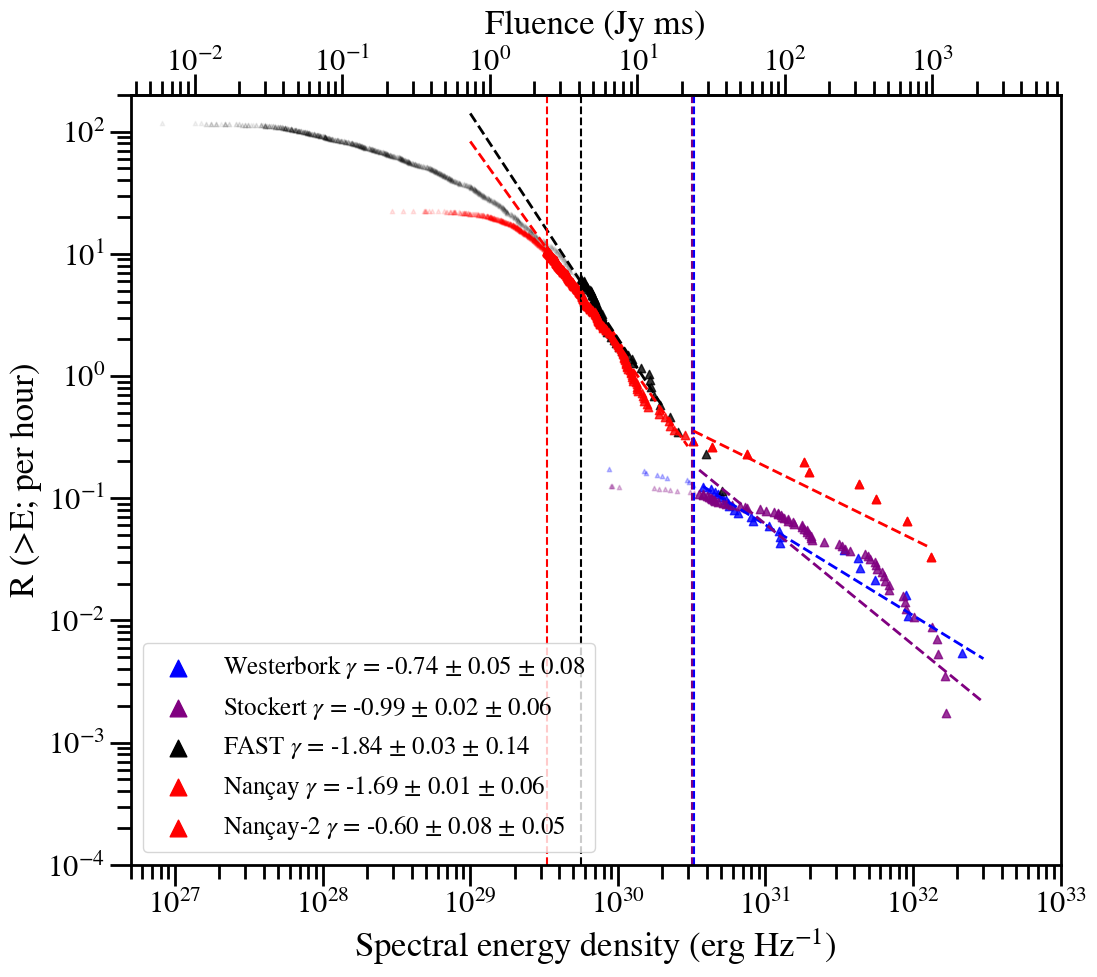

In [29]:
def distr_fast_r117():
    '''
    Function to create a joint fit of 4 telescopes
    mjd range: mjd_begin = 59869 mjd_end = 59910
    The dates are defined in the extraction functions above, these are hardcoded
    
    Telescopes used: FAST / Nancay / Stockert and Westerbork
    Torun was not used due to having only 2 bursts in MJD-range
    
    Output: Cumulative distribution
    '''

    energies_array_stk = isotropic_energies(fluences_stk_arr)
    energies_array_wb = isotropic_energies(fluences_wb_arr)
    energies_array_fast = isotropic_energies(fast_fluence_r117)  
    energies_array_nc = isotropic_energies(fluences_nc_arr)  
    
    f_limit_wb = fluence_limit(sefd=420, width=3, bw=100, snr=15)
    energie_threshold_wb = isotropic_energies([f_limit_wb])

    f_limit_stk = fluence_limit(sefd=385, width=3, bw=90, snr=15)
    energie_threshold_stk = isotropic_energies([f_limit_stk])
    
    f_limit_nc = fluence_limit(sefd=35/1.4, bw=248.55874673629242, width=9.064, snr=15)
    energie_threshold_nc = isotropic_energies([f_limit_nc])
    
    f_limit_fast = fluence_limit(sefd=18/16.1, bw=248.55874673629242, width=9.064, snr=15)
    energie_threshold_fast = isotropic_energies([f_limit_fast])

    #Get the breakpoint
    breakpoint_nc = breakpoint_nancay(fluences_nc_arr, obs_h=30.5)
    
    #lists with information to loop over    
    fluences = [fluences_wb_arr, fluences_stk_arr, fast_fluence_r117, fluences_nc_arr,fluences_nc_arr]
    obs_hours = [185.72, 567.4, 8.67, 30.5, 30.5]
    thresholds = [energie_threshold_wb, energie_threshold_stk, energie_threshold_fast, energie_threshold_nc,breakpoint_nc]
    dish = ['Westerbork', "Stockert", "FAST", "Nançay", "Nançay-2"]
    color = ['blue', 'purple', "black", "red", "red"]
    limit = [1e35, 4e30, 2e30, breakpoint_nc, 1e31]
    
    #   Figure
    #plt.figure(figsize=(12,10))
    f, ax = plt.subplots(1, figsize=(12,10))
    #plt.title("Cumulative distribution of burst densities", fontsize=28)
    
    #Dict that will be returned at the end of the function
    sols_dict = {}
    tresh = {}
    
    for fluences_arr, obs_h, energie_threshold, dish, color, limit in zip(fluences, obs_hours, thresholds, dish, color, limit):
            
        print(f"Fitting: {dish}")
        
        #Energy is sorted from high-low
        energies_arr = isotropic_energies(fluences_arr)

        # #Powerlaw fit
        # if dish == "Stockert":
        #     ex_max_num = 15 
        # elif dish == "Westerbork":
        #     ex_max_num = 3
        # elif dish == "Nançay-2":
        #     ex_max_num = 2
        # else:
        #     ex_max_num = None
            
        energies_fit, y_points_fit, energies_ex, y_points_ex, sol2, sol2_err, turning_point, b_alpha = \
                power_law_fit(energies_arr, observed_time=obs_h, scale=10**18, \
                              limit=(energie_threshold, limit),limit_b=True, ex_max=None)
        
        
        plt.scatter(np.sort(energies_fit), np.flip(y_points_fit), color=color, marker = "^", alpha=0.8, \
                     label = fr"{dish} $\gamma$ = {sol2[0][1]:.2f} $\pm$ {sol2_err[1]:.2f} $\pm$ {b_alpha:.2f}")

        #Get the poissonian errors on the points
        #low_err = get_poisson_error(np.flip(y_points_fit)*obs_h)[0]/obs_h
        #upp_err = get_poisson_error(np.flip(y_points_fit)*obs_h)[1]/obs_h
#         plt.errorbar(np.sort(energies_fit), np.flip(y_points_fit), \
#                      yerr = (np.flip(y_points_fit)-low_err, upp_err-np.flip(y_points_fit)), \
#                      alpha = 0.8, color =color,zorder =0,capsize=0, fmt='None')

        if dish == "FAST" or dish == "Nançay":
            plt.axvline(turning_point, color=color, linestyle='--')
        elif dish != "Nançay-2":
            plt.axvline(energie_threshold, color=color, linestyle='--')

        if dish == "FAST" or dish == "Nançay":
            plot_range = np.logspace(np.log10(1e29), np.log10(limit), 50)
            energies_fit = plot_range
            alpha_plot = 0.05
            
        if dish == "Westerbork" or dish == "Stockert":
            plot_range = np.logspace(np.log10(energies_fit[0]), np.log10(3e32), 50)
            energies_fit = plot_range
            alpha_plot = 0.25
            
        plt.plot(energies_fit,func_powerlaw(energies_fit,*sol2[0]),color=color,lw=2.0,ls='dashed')

        plt.scatter(np.sort(energies_ex), np.flip(y_points_ex), color=color, marker="^", alpha=alpha_plot, s=10)
        
        sols_dict[color] = sol2
        tresh[color] = energie_threshold

        #print(f"sols for fit: {sol2}")

    def fluence_to_energy(fluence):
        return isotropic_energies([fluence])[0]

    def energy_to_fluence_single(energy):
        return energy_to_fluence([energy])[0]
        
    # Secondary X-Axis
    secax = ax.secondary_xaxis('top', functions=(energy_to_fluence_single, fluence_to_energy))

    for ax in [ax,secax]:
        for axis in ['top','bottom','left','right']:
            ax.spines[axis].set_linewidth(2)
                
            ax.tick_params(axis='y', which='major', direction='out', length=15, width=2)
            ax.tick_params(axis='y', which='minor', direction='out', length=10, width=2)
            ax.tick_params(axis='x', which='major', direction='out', length=15, width=2)
            ax.tick_params(axis='x', which='minor', direction='out', length=10, width=2)

    secax.set_xlabel("Fluence (Jy ms)", fontsize=25, labelpad=10)
    secax.tick_params(axis='x', labelsize=22, pad=-2.5)
    
    plt.ylabel("R (>E; per hour)", fontsize=25)
    #
    #plt.xlabel("Spectral energy density (erg/Hz)", fontsize=25)
    plt.xlabel("Spectral energy density (erg Hz$^{-1}$)", fontsize=25)
    plt.xscale('log')
    plt.yscale('log')
    plt.xticks(fontsize=22)
    plt.yticks(fontsize=22)
    plt.ylim(0.0001,200)
    plt.xlim(5e26,1e33)
    #plt.xlim(1e30,5e32)
    
    leg = plt.legend(loc='lower left', markerscale=2, fontsize=18)    
    for lh in leg.legendHandles: 
        lh.set_alpha(1)

    save_name = "burstrate_paperV5_2scales"
    plt.savefig(f"../plots/{save_name}.pdf", format = 'pdf', dpi=300, bbox_inches='tight')
    plt.savefig(f"../plots/{save_name}.png", facecolor='white', transparent=False, \
                format = 'png',bbox_inches='tight', dpi=300)
    plt.show()

    return sols_dict, tresh

sols_dict_dist, energy_tresh = distr_fast_r117()

wb : 16
[2629.40001722 1370.93628527 1049.00488332  826.57710891  782.96819964
  720.24842889  558.93905556  453.57566203  372.14852575  320.7848596
  281.96192064  277.9206918   274.2475653   235.99769592  157.25811856
  121.20358017]
Calculating best minimal value for power law fit
No limit_b, Turning point: 3.196561346793486e+31
3.196561346793486e+31 None
[[7.23273138348206e+32, -1.0969323931147672], array([[8.93759981e+58, 1.99373533e+28],
       [1.99373533e+28, 4.56787545e-03]])]
Bootstrapping, only using 12 points out of 14 points


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 2219.82it/s]
/tmp/ipykernel_1089471/1016620087.py:78: MatplotlibDeprecationWarning: The legendHandles attribute was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use legend_handles instead.
  for lh in leg.legendHandles:


boot_alpha: 0.1528421283820752


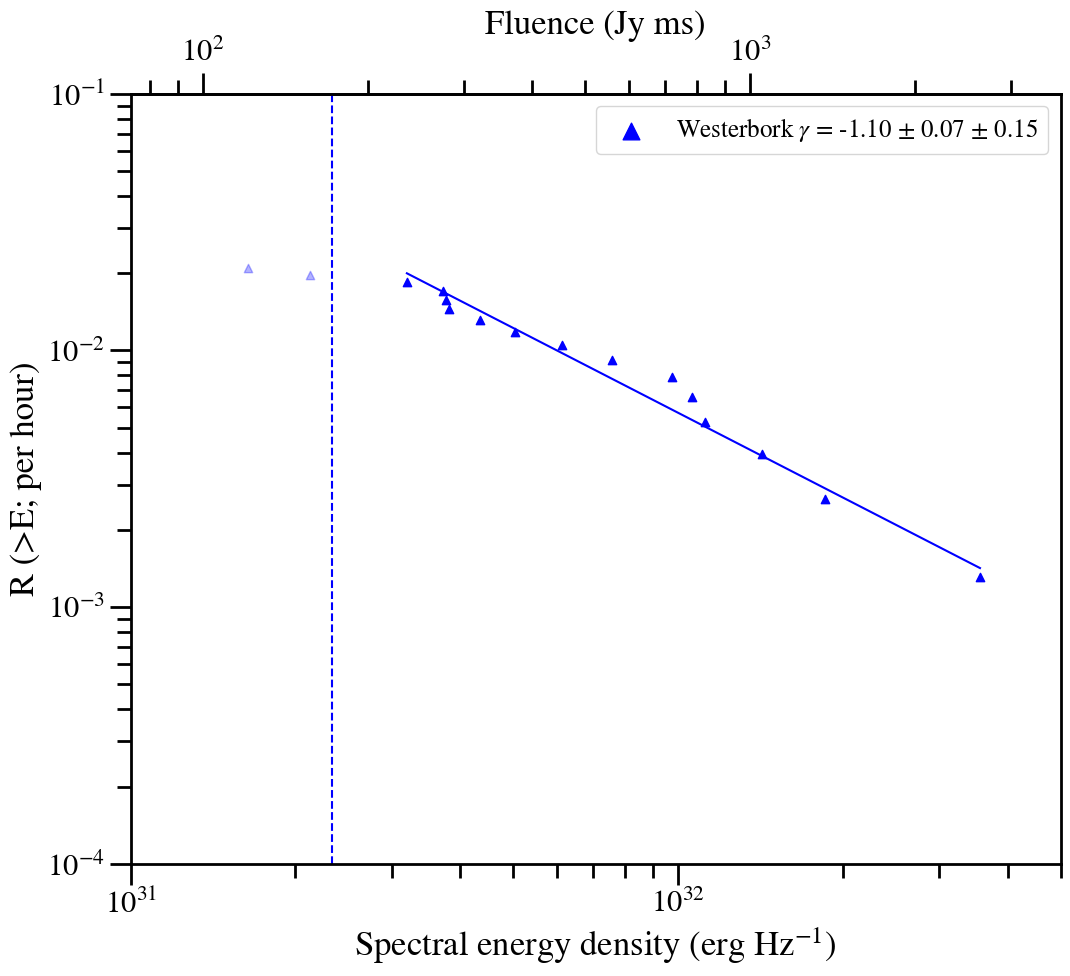

In [30]:
def distr_westerbork_p(mjd_toggle=False):
    """
    Westebork P-band cumulative distribution
    """
            
    fluence_df = load_df("../dbs/burst_stats_r117.csv", band="P", mjd_limit=mjd_toggle)
    fluences_wb_arr = fluences_arrays(fluence_df, telescope='wb')
    
    print(fluences_wb_arr)
    energies_array_wb = isotropic_energies(fluences_wb_arr)
    
    f_limit_wb = fluence_limit(sefd=2100, width=3, bw=50, snr=15)
    energie_threshold = isotropic_energies([f_limit_wb])    

    if mjd_toggle == True:
        save_name = "mjd_limit"
        obs_h = 760.01
        
    else:
        save_name = "full_camp"  
        obs_h = 760.01
        
    #Stockert    
    fluences_arr = fluences_wb_arr
    
    dish = "Westerbork"
    color = 'blue'
    limit = 8e31
    
    f, ax = plt.subplots(1, figsize=(12,10))
    
    #Energy is sorted from high-low
    energies_arr = isotropic_energies(fluences_arr)

    #Powerlaw fit
    energies_fit, y_points_fit, energies_ex, y_points_ex, sol2, sol2_err, turning_point, b_alpha = \
            power_law_fit(energies_arr, observed_time=obs_h, scale=10**18, \
                          limit=(energie_threshold, limit),limit_b=True, ex_max=None)

    plt.scatter(np.sort(energies_ex), np.flip(y_points_ex), color=color, marker="^", alpha=0.3)
    plt.scatter(np.sort(energies_fit), np.flip(y_points_fit), color=color, marker = "^", alpha=1.0, \
                 label = fr"{dish} $\gamma$ = {sol2[0][1]:.2f} $\pm$ {sol2_err[1]:.2f} $\pm$ {b_alpha:.2f}")

    #Get the poissonian errors on the points
#     low_err = get_poisson_error(np.flip(y_points_fit)*obs_h)[0]/obs_h
#     upp_err = get_poisson_error(np.flip(y_points_fit)*obs_h)[1]/obs_h
#     plt.errorbar(np.sort(energies_fit), np.flip(y_points_fit), \
#                  yerr = (np.flip(y_points_fit)-low_err, upp_err-np.flip(y_points_fit)), \
#                  alpha = 0.8, color=color, zorder =0, capsize=4, fmt='None')

    plt.plot(energies_fit,func_powerlaw(energies_fit,*sol2[0]),color=color,lw=1.5)
    plt.axvline(energie_threshold, color=color, linestyle='--')
#     sols_dict[color] = sol2
#     tresh[color] = energie_threshold

        #print(f"sols for fit: {sol2}")
    def fluence_to_energy(fluence):
        return isotropic_energies([fluence])[0]

    def energy_to_fluence_single(energy):
        return energy_to_fluence([energy])[0]
        
    # Secondary X-Axis
    secax = ax.secondary_xaxis('top', functions=(energy_to_fluence_single, fluence_to_energy))
    secax.set_xlabel("Fluence (Jy ms)", fontsize=25)
    secax.tick_params(axis='x', labelsize=22)
    
    plt.ylabel("R (>E; per hour)", fontsize=25)
    plt.xlabel("Spectral energy density (erg Hz$^{-1}$)", fontsize=25)
    plt.xscale('log')
    plt.yscale('log')
    plt.xticks(fontsize=22)
    plt.yticks(fontsize=22)
    plt.ylim(0.0001,0.1)
    plt.xlim(1e31,5e32)

    leg = plt.legend(loc='upper right', markerscale=2, fontsize=18)    
    for lh in leg.legendHandles: 
        lh.set_alpha(1)

    for ax in [ax,secax]:
        for axis in ['top','bottom','left','right']:
            ax.spines[axis].set_linewidth(2)
                
            ax.tick_params(axis='y', which='major', direction='out', length=15, width=2)
            ax.tick_params(axis='y', which='minor', direction='out', length=10, width=2)
            ax.tick_params(axis='x', which='major', direction='out', length=15, width=2)
            ax.tick_params(axis='x', which='minor', direction='out', length=10, width=2)
        
    # plt.savefig(f"../plots/wb_p_{save_name}_burstrate.pdf", format = 'pdf', dpi=600, bbox_inches='tight')
    # plt.savefig(f"../plots/wb_p_{save_name}_burstrate.png", \
    #             bbox_inches='tight', facecolor='white', transparent=False, dpi=300)
    plt.show()

    return 

distr_westerbork_p(mjd_toggle=False)

In [30]:
def fluence_to_energy(fluence):
    energy = isotropic_energies([fluence])[0]
    print(energy)
    #print(f"Converting fluence {fluence} Jy ms to energy {energy:.2e} erg/Hz")
    return energy

def energy_to_fluence_single(energy):
    fluence = energy_to_fluence([energy])[0]
    #print(f"Converting energy {energy:.2e} erg/Hz to fluence {fluence:.2f} Jy ms")
    return fluence

energies_array_wb = isotropic_energies(fluences_wb_arr)
energy_to_fluence_single(energies_array_wb)

array([1587.2815765 ,  684.0093537 ,  662.11520222,  408.44179458,
        321.62157061,  314.50166501,  251.05337287,   92.81378426,
         92.27794638,   90.93302299,   77.72601496,   61.15631478,
         59.12454653,   48.04481278,   45.07985141,   41.72572812,
         41.47876676,   40.13760826,   37.65418055,   35.35817971,
         33.75945829,   31.60503573,   27.83895564,   23.9294037 ,
         22.40944704,   21.76583923,   16.00705009,   14.80717258,
         13.57549063,   11.46700706,   11.11167231,    6.39292784])

Calculating best minimal value for power law fit
Turning point: 3.286268546464958e+29
breakpoint of the double powerlaw: 2.9779362041782494e+30
Fitting: Wb
Calculating best minimal value for power law fit
No limit_b, Turning point: 3.7707541675590537e+30
3.7707541675590537e+30 None
[[5.962008276714657e+21, -0.7417024728171762], array([[1.20133067e+57, 1.63899063e+27],
       [1.63899063e+27, 2.42667453e-03]])]
Bootstrapping, only using 20 points out of 23 points


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 3449.62it/s]


boot_alpha: 0.0796163513408756
Fitting: St
Calculating best minimal value for power law fit
No limit_b, Turning point: 3.5567833112283054e+30
3.5567833112283054e+30 None
[[2.4711453482560137e+29, -0.9872537297773023], array([[1.85064455e+57, 8.63146310e+26],
       [8.63146310e+26, 4.75749351e-04]])]
Bootstrapping, only using 55 points out of 62 points


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 1867.79it/s]


boot_alpha: 0.056210955725847625
Fitting: FAST
Calculating best minimal value for power law fit
No limit_b, Turning point: 5.608936343767962e+29
5.608936343767962e+29 None
[[3.3551457711106466e+55, -1.8405840373542537], array([[ 3.36465099e+57, -1.35115392e+27],
       [-1.35115392e+27,  1.03846993e-03]])]
Bootstrapping, only using 48 points out of 54 points


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 3489.91it/s]


... (3 outputs left out)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 2847.06it/s]


boot_alpha: 0.04817256432708555
wb : 16
Calculating best minimal value for power law fit
No limit_b, Turning point: 3.196561346793486e+31
3.196561346793486e+31 None
[[7.23273138348206e+32, -1.0969323931147672], array([[8.93759981e+58, 1.99373533e+28],
       [1.99373533e+28, 4.56787545e-03]])]
Bootstrapping, only using 12 points out of 14 points


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 3134.97it/s]
/tmp/ipykernel_1089471/1324028438.py:158: MatplotlibDeprecationWarning: The legendHandles attribute was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use legend_handles instead.
  for lh in leg.legendHandles:
/tmp/ipykernel_1089471/1324028438.py:174: MatplotlibDeprecationWarning: The legendHandles attribute was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use legend_handles instead.
  for lh in leg.legendHandles:


boot_alpha: 0.15726076126747832


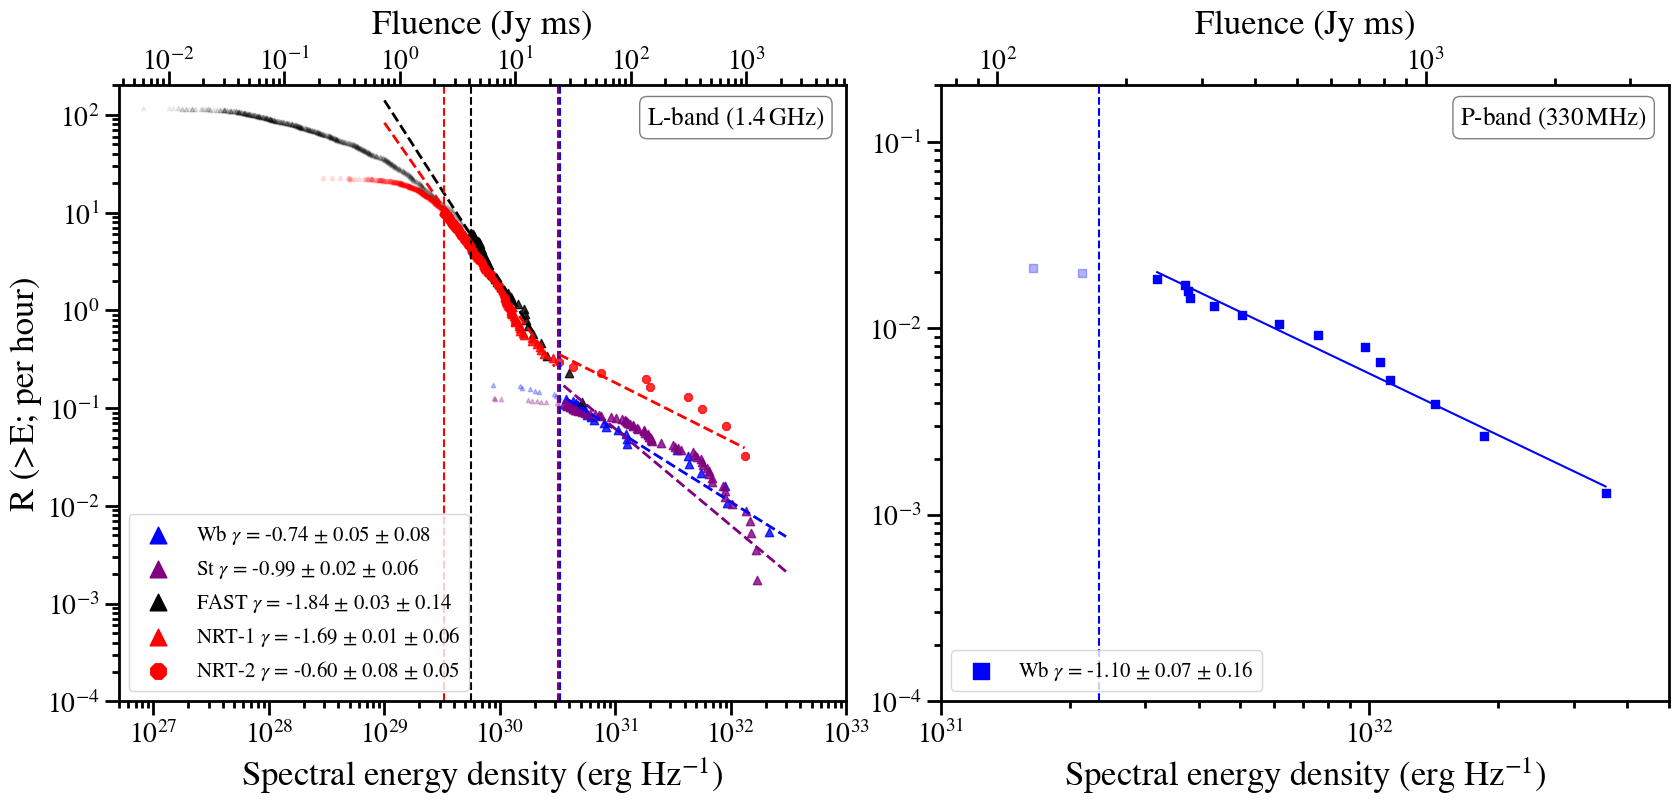

In [33]:
def cumulative_distr_2panels():
    '''
    Function to create a joint fit of 4 telescopes
    mjd range: mjd_begin = 59869 mjd_end = 59910
    The dates are defined in the extraction functions above, these are hardcoded
    
    Telescopes used: FAST / Nancay / Stockert and Westerbork
    Torun was not used due to having only 2 bursts in MJD-range
    
    Output: Cumulative distribution
    '''
    
    ######
    #L-band data
    ######
    energies_array_stk = isotropic_energies(fluences_stk_arr)
    energies_array_wb = isotropic_energies(fluences_wb_arr)
    energies_array_fast = isotropic_energies(fast_fluence_r117)  
    energies_array_nc = isotropic_energies(fluences_nc_arr)  
    
    f_limit_wb = fluence_limit(sefd=420, width=3, bw=100, snr=15)
    energie_threshold_wb = isotropic_energies([f_limit_wb])

    f_limit_stk = fluence_limit(sefd=385, width=3, bw=90, snr=15)
    energie_threshold_stk = isotropic_energies([f_limit_stk])
    
    f_limit_nc = fluence_limit(sefd=35/1.4, bw=248.55874673629242, width=9.064, snr=15)
    energie_threshold_nc = isotropic_energies([f_limit_nc])
    
    f_limit_fast = fluence_limit(sefd=18/16.1, bw=248.55874673629242, width=9.064, snr=15)
    energie_threshold_fast = isotropic_energies([f_limit_fast])

    #Get the breakpoint
    breakpoint_nc = breakpoint_nancay(fluences_nc_arr, obs_h=30.5)
    
    #lists with information to loop over    
    fluences = [fluences_wb_arr, fluences_stk_arr, fast_fluence_r117, fluences_nc_arr,fluences_nc_arr]
    obs_hours = [185.72, 567.4, 8.67, 30.5, 30.5]
    thresholds = [energie_threshold_wb, energie_threshold_stk, energie_threshold_fast, energie_threshold_nc,breakpoint_nc]
    dish = ['Wb', "St", "FAST", "NRT-1", "NRT-2"]
    color = ['blue', 'purple', "black", "red", "red"]
    limit = [1e35, 4e30, 2e30, breakpoint_nc, 1e31]
    
    #Setting up the Figure
    fig = plt.figure(figsize=(20, 8))
    rows=1
    cols=2
    widths = [1,1]
    heights = [1]

    gs = gridspec.GridSpec(ncols=cols, nrows=rows,width_ratios=widths, height_ratios=heights, wspace=0.13, hspace=0.15)

    ######
    #L-band plotting
    ######
    
    ax1 = fig.add_subplot(gs[0,0])
    #Dict that will be returned at the end of the function
    sols_dict = {}
    tresh = {}
    
    for fluences_arr, obs_h, energie_threshold, dish, color, limit in zip(fluences, obs_hours, thresholds, dish, color, limit):
            
        print(f"Fitting: {dish}")
        
        #Energy is sorted from high-low
        energies_arr = isotropic_energies(fluences_arr)

        energies_fit, y_points_fit, energies_ex, y_points_ex, sol2, sol2_err, turning_point, b_alpha = \
                power_law_fit(energies_arr, observed_time=obs_h, scale=10**18, \
                              limit=(energie_threshold, limit),limit_b=True, ex_max=None)

        energies_fit = np.sort(energies_fit) 
        y_points_fit = np.flip(y_points_fit)
        
        marker_s = '^'
        if dish == "NRT-2":
            marker_s = '8'

        if dish == "NRT-1":
            #The 9 high energy points in the tail
            energies_fit = energies_fit[:-9]
            y_points_fit = y_points_fit[:-9]
            
        ax1.scatter(energies_fit, y_points_fit, color=color, marker = marker_s, alpha=0.8, \
                     label = fr"{dish} $\gamma$ = {sol2[0][1]:.2f} $\pm$ {sol2_err[1]:.2f} $\pm$ {b_alpha:.2f}")
        
        if dish == "FAST" or dish == "NRT-1":
            ax1.axvline(turning_point, color=color, linestyle='--')
        elif dish != "NRT-2":
            ax1.axvline(energie_threshold, color=color, linestyle='--')
            

        if dish == "FAST" or dish == "NRT-1":
            plot_range = np.logspace(np.log10(1e29), np.log10(limit), 50)
            energies_fit = plot_range
            alpha_plot = 0.05
            
        if dish == "Wb" or dish == "St":
            plot_range = np.logspace(np.log10(energies_fit[0]), np.log10(3e32), 50)
            energies_fit = plot_range
            alpha_plot = 0.25
            
        ax1.plot(energies_fit,func_powerlaw(energies_fit,*sol2[0]),color=color,lw=2.0,ls='dashed')
        ax1.scatter(np.sort(energies_ex), np.flip(y_points_ex), color=color, marker=marker_s, alpha=alpha_plot, s=10)
        
        sols_dict[color] = sol2
        tresh[color] = energie_threshold

    ######
    #P-band data and plotting
    ######
    ax2 = fig.add_subplot(gs[0,1])

    fluence_df = load_df("../dbs/burst_stats_r117.csv", band="P", mjd_limit=False)
    fluences_arr = fluences_arrays(fluence_df, telescope='wb')

    energies_arr = isotropic_energies(fluences_arr)
    
    f_limit_wb = fluence_limit(sefd=2100, width=3, bw=50, snr=15)
    energie_threshold = isotropic_energies([f_limit_wb])   
    
    dish = "Wb"
    color = 'blue'
    limit = 8e31
    obs_h = 760.01
    
    #Powerlaw fit
    energies_fit, y_points_fit, energies_ex, y_points_ex, sol2, sol2_err, turning_point, b_alpha = \
            power_law_fit(energies_arr, observed_time=obs_h, scale=10**18, \
                          limit=(energie_threshold, limit),limit_b=True, ex_max=None)

    ax2.scatter(np.sort(energies_ex), np.flip(y_points_ex), color=color, marker="s", alpha=0.3)
    ax2.scatter(np.sort(energies_fit), np.flip(y_points_fit), color=color, marker = "s", alpha=1.0, \
                 label = fr"{dish} $\gamma$ = {sol2[0][1]:.2f} $\pm$ {sol2_err[1]:.2f} $\pm$ {b_alpha:.2f}")

    ax2.plot(energies_fit,func_powerlaw(energies_fit,*sol2[0]),color=color,lw=1.5)
    ax2.axvline(energie_threshold, color=color, linestyle='--')

    ######
    #Functions for the secondary axis
    ######    
    def fluence_to_energy(fluence):
        return isotropic_energies([fluence])[0]

    def energy_to_fluence_single(energy):
        return energy_to_fluence([energy])[0]
        
    ######
    #Make up Ax1
    ######
    ax1.set_ylabel("R (>E; per hour)", fontsize=25)
    ax1.set_xlabel("Spectral energy density (erg Hz$^{-1}$)", fontsize=25)
    ax1.set_xlim(5e26,1e33)
    ax1.set_ylim(0.0001,200)
    
    leg = ax1.legend(loc='lower left', markerscale=2, fontsize=15)    
    for lh in leg.legendHandles: 
        lh.set_alpha(1)

    # Secondary x-axis for ax1
    secax1 = ax1.secondary_xaxis('top', functions=(energy_to_fluence_single, fluence_to_energy))
    secax1.set_xlabel("Fluence (Jy ms)", fontsize=25, labelpad=10)
    secax1.tick_params(axis='x', labelsize=20, pad=-2.5)
    
    ######
    #Make up Ax2
    ######
    ax2.set_xlabel("Spectral energy density (erg Hz$^{-1}$)", fontsize=25)    
    ax2.set_ylim(0.0001,0.2)
    ax2.set_xlim(1e31,5e32)

    leg = ax2.legend(loc='lower left', markerscale=2, fontsize=15)    
    for lh in leg.legendHandles: 
        lh.set_alpha(1)

    # Secondary x-axis for ax2
    secax2 = ax2.secondary_xaxis('top', functions=(energy_to_fluence_single, fluence_to_energy))
    secax2.set_xlabel("Fluence (Jy ms)", fontsize=25, labelpad=10)
    secax2.tick_params(axis='x', labelsize=20, pad=-2.5)
    
    ###
    #Text in box
    ###
    props = dict(boxstyle='round', facecolor='white', alpha=0.5)
    ax1.text(0.97, 0.97, r'L-band ($1.4\,\mathrm{GHz}$)', transform=ax1.transAxes, fontsize=18,
        verticalalignment='top', bbox=props, horizontalalignment='right')
    ax2.text(0.97, 0.97, r'P-band ($330\,\mathrm{MHz}$)', transform=ax2.transAxes, fontsize=18,
        verticalalignment='top', bbox=props, horizontalalignment='right')   
    
    ######
    #Tick setting
    #####
    for ax in [secax1,secax2]:
        for axis in ['top','bottom','left','right']:
            ax.tick_params(axis='x', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='x', which='minor', direction='out', length=5, width=2)

        ax.tick_params(axis='both', which='major', labelsize=20)
        
    for ax in [ax1,ax2]:
        for axis in ['top','bottom','left','right']:
            ax.spines[axis].set_linewidth(2)
            ax.tick_params(axis='y', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='y', which='minor', direction='out', length=5, width=2)
            ax.tick_params(axis='x', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='x', which='minor', direction='out', length=5, width=2)
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.tick_params(axis='both', which='major', labelsize=20)
        

    save_name = "cumulative_burst_rate_pl_band_doublescales_v2"
    plt.savefig(f"../plots/{save_name}.pdf", format = 'pdf', dpi=300, bbox_inches='tight')
    plt.savefig(f"../plots/{save_name}.png", \
               bbox_inches='tight', facecolor='white', transparent=False, dpi=300)

cumulative_distr_2panels()

bandwidth = 248.32984293193718, width = 9.00207329842932
Index(['Unnamed: 0.2', 'Unnamed: 0.1', 'Unnamed: 0', 'lilo name', 'cand name',
       'power top', 'power middle', 'power bottom', 'power factor',
       'time width', 'freq width', 'center frequency', 'S/N', 'fluence',
       'downsampled', 'DM trial flag', 'smaller width', 'model A Probability',
       'model B Probability', 'model C Probability', 'model D Probability',
       'model E Probability', 'model F Probability', 'model G Probability',
       'model H Probability', 'FETCH prediction', 'bowtie prediction',
       'Real Burst', 'mjd_start', 'tcand', 'toa', 'telescope'],
      dtype='object')


/tmp/ipykernel_3060183/3970745453.py:10: DtypeWarning: Columns (14,15,16,26) have mixed types. Specify dtype option on import or set low_memory=False.
  nancay_df = pd.read_csv(csv_file, na_values='NA')
/tmp/ipykernel_3060183/3970745453.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nancay_df_real["mjd_start"] = nancay_df_real["cand name"].str.split("_").str[2].astype(float)
/tmp/ipykernel_3060183/3970745453.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nancay_df_real["tcand"] = nancay_df_real[

,toa,fluence,center frequency,cand name,telescope
0,59867.901979,3.060679,1.462,./cand_tstart_59867.901782407411_tcand_17.0225...,nc
1,59867.901981,2.902407,1.322,./cand_tstart_59867.901782407411_tcand_17.1152...,nc
2,59867.902294,4.021641,1.286,./cand_tstart_59867.901782407411_tcand_44.2316...,nc
3,59867.904719,2.834036,1.538,./cand_tstart_59867.904560185190_tcand_13.6797...,nc
4,59867.904719,2.832159,1.398,./cand_tstart_59867.904560185190_tcand_13.7065...,nc
...,...,...,...,...,...
759,60047.398337,4.703203,1.294,./cand_tstart_60047.397533851858_tcand_69.4007...,nc
760,60047.412026,0.431992,1.318,./cand_tstart_60047.411675629628_tcand_30.2788...,nc
761,60047.414698,1.123367,1.426,./cand_tstart_60047.414453407408_tcand_21.1340...,nc
762,60051.381234,9.000440,1.314,./cand_tstart_60051.381168111111_tcand_5.68000...,nc


nc : 764
number of bursts used: 764
Calculating best minimal value for power law fit
Turning point: 3.286268546464958e+29
breakpoint of the double powerlaw: 3.227008550664761e+30
Fitting: NRT-1
[2.16888724e+29] 3.227008550664761e+30
Calculating best minimal value for power law fit
No limit_b, Turning point: 3.286268546464958e+29
3.286268546464958e+29 None
[[1.287253138298638e+51, -1.6944646704328357], array([[ 1.01079769e+57, -3.45695564e+26],
       [-3.45695564e+26,  1.54495123e-04]])]
Bootstrapping, only using 325 points out of 362 points


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 1508.00it/s]


boot_alpha: 0.05327439883091617
Fitting: NRT-2
3.227008550664761e+30 1e+31
Calculating best minimal value for power law fit
No limit_b, Turning point: 3.247755908608579e+30
3.247755908608579e+30 None
[[5.2314340091133946e+17, -0.5954322004826191], array([[1.03183565e+58, 7.55470980e+27],
       [7.55470980e+27, 6.66152868e-03]])]
Bootstrapping, only using 8 points out of 9 points


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 2414.32it/s]


boot_alpha: 0.05123045875147113
762 762 760


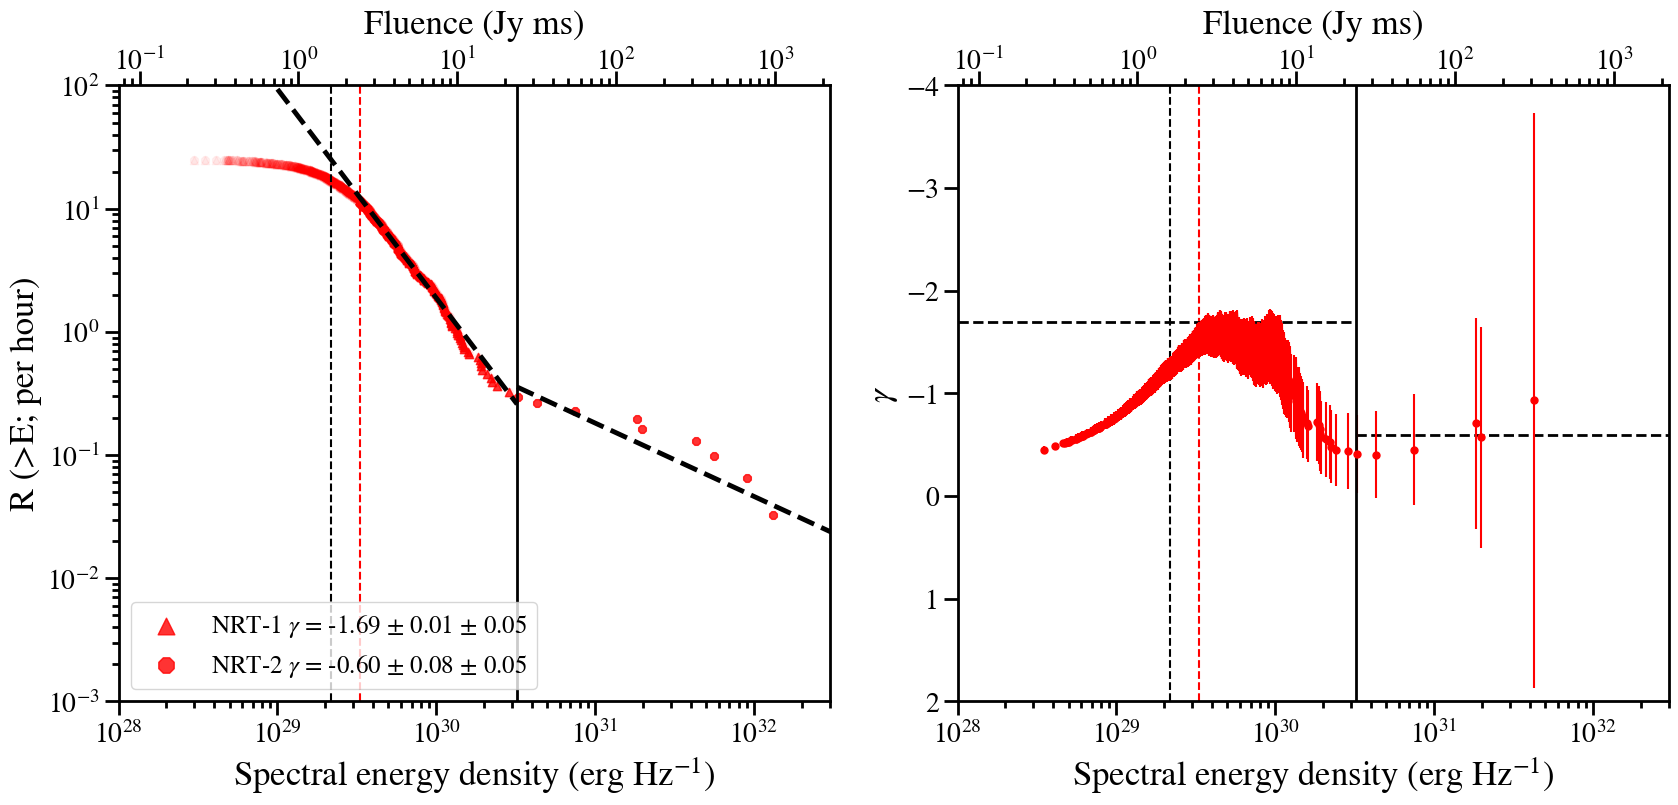

In [31]:
def distr_nancay(mjd_toggle=True):
    """
    Four panel analysis on the burst distirbution of Westerbork in the High energy tail
    top to bottom, left to right:
    panel 1: cummulative distribution with tail
    panel 2: cummulative distribution with the exclusion of the high enerfy tail, points are excluded based on eye.
    panel 3: differential distribution showing the fitted powerlaw of the cum. dist. plotted on top/
    panel 4: best gamma fit for the energies, vertical lines are the best fit gamma values for the two distributions.
    """
            
    fluence_df = nancay_r117(csv_file="/home/omar/git/nancay-r117/Burst-analyis-R117-Nancay/fixed_fluences.csv",\
                                 mjd_limit=mjd_toggle)
    fluences_nc_arr = fluences_arrays(fluence_df, telescope='nc')
    print(f"number of bursts used: {len(fluences_nc_arr)}")
    
    f_limit_nc = fluence_limit(sefd=35/1.4, bw=248.55874673629242, width =9.064, snr=15)
    energie_threshold = isotropic_energies([f_limit_nc])  


    if mjd_toggle == True:
        save_name = "mjd_limit"
        obs_h = 30.509
        
    else:
        save_name = "full_camp"  
        obs_h = 60.9933

    #Stockert    
    fluences_arr = fluences_nc_arr

    #Get the breakpoint
    breakpoint = breakpoint_nancay(fluences_arr, obs_h)
    
    #Setting up the Figure
    fig = plt.figure(figsize=(20, 8))
    rows=1
    cols=2
    widths = [1,1]
    heights = [1]

    gs = gridspec.GridSpec(ncols=cols, nrows=rows,width_ratios=widths, height_ratios=heights, wspace=0.18, hspace=0.15)

    ax1 = fig.add_subplot(gs[0,0])
    ax2 = fig.add_subplot(gs[0,1])

    #plt.title("Cumulative distribution of burst densities", fontsize=28)
        
    sols_dict = {}
    tresh = {}
    
    # lists with information to loop over    
    fluences = [fluences_arr, fluences_arr]
    obs_hours = [30.5,30.5]
    thresholds = [energie_threshold,breakpoint]
    dish = ["NRT-1", "NRT-2"]
    color = ["red", "red"]
    limit = [breakpoint, 1e31]
    
    for fluences_arr, obs_h, energie_threshold, dish, color, limit in zip(fluences, obs_hours, thresholds, dish, color, limit):
            
        print(f"Fitting: {dish}")
        
        #Energy is sorted from high-low
        energies_arr = isotropic_energies(fluences_arr)
        print(energie_threshold, limit)
        ############
        #Single Powerlaws
        ############  
        energies_fit, y_points_fit, energies_ex, y_points_ex, sol2, sol2_err, turning_point, b_alpha = \
                power_law_fit(energies_arr, observed_time=obs_h, scale=10**18, \
                              limit=(energie_threshold, limit),limit_b=True, ex_max=None)
        marker_s = '^'
        if dish == "NRT-2":
            marker_s = '8'
            
        energies_fit = np.sort(energies_fit) 
        y_points_fit = np.flip(y_points_fit)
        
        if dish == "NRT-1":
            #The 9 high energy points in the tail
            energies_fit = energies_fit[:-9]
            y_points_fit = y_points_fit[:-9]
        
        ax1.scatter(energies_fit, y_points_fit, color=color, marker = marker_s, alpha=0.8, \
                     label = fr"{dish} $\gamma$ = {sol2[0][1]:.2f} $\pm$ {sol2_err[1]:.2f} $\pm$ {b_alpha:.2f}")
        
        if dish == "NRT-1":
            plot_range = np.logspace(np.log10(1e29), np.log10(limit), 50)
            ax1.axvline(energie_threshold, color='black', linestyle='--')
            ax2.axvline(energie_threshold, color='black', linestyle='--')
            ax1.axvline(turning_point, color=color, linestyle='--')
            
            ax2.axvline(turning_point, color=color, linestyle='--')
            ax2.hlines(sol2[0][1], xmin=1e28, xmax=breakpoint, lw=2.0, ls='--', color='black')
            
        if dish == "NRT-2":
            plot_range = np.logspace(np.log10(breakpoint), np.log10(1e33), 50)

            ax2.hlines(sol2[0][1], xmin=breakpoint, xmax=1e34, lw=2.0, ls='--', color='black')

        ax1.plot(plot_range,func_powerlaw(plot_range,*sol2[0]),color='black',linestyle='--',lw=3.5)
        ax1.scatter(np.sort(energies_ex), np.flip(y_points_ex), color=color, marker=marker_s, alpha=0.05)

    ######
    #Functions for the secondary axis
    ######    
    def fluence_to_energy(fluence):
        return isotropic_energies([fluence])[0]

    def energy_to_fluence_single(energy):
        return energy_to_fluence([energy])[0]
        

    #Outside of for-loop
    ax1.legend(loc='lower left', markerscale=2, fontsize=18)
    ax1.set_ylim(0.001,100)
    ax1.set_ylabel("R (>E; per hour)", fontsize=25)
    ax1.axvline(breakpoint, color='black', linestyle='solid',lw=2) #Plotting the breakpoint
    
    ############
    #Gamma slopes
    ############    
    #Call the gamma_slopes function
    total_gamma, energy_threshold, error_ar = gamma_slopes(energies_arr, conf_level=2)
    print(len(total_gamma), len(energy_threshold), len(error_ar))
    
    ax2.errorbar(energy_threshold[:-2], total_gamma[:-2], yerr = np.abs(error_ar), fmt='.', color=color\
                 , markersize=10)
    ax2.axvline(breakpoint, color='black', linestyle='solid',lw=2) #Plotting the breakpoint
    ax2.set_ylabel(r'$\gamma$', fontsize=25)
    ax2.set_ylim(2,-4)
    #ax2.axhline(negative_slope, color=color, linestyle='dashdot', linewidth=2.5)
    ax2.yaxis.set_major_locator(ticker.MultipleLocator(1.0))


    
    ax1.set_xlim(1e28,3e32)
    ax2.set_xlim(1e28,3e32)
    
    ax1.set_xlabel("Spectral energy density (erg Hz$^{-1}$)", fontsize=25)
    ax2.set_xlabel("Spectral energy density (erg Hz$^{-1}$)", fontsize=25)

    # Secondary x-axis for ax1
    secax1 = ax1.secondary_xaxis('top', functions=(energy_to_fluence_single, fluence_to_energy))
    secax1.set_xlabel("Fluence (Jy ms)", fontsize=25, labelpad=10)
    secax1.tick_params(axis='x', labelsize=20, pad=-2.5)

    # Secondary x-axis for ax2
    secax2 = ax2.secondary_xaxis('top', functions=(energy_to_fluence_single, fluence_to_energy))
    secax2.set_xlabel("Fluence (Jy ms)", fontsize=25, labelpad=10)
    secax2.tick_params(axis='x', labelsize=20, pad=-2.5)

    for ax in [secax1,secax2]:
        for axis in ['top','bottom','left','right']:
            ax.tick_params(axis='x', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='x', which='minor', direction='out', length=5, width=2)

        ax.tick_params(axis='both', which='major', labelsize=20)
        
    for ax in [ax1,ax2]:
        for axis in ['top','bottom','left','right']:
            
            ax.spines[axis].set_linewidth(2)
            ax.tick_params(axis='y', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='y', which='minor', direction='out', length=5, width=2)
            ax.tick_params(axis='x', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='x', which='minor', direction='out', length=5, width=2)
            
        if ax == ax1:
            ax.set_yscale('log')
        
        ax.set_xscale('log')
        ax.tick_params(axis='both', which='major', labelsize=20)
            
    save_name="slope_fig_appendix_v2"
    plt.savefig(f"../plots/nc_{save_name}.png", \
               bbox_inches='tight', facecolor='white', transparent=False, dpi=300)
    plt.savefig(f"../plots/nc_{save_name}.pdf", format = 'pdf', dpi=600, bbox_inches='tight')
    plt.show()

    return 

distr_nancay(mjd_toggle=False)

In [34]:
def distr_fast_r117_ata():
    '''
    Function to create a joint fit of 4 telescopes
    mjd range: mjd_begin = 59869 mjd_end = 59910
    The dates are defined in the extraction functions above, these are hardcoded
    
    Telescopes used: FAST / Nancay / Stockert and Westerbork
    Torun was not used due to having only 2 bursts in MJD-range
    
    Output: Cumulative distribution
    '''

    energies_array_stk = isotropic_energies(fluences_stk_arr)
    energies_array_wb = isotropic_energies(fluences_wb_arr)
    energies_array_fast = isotropic_energies(fast_fluence_r117)  
    energies_array_nc = isotropic_energies(fluences_nc_arr)  
    energies_array_ata = isotropic_energies(allen_fluence_r117)
    
    print(energies_array_ata)
    
    f_limit_wb = fluence_limit(sefd=420, width=3, bw=100, snr=15)
    energie_threshold_wb = isotropic_energies([f_limit_wb])

    f_limit_stk = fluence_limit(sefd=385, width=3, bw=80, snr=15)
    energie_threshold_stk = isotropic_energies([f_limit_stk])
    
    f_limit_nc = fluence_limit(sefd=35/1.4, bw=248.55874673629242, width=9.064, snr=15)
    energie_threshold_nc = isotropic_energies([f_limit_nc])
    
    f_limit_fast = fluence_limit(sefd=18/16.1, bw=248.55874673629242, width=9.064, snr=15)
    energie_threshold_fast = isotropic_energies([f_limit_fast])
    
    f_limit_ata = 100
    energie_threshold_ata = isotropic_energies([f_limit_ata])
    
    #lists with information to loop over    
    fluences = [fluences_wb_arr, fluences_stk_arr, fast_fluence_r117, fluences_nc_arr, allen_fluence_r117]
    obs_hours = [185.72, 567.4, 8.67, 30.5, 240]
    thresholds = [energie_threshold_wb, energie_threshold_stk, energie_threshold_fast, energie_threshold_nc,\
                 energie_threshold_ata]
    dish = ['Westerbork', "Stockert", "FAST", "Nançay", "ATA"]
    color = ['blue', 'purple', "black", "red", "green"]
    limit = [1e35, 4e30, 1e35, 1e35, 1e30]
    
    #   Figure
    #plt.figure(figsize=(12,10))
    f, ax = plt.subplots(1, figsize=(12,10))
    #plt.title("Cumulative distribution of burst densities", fontsize=28)
    
    for axis in ['top','bottom','left','right']:
        ax.spines[axis].set_linewidth(2)
            
        ax.tick_params(axis='y', which='major', direction='out', length=15, width=2)
        ax.tick_params(axis='y', which='minor', direction='out', length=10, width=2)
        ax.tick_params(axis='x', which='major', direction='out', length=15, width=2)
        ax.tick_params(axis='x', which='minor', direction='out', length=10, width=2)
        
    #Dict that will be returned at the end of the function
    sols_dict = {}
    tresh = {}
    
    for fluences_arr, obs_h, energie_threshold, dish, color, limit in zip(fluences, obs_hours, thresholds, dish, color, limit):
            
        print(f"Fitting: {dish}")
        
        #Energy is sorted from high-low
        energies_arr = isotropic_energies(fluences_arr)

        #Powerlaw fit
        energies_fit, y_points_fit, energies_ex, y_points_ex, sol2, sol2_err, turning_point, b_alpha = \
                power_law_fit(energies_arr, observed_time=obs_h, scale=10**18, \
                              limit=(energie_threshold, limit),limit_b=True, ex_max=None)

        plt.scatter(np.sort(energies_ex), np.flip(y_points_ex), color=color, marker="^", alpha=0.05, s=10)
        plt.scatter(np.sort(energies_fit), np.flip(y_points_fit), color=color, marker = "^", alpha=0.8, \
                     label = fr"{dish} $\gamma$ = {sol2[0][1]:.2f} $\pm$ {sol2_err[1]:.2f} $\pm$ {b_alpha:.2f}")

        #Get the poissonian errors on the points
        low_err = get_poisson_error(np.flip(y_points_fit)*obs_h)[0]/obs_h
        upp_err = get_poisson_error(np.flip(y_points_fit)*obs_h)[1]/obs_h
        plt.errorbar(np.sort(energies_fit), np.flip(y_points_fit), \
                     yerr = (np.flip(y_points_fit)-low_err, upp_err-np.flip(y_points_fit)), \
                     alpha = 0.8, color =color,zorder =0,capsize=0, fmt='None')

        if dish == "FAST" or dish == "Nançay" or dish == "ATA":
            plt.axvline(turning_point, color=color, linestyle='--')
        else:
            plt.axvline(energie_threshold, color=color, linestyle='--')

        if dish == "FAST" or dish == "Nançay":
            plot_range = np.logspace(np.log10(1e29), np.log10(energies_fit[-1]), 50)
            energies_fit = plot_range
        
        if dish == "Westerbork" or dish == "Stockert" or dish == "ATA":
            plot_range = np.logspace(np.log10(energies_fit[0]), np.log10(4e32), 50)
            energies_fit = plot_range
            
        plt.plot(energies_fit,func_powerlaw(energies_fit,*sol2[0]),color=color,lw=1.5)
        
        sols_dict[color] = sol2
        tresh[color] = energie_threshold

        #print(f"sols for fit: {sol2}")

    plt.ylabel("R (>E; per hour)", fontsize=25)
    plt.xlabel("Spectral energy density (erg/Hz)", fontsize=25)
    plt.xscale('log')
    plt.yscale('log')
    plt.xticks(fontsize=22)
    plt.yticks(fontsize=22)
    plt.ylim(0.0001,200)
    plt.xlim(5e26,1e33)
    #plt.xlim(1e30,5e32)
    
    leg = plt.legend(loc='lower left', markerscale=2, fontsize=18)    
    for lh in leg.legendHandles: 
        lh.set_alpha(1)

    #plt.savefig("../plots/burstrate_poster.pdf", bbox_inches='tight', facecolor='white', transparent=False, dpi=600)
    
#     save_name = "burstrate_paperV1"
#     plt.savefig(f"../plots/{save_name}.pdf", format = 'pdf', dpi=600, bbox_inches='tight')
#     plt.savefig(f"../plots/{save_name}.png", facecolor='white', transparent=False, \
#                 format = 'png',bbox_inches='tight', dpi=600)
    plt.show()

    return sols_dict, tresh

#sols_dict_dist, energy_tresh = distr_fast_r117_ata()

In [35]:
def distr_small_dish_full(mjd_toggle=False):
    """
    Cummulative distribution on small dishes (Wb/Tr/St) for the entire campaign
    """
            
    fluence_df = load_df("../dbs/burst_stats_r117.csv", band="L", mjd_limit=mjd_toggle)
    
    fluences_wb_arr = fluences_arrays(fluence_df, telescope='wb')
    fluences_tr_arr = fluences_arrays(fluence_df, telescope='tr')
    fluences_stk_arr = fluences_arrays(fluence_df, telescope='st')
    
    f_limit_wb = fluence_limit(sefd=420, width=3, bw=100, snr=15)
    energie_threshold_wb = isotropic_energies([f_limit_wb])    
        
    f_limit_tr = fluence_limit(sefd=250, width=3, bw=100, snr=15)
    energie_threshold_tr = isotropic_energies([f_limit_tr])
    
    f_limit_st = fluence_limit(sefd=385, width=3, bw=80, snr=15)
    energie_threshold_stk = isotropic_energies([f_limit_st])  
    
    #lists with information to loop over    
    fluences = [fluences_wb_arr, fluences_tr_arr, fluences_stk_arr]
    obs_hours = [196.58, 271.33, 933.53]
    thresholds = [energie_threshold_wb, energie_threshold_tr, energie_threshold_stk]
    dish = ["Westerbork","Toruń","Stockert"]
    color = ['blue',"orange","purple"]
    limit = [8e31,3e30,4e30]
        
    f, ax = plt.subplots(1, figsize=(12,10))       
    
    for fluences_arr, obs_h, energie_threshold, dish, color, limit in zip(fluences, obs_hours, thresholds, dish, color, limit):
            
        print(f"Fitting: {dish}")
        #Energy is sorted from high-low
        energies_arr = isotropic_energies(fluences_arr)

        #Powerlaw fit
        energies_fit, y_points_fit, energies_ex, y_points_ex, sol2, sol2_err, turning_point, b_alpha = \
                power_law_fit(energies_arr, observed_time=obs_h, scale=10**18, \
                              limit=(energie_threshold, limit),limit_b=True, ex_max=None)

        plt.scatter(np.sort(energies_ex), np.flip(y_points_ex), color=color, marker="^", alpha=0.3)
        plt.scatter(np.sort(energies_fit), np.flip(y_points_fit), color=color, marker = "^", alpha=1.0, \
                     label = fr"{dish} $\gamma$ = {sol2[0][1]:.2f} $\pm$ {sol2_err[1]:.2f} $\pm$ {b_alpha:.2f}")

        #Get the poissonian errors on the points
#         low_err = get_poisson_error(np.flip(y_points_fit)*obs_h)[0]/obs_h
#         upp_err = get_poisson_error(np.flip(y_points_fit)*obs_h)[1]/obs_h
#         plt.errorbar(np.sort(energies_fit), np.flip(y_points_fit), \
#                      yerr = (np.flip(y_points_fit)-low_err, upp_err-np.flip(y_points_fit)), \
#                      alpha = 0.8, color=color, zorder =0, capsize=4, fmt='None')

        plt.plot(energies_fit,func_powerlaw(energies_fit,*sol2[0]),color=color,lw=1.5)

        plt.axvline(energie_threshold, color=color, linestyle='--')

    plt.ylabel("R (>E; per hour)", fontsize=25)
    plt.xlabel("Spectral energy density (erg/Hz)", fontsize=25)
    plt.xscale('log')
    plt.yscale('log')
    plt.xticks(fontsize=22)
    plt.yticks(fontsize=22)
    plt.ylim(0.0001,1)
    plt.xlim(3e29,8e32)
    
    for axis in ['top','bottom','left','right']:
        ax.spines[axis].set_linewidth(2)
            
        ax.tick_params(axis='y', which='major', direction='out', length=15, width=2)
        ax.tick_params(axis='y', which='minor', direction='out', length=10, width=2)
        ax.tick_params(axis='x', which='major', direction='out', length=15, width=2)
        ax.tick_params(axis='x', which='minor', direction='out', length=10, width=2)
        
    leg = plt.legend(loc='upper right', markerscale=2, fontsize=18)    
    for lh in leg.legendHandles: 
        lh.set_alpha(1)
          
    save_name = "small_dish_full_V4"
    plt.savefig(f"../plots/{save_name}.pdf", format = 'pdf', dpi=600, bbox_inches='tight')
    plt.savefig(f"../plots/{save_name}.png", \
                bbox_inches='tight', facecolor='white', transparent=False, dpi=300)
    plt.show()

    return 

#distr_small_dish_full(mjd_toggle=False)

In [36]:
def distr_small_dish_full_allen(mjd_toggle=False):
    """
    Cummulative distribution on small dishes (Wb/Tr/St) for the entire campaign
    """
            
    csv_file="../dbs/allen-telescope/R117_allen_omar.csv"
    df_allen = pd.read_csv(csv_file, index_col=0)
    allen_fluences = df_allen['fluence'].values
        
    fluence_df = load_df("../dbs/burst_stats_r117.csv", band="L", mjd_limit=mjd_toggle)
    
    fluences_wb_arr = fluences_arrays(fluence_df, telescope='wb')
    fluences_tr_arr = fluences_arrays(fluence_df, telescope='tr')
    fluences_stk_arr = fluences_arrays(fluence_df, telescope='st')
    
    f_limit_wb = fluence_limit(sefd=420, width=3, bw=100, snr=15)
    energie_threshold_wb = isotropic_energies([f_limit_wb])    
        
    f_limit_tr = fluence_limit(sefd=250, width=3, bw=100, snr=15)
    energie_threshold_tr = isotropic_energies([f_limit_tr])
    
    f_limit_st = fluence_limit(sefd=385, width=3, bw=80, snr=15)
    energie_threshold_stk = isotropic_energies([f_limit_st])  
    
    f_limit_ata = 100
    energie_threshold_ata = isotropic_energies([f_limit_ata])   
    
    #lists with information to loop over    
    fluences = [fluences_wb_arr, fluences_tr_arr, fluences_stk_arr,allen_fluences]
    obs_hours = [196.58, 271.33, 933.53, 541]
    thresholds = [energie_threshold_wb, energie_threshold_tr, energie_threshold_stk,energie_threshold_ata]
    dish = ["Westerbork","Toruń","Stockert","ATA"]
    color = ['blue',"orange","purple",'green']
    limit = [8e31,3e30,4e30,1e30]
        
    f, ax = plt.subplots(1, figsize=(12,10))       
    
    for fluences_arr, obs_h, energie_threshold, dish, color, limit in zip(fluences, obs_hours, thresholds, dish, color, limit):
            
        print(f"Fitting: {dish}, {len(fluences_arr)}")
        #Energy is sorted from high-low
        energies_arr = isotropic_energies(fluences_arr)

        if dish == "ATA":
            limit_toggle = False
        else:
            limit_toggle = True
        #Powerlaw fit
        energies_fit, y_points_fit, energies_ex, y_points_ex, sol2, sol2_err, turning_point, b_alpha = \
                power_law_fit(energies_arr, observed_time=obs_h, scale=10**18, \
                              limit=(energie_threshold, limit),limit_b=limit_toggle, ex_max=None)

        plt.scatter(np.sort(energies_ex), np.flip(y_points_ex), color=color, marker="^", alpha=0.3)
        plt.scatter(np.sort(energies_fit), np.flip(y_points_fit), color=color, marker = "^", alpha=1.0, \
                     label = fr"{dish} $\gamma$ = {sol2[0][1]:.2f} $\pm$ {sol2_err[1]:.2f} $\pm$ {b_alpha:.2f}")

        #Get the poissonian errors on the points
        low_err = get_poisson_error(np.flip(y_points_fit)*obs_h)[0]/obs_h
        upp_err = get_poisson_error(np.flip(y_points_fit)*obs_h)[1]/obs_h
        plt.errorbar(np.sort(energies_fit), np.flip(y_points_fit), \
                     yerr = (np.flip(y_points_fit)-low_err, upp_err-np.flip(y_points_fit)), \
                     alpha = 0.8, color=color, zorder =0, capsize=4, fmt='None')

        plt.plot(energies_fit,func_powerlaw(energies_fit,*sol2[0]),color=color,lw=1.5)

        plt.axvline(energie_threshold, color=color, linestyle='--')

    plt.ylabel("R (>E; per hour)", fontsize=25)
    plt.xlabel("Spectral energy density (erg/Hz)", fontsize=25)
    plt.xscale('log')
    plt.yscale('log')
    plt.xticks(fontsize=22)
    plt.yticks(fontsize=22)
    plt.ylim(0.0001,1)
    plt.xlim(3e29,8e32)
    
    for axis in ['top','bottom','left','right']:
        ax.spines[axis].set_linewidth(2)
            
        ax.tick_params(axis='y', which='major', direction='out', length=15, width=2)
        ax.tick_params(axis='y', which='minor', direction='out', length=10, width=2)
        ax.tick_params(axis='x', which='major', direction='out', length=15, width=2)
        ax.tick_params(axis='x', which='minor', direction='out', length=10, width=2)
        
    leg = plt.legend(loc='upper right', markerscale=2, fontsize=18)    
    for lh in leg.legendHandles: 
        lh.set_alpha(1)
          
#     save_name = "small_dish_full"
#     plt.savefig(f"../plots/{save_name}_burstrate.pdf", format = 'pdf', dpi=600, bbox_inches='tight')
#     plt.savefig(f"../plots/{save_name}_burstrate.png", \
#                 bbox_inches='tight', facecolor='white', transparent=False, dpi=300)
    plt.show()

    return 

#distr_small_dish_full_allen(mjd_toggle=False)

In [37]:
def distr_stk_allen(mjd_toggle=False):
    """
    Cummulative distribution on small dishes (Wb/Tr/St) for the entire campaign
    """
            
    csv_file="../dbs/allen-telescope/R117_allen_omar.csv"
    df_allen = pd.read_csv(csv_file, index_col=0)
    allen_fluences = df_allen['fluence'].values
        
    fluence_df = load_df("../dbs/burst_stats_r117.csv", band="L", mjd_limit=mjd_toggle)

    fluences_stk_arr = fluences_arrays(fluence_df, telescope='st')
    
    f_limit_st = fluence_limit(sefd=385, width=3, bw=80, snr=15)
    energie_threshold_stk = isotropic_energies([f_limit_st])  
    
    f_limit_ata = 100
    energie_threshold_ata = isotropic_energies([f_limit_ata])   
    
    #lists with information to loop over    
    fluences = [fluences_stk_arr,allen_fluences]
    obs_hours = [933.53, 541]
    thresholds = [energie_threshold_stk,energie_threshold_ata]
    dish = ["Stockert","ATA"]
    color = ["purple",'green']
    limit = [4e30,1e30]
        
    f, ax = plt.subplots(1, figsize=(12,10))       
    
    for fluences_arr, obs_h, energie_threshold, dish, color, limit in zip(fluences, obs_hours, thresholds, dish, color, limit):
            
        print(f"Fitting: {dish}, {len(fluences_arr)}")
        #Energy is sorted from high-low
        energies_arr = isotropic_energies(fluences_arr)

        if dish == "ATA":
            limit_toggle = False
        else:
            limit_toggle = True
        #Powerlaw fit
        energies_fit, y_points_fit, energies_ex, y_points_ex, sol2, sol2_err, turning_point, b_alpha = \
                power_law_fit(energies_arr, observed_time=obs_h, scale=10**18, \
                              limit=(energie_threshold, limit),limit_b=limit_toggle, ex_max=None)

        plt.scatter(np.sort(energies_ex), np.flip(y_points_ex), color=color, marker="^", alpha=0.3)
        plt.scatter(np.sort(energies_fit), np.flip(y_points_fit), color=color, marker = "^", alpha=1.0, \
                     label = fr"{dish} $\gamma$ = {sol2[0][1]:.2f} $\pm$ {sol2_err[1]:.2f} $\pm$ {b_alpha:.2f}")

        #Get the poissonian errors on the points
        low_err = get_poisson_error(np.flip(y_points_fit)*obs_h)[0]/obs_h
        upp_err = get_poisson_error(np.flip(y_points_fit)*obs_h)[1]/obs_h
        plt.errorbar(np.sort(energies_fit), np.flip(y_points_fit), \
                     yerr = (np.flip(y_points_fit)-low_err, upp_err-np.flip(y_points_fit)), \
                     alpha = 0.8, color=color, zorder =0, capsize=4, fmt='None')

        plt.plot(energies_fit,func_powerlaw(energies_fit,*sol2[0]),color=color,lw=1.5)

        plt.axvline(energie_threshold, color=color, linestyle='--')

    plt.ylabel("R (>E; per hour)", fontsize=25)
    plt.xlabel("Spectral energy density (erg/Hz)", fontsize=25)
    plt.xscale('log')
    plt.yscale('log')
    plt.xticks(fontsize=22)
    plt.yticks(fontsize=22)
    plt.ylim(0.0001,0.2)
    plt.xlim(3e29,3e32)
    
    for axis in ['top','bottom','left','right']:
        ax.spines[axis].set_linewidth(2)
            
        ax.tick_params(axis='y', which='major', direction='out', length=15, width=2)
        ax.tick_params(axis='y', which='minor', direction='out', length=10, width=2)
        ax.tick_params(axis='x', which='major', direction='out', length=15, width=2)
        ax.tick_params(axis='x', which='minor', direction='out', length=10, width=2)
        
    leg = plt.legend(loc='lower left', markerscale=2, fontsize=18)    
    for lh in leg.legendHandles: 
        lh.set_alpha(1)
          
#     save_name = "small_dish_full"
#     plt.savefig(f"../plots/{save_name}_burstrate.pdf", format = 'pdf', dpi=600, bbox_inches='tight')
#     plt.savefig(f"../plots/{save_name}_burstrate.png", \
#                 bbox_inches='tight', facecolor='white', transparent=False, dpi=300)
    plt.show()

    return 

#distr_stk_allen(mjd_toggle=False)

In [38]:
def distr_allen(mjd_toggle=False):
    """
    allen cumulative distribution
    """
    
    csv_file="../dbs/allen-telescope/R117_allen_omar.csv"
    df_allen = pd.read_csv(csv_file, index_col=0)
    allen_fluences = df_allen['fluence'].values
    
    print(allen_fluences)
    energies_array_ata = isotropic_energies(allen_fluences)
    
    f_limit_wb = 100
    energie_threshold = isotropic_energies([f_limit_wb])    

    obs_h = 541
        
    #Stockert    
    fluences_arr = allen_fluences
    
    dish = "ATA"
    color = 'green'
    limit = 8e50
    
    f, ax = plt.subplots(1, figsize=(12,10))
    
    for axis in ['top','bottom','left','right']:
        ax.spines[axis].set_linewidth(2)
            
        ax.tick_params(axis='y', which='major', direction='out', length=15, width=2)
        ax.tick_params(axis='y', which='minor', direction='out', length=10, width=2)
        ax.tick_params(axis='x', which='major', direction='out', length=15, width=2)
        ax.tick_params(axis='x', which='minor', direction='out', length=10, width=2)
        
        
    #Energy is sorted from high-low
    energies_arr = isotropic_energies(fluences_arr)

    #Powerlaw fit
    energies_fit, y_points_fit, energies_ex, y_points_ex, sol2, sol2_err, turning_point, b_alpha = \
            power_law_fit(energies_arr, observed_time=obs_h, scale=10**18, \
                          limit=(energie_threshold, limit),limit_b=False, ex_max=None)

    plt.scatter(np.sort(energies_ex), np.flip(y_points_ex), color=color, marker="^", alpha=0.3)
    plt.scatter(np.sort(energies_fit), np.flip(y_points_fit), color=color, marker = "^", alpha=1.0, \
                 label = fr"{dish} $\gamma$ = {sol2[0][1]:.2f} $\pm$ {sol2_err[1]:.2f} $\pm$ {b_alpha:.2f}")

    #Get the poissonian errors on the points
    low_err = get_poisson_error(np.flip(y_points_fit)*obs_h)[0]/obs_h
    upp_err = get_poisson_error(np.flip(y_points_fit)*obs_h)[1]/obs_h
    plt.errorbar(np.sort(energies_fit), np.flip(y_points_fit), \
                 yerr = (np.flip(y_points_fit)-low_err, upp_err-np.flip(y_points_fit)), \
                 alpha = 0.8, color=color, zorder =0, capsize=4, fmt='None')

    plt.plot(energies_fit,func_powerlaw(energies_fit,*sol2[0]),color=color,lw=1.5)

    plt.axvline(energie_threshold, color=color, linestyle='--')
#     sols_dict[color] = sol2
#     tresh[color] = energie_threshold

        #print(f"sols for fit: {sol2}")

    plt.ylabel("R (>E; per hour)", fontsize=25)
    plt.xlabel("Spectral energy density (erg/Hz)", fontsize=25)
    plt.xscale('log')
    plt.yscale('log')
    plt.xticks(fontsize=22)
    plt.yticks(fontsize=22)
#     plt.ylim(0.0001,0.1)
#     plt.xlim(1e31,5e32)

    leg = plt.legend(loc='upper right', markerscale=2, fontsize=18)    
    for lh in leg.legendHandles: 
        lh.set_alpha(1)
                
#     plt.savefig(f"../plots/wb_p_{save_name}_burstrate.pdf", format = 'pdf', dpi=600, bbox_inches='tight')
#     plt.savefig(f"../plots/wb_p_{save_name}_burstrate.png", \
#                 bbox_inches='tight', facecolor='white', transparent=False, dpi=300)
    plt.show()

    return 

#distr_allen(mjd_toggle=False)

In [39]:
def func_schechter(x, echar=1, gamma=1, scale=1):
    """
    Schechter function as shown in Shin-2023, eq.2
    x = energy-array
    echar = characteristic cut-off energy
    gamma = slope
    scale = scaling factor
    """
    return (x/echar)**gamma * np.exp(-(x/echar)) * (scale/echar)

In [40]:
def func_schechter_odr(p, x):
    """
    Schechter function as shown in Shin-2023, eq.2
    x = energy-array
    echar = characteristic cut-off energy
    gamma = slope
    scale = scaling factor
    """
    echar, gamma, scale = p
    return (x/echar)**gamma * np.exp(-(x/echar)) * (scale/echar)

In [41]:
def func_powerlaw(x, scale=1, gamma=1):
    return x**gamma * scale

In [42]:
def func_powerlaw_odr(p, x):
    scale, gamma = p
    return x**gamma * scale

In [43]:
def AIC_function(llh=1, param=1):
    """
    llh  : likelihood
    param: parameters of the function
    https://en.wikipedia.org/wiki/Akaike_information_criterion
    """
    
    AIC = 2 * (param - np.log(llh))
    
    return AIC

In [44]:
def BIC_function(xparam, llh=1, param=1):
    """
    llh  : likelihood
    param: parameters of the function
    https://en.wikipedia.org/wiki/Bayesian_information_criterion
    """
    
    BIC = param*np.log(len(xparam)) - 2*np.log(llh)
    
    return BIC

In [45]:
def global_fit_calc():
    """
    Function that will combine and return the energies and rates for a global fit for the cumulative distr
    
    No duplicate bursts are taken into account -- we filter those out before fitting
    
    Overlap between Stockert and the ATA with Fluences 
    B40-st 145 -  5-ATA 168
    B41-st  32 -  6-ATA 224
    B60-st 504 - 15-ATA 281
    B93-st 420 - 25-ATA 1129
    B98-st 662 - 26-ATA 625
    
    Our campaign: 59867 -- 59983
    ATA campaign: 59872 -- 59933
    Would be fair to make a global plot for detections between 59867 -- 59933
    Between 59933 and 59983 we had only 3 L-band detections in ~50 days. 
    """
    
    #Importing the Fluences for small dishes
    fluence_df = load_df("../dbs/burst_stats_r117.csv", band="L", overlap_wb_st=True, mjd_limit=False)
    
    #Burst that fall outside the overlap with the ATA -- bursts detected after 59933
    burst_exclude = ["B129-st", "B131-st", "B132-tr"]
    fluence_df = fluence_df[~fluence_df['id'].isin(burst_exclude)]
    
    fluences_stk_arr = fluences_arrays(fluence_df, telescope='st')
    fluences_wb_arr = fluences_arrays(fluence_df, telescope='wb')
    fluences_tr_arr = fluences_arrays(fluence_df, telescope='tr')

    #Importing the Fluence for the ATA from my own made csv-file
    csv_file="../dbs/allen-telescope/R117_allen_omar.csv"
    df_allen = pd.read_csv(csv_file, index_col=0)  
    #The ATA bursts that have overlap with Stockert
    at_overlap = [5,6,15,25,26]
    #at_overlap = []
    df_allen = df_allen[~df_allen['id'].isin(at_overlap)]
    allen_fluences = df_allen['fluence'].values
    
    #Converting to energies
    energies_wb = isotropic_energies(fluences_wb_arr)
    energies_st = isotropic_energies(fluences_stk_arr)
    energies_tr = isotropic_energies(fluences_tr_arr)
    energies_at = isotropic_energies(allen_fluences)
    
    f_limit_wb = fluence_limit(sefd=420, width=3, bw=100, snr=15)
    energie_threshold_wb = isotropic_energies([f_limit_wb])

    f_limit_stk = fluence_limit(sefd=385, width=3, bw=80, snr=15)
    energie_threshold_st = isotropic_energies([f_limit_stk])
    
    f_limit_tr = fluence_limit(sefd=250, width=3, bw=100, snr=15)
    energie_threshold_tr = isotropic_energies([f_limit_tr])
    
    f_limit_at = 10
    #f_limit_at = fluence_limit(sefd=387, width=3, bw=672, snr=15)
    print(f_limit_at)
    energie_threshold_at = isotropic_energies([f_limit_at])
    
    threshold_arr = np.concatenate([energie_threshold_wb, energie_threshold_st, energie_threshold_tr, energie_threshold_at])
    max_threshold_arr = np.max(threshold_arr)
    
    #The amount of hours are from the hours_r117 script calculated between 59867 and 59933
    ob_time_wb = 196.58
    ob_time_tr = 117.68+3.23
    ob_time_st = 769.07
    ob_time_at = 540
    
    energies_wb_limit = energies_wb[energies_wb > max_threshold_arr]
    energies_tr_limit = energies_tr[energies_tr > max_threshold_arr]
    energies_st_limit = energies_st[energies_st > max_threshold_arr]
    energies_at_limit = energies_at[energies_at > max_threshold_arr]
    print(f"lenght of arr - wb:{len(energies_wb_limit)}, tr:{len(energies_tr_limit)}, st:{len(energies_st_limit)}, at:{len(energies_at_limit)}")
    
    print(len(energies_wb_limit), len(energies_tr_limit), len(energies_st_limit),len(energies_at))
    wb_weights = np.array([1./ob_time_wb] * len(energies_wb_limit))
    tr_weights = np.array([1./ob_time_tr] * len(energies_tr_limit))
    st_weights = np.array([1./ob_time_st] * len(energies_st_limit))
    at_weights = np.array([1./ob_time_at] * len(energies_at_limit))

    #All info for doing a global fit on the fluences
    energies_for_hist = np.concatenate([energies_wb_limit, energies_tr_limit, energies_st_limit, energies_at_limit])
    weights_for_hist = np.concatenate([wb_weights, tr_weights, st_weights,at_weights])
    #print(len(energies_for_hist), len(weights_for_hist), energies_for_hist)
    # separate plot for global average of rates; we collect all energies and their
    # respective weights into one array, sort by energies and compute the cumulative sum
    # of the weights. This we then fit with a power law.

    global_rates = np.vstack([energies_for_hist, weights_for_hist]).T # shape = (nburst, 2)
    global_rates = global_rates[global_rates[:, 0].argsort()] # sort by energies, lowest first
    energies_global = global_rates[:, 0]
    weights_global  = global_rates[:, 1] 
    # these are sorted by lowest energy first, we want the cumsum > E,
    # i.e. we sum the rates starting with largest E

    rates_global = weights_global[::-1].cumsum() 
    # cumulative sum with highest E first
    # in the power_law_fit function, energies are sorted and rates are computed by
    # summing equal weights per burst, i.e. with rate for highest E first too. Flipping done in
    # the function.
    
    return max_threshold_arr, energies_global, rates_global

In [46]:
def R_squared(observed, predicted, uncertainty=1):
    """ Returns R square measure of goodness of fit for predicted model. """
    weight = 1./uncertainty
    return 1. - (np.var((observed - predicted)*weight) / np.var(observed*weight))

In [47]:
def adjusted_R(x, y, model, popt, unc=1):
    """
    Returns adjusted R squared test for optimal parameters popt calculated
    according to W-MN formula, other forms have different coefficients:
    Wherry/McNemar : (n - 1)/(n - p - 1)
    Wherry : (n - 1)/(n - p)
    Lord : (n + p - 1)/(n - p - 1)
    Stein : (n - 1)/(n - p - 1) * (n - 2)/(n - p - 2) * (n + 1)/n
    from: https://stackoverflow.com/questions/21395328/how-to-estimate-goodness-of-fit-using-scipy-odr
    
    see also: https://en.wikipedia.org/wiki/Coefficient_of_determination
    here we apply: Wherry/McNemar

    """
    # Assuming you have a model with ODR argument order f(beta, x)
    # otherwise if model is of the form f(x, a, b, c..) you could use
    # R = R_squared(y, model(x, *popt), uncertainty=unc)
    R = R_squared(y, model(popt, x), uncertainty=unc)
    n, p = len(y), len(popt)
    coefficient = (n - 1)/(n - p - 1)
    adj = 1 - (1 - R) * coefficient
    return adj, R

In [48]:
def global_fit_schecht_energies():
    """
    Global cumulative distribution on R117
    In this fit we only take bursts above the completeness threshold of the least sensitive telescope
    """

    #Import the arr used for fitting
    max_threshold_arr, energies_global, rates_global = global_fit_calc()
        
    #Estimate the slope roughly, echar is done by eye and scale is free
    a_star, a_err = slope_est(energies_global)
    echar = 1e32
    scale = 1e32
    popt, pcov = curve_fit(func_schechter, energies_global, np.flip(rates_global),
                            p0 = np.asarray([echar, a_star, scale]), maxfev=50000)
    
    print(popt)
    #Setting up the Figure
    fig = plt.figure(figsize=(15, 12))
    rows=2
    cols=2
    widths = [1,0.3]
    heights = [1,0.3]

    gs = gridspec.GridSpec(ncols=cols, nrows=rows,width_ratios=widths, height_ratios=heights, \
                           wspace=0.0, hspace=0.0)
    ax1 = fig.add_subplot(gs[0,0])
    ax2 = fig.add_subplot(gs[0,1], sharey=ax1)
    ax3 = fig.add_subplot(gs[1,0], sharex=ax1)
    
    #Plottig the curve_fit
    x_range = np.linspace(energies_global[0], energies_global[-1], len(energies_global))
    #ax1.plot(x_range,func_schechter(x_range,*popt),color='black',lw=1.0)
    
    #Plotting the datapoints
    ax1.scatter(np.sort(energies_global), np.flip(rates_global), color="black", marker = "^")
    
    ###### ODR for Schechter function ######

    # Model object
    schechter_model = Model(func_schechter_odr)
    
    # Create a RealData object
    data = RealData(energies_global, np.flip(rates_global), sx=energies_global*0.2)

    # Set up ODR with the model and data.
    odr = ODR(data, schechter_model, beta0=[echar, 1,1])
    odr.set_job(fit_type=0)
    
    # Run the regression.
    odr_out = odr.run()
    
    popt = odr_out.beta
    perr = odr_out.sd_beta
    
    #print(f"difference: {energies_global-odr_out.xplus}")

    #The X-sqr in the taking into account the x-error
    #xplus is Array of estimated errors in input variables, of same shape as x + x : the xmodel 
    #energies_global is the xval
    #devided by the xerror
    print(f"sum_square: {odr_out.sum_square}")
    #chi_sqr = np.sum(((energies_global-odr_out.xplus)/(energies_global*0.2))**2)
    chi_sqr=odr_out.sum_square
    
    AIC = AIC_function(llh=chi_sqr, param=3)
    BIC = BIC_function(energies_global, llh=chi_sqr, param=3)
    print(f"Schechtner: L-hat:{chi_sqr}, AIC:{AIC}, BIC:{BIC}")
    
    # Model object
    powerlaw_model = Model(func_powerlaw_odr)
    
    # Create a RealData object
    data_pw = RealData(energies_global, np.flip(rates_global), sx=energies_global*0.2)

    # Set up ODR with the model and data.
    odr_pw = ODR(data_pw, powerlaw_model, beta0=[1e20,a_star])

    odr_pw.set_job(fit_type=0)
    
    # Run the regression.
    odr_out_pw = odr_pw.run()
    
    print(f"sum_square powerlaw: {odr_out_pw.sum_square}")
    #chi_sqr_pw = np.sum(((energies_global-odr_out_pw.delta)/(energies_global*0.2))**2)
    chi_sqr_pw=odr_out_pw.sum_square
    AIC_pw = AIC_function(llh=chi_sqr_pw, param=2)
    BIC_pw = BIC_function(energies_global, llh=chi_sqr_pw, param=2)
    print(f"powerlaw: L-hat:{chi_sqr_pw}, AIC:{AIC_pw}, BIC:{BIC_pw}")
    
    popt_pw = odr_out_pw.beta
    perr_pw = odr_out_pw.sd_beta
    
    #print(popt_pw)
    
    #print(x_range, energies_global)
    fit_sc = func_schechter_odr(popt, x_range)

    ax1.plot(x_range, fit_sc, 'r', lw=2, \
            label=fr"$\gamma$ = {popt[1]:.2f} $\pm$ {perr[1]:.2f}")

    fit_pw = func_powerlaw_odr(popt_pw, x_range)

    ax1.plot(x_range, fit_pw, '#7570b3', lw=2, \
           label=fr"$\gamma$ = {popt_pw[1]:.2f} $\pm$ {perr_pw[1]:.2f}")
    
    #Plotting the E_char
    ax1.axvline(popt[0], color='blue', linestyle='--', label=fr"$E_{{char}}$ = {popt[0]:.3} erg/Hz")
    
    # prepare confidence level curves
    nstd = 1. # to draw 5-sigma intervals
    popt_up = popt + nstd * perr
    popt_dw = popt - nstd * perr

    fit_up = func_schechter_odr(popt_up, x_range)
    fit_dw = func_schechter_odr(popt_dw, x_range)
    
    ax1.fill_between(x_range, fit_up, fit_dw, alpha=.25, label='1-sigma interval')
    
    #X-residuals
    ax3.scatter(energies_global, odr_out.delta, label="Schechter", color='red')
    ax3.scatter(energies_global, odr_out_pw.delta, label="Powerlaw",color='#7570b3')
    ax3.axhline(0, color='black', linestyle="--")
    max_e = np.ceil(np.max([odr_out.delta,odr_out_pw.delta])*1.3)
    ax3.set_ylim(-max_e,max_e)
    
    #Y-residuals
    ax2.scatter(-odr_out.eps, np.flip(rates_global), color='red')
    ax2.scatter(-odr_out_pw.eps,np.flip(rates_global), color="#7570b3")
    ax2.axvline(0, color='black', linestyle="--")
    ax2.set_xlim(-0.03,0.03)
    
    #Plotting options
    for ax in [ax1,ax2,ax3]:
        
        for axis in ['top','bottom','left','right']:
            ax.spines[axis].set_linewidth(2)

            ax.tick_params(axis='y', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='y', which='minor', direction='out', length=5, width=2)
            ax.tick_params(axis='x', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='x', which='minor', direction='out', length=5, width=2)
            
        
        ax.tick_params(axis='both', which='major', labelsize=20)
    
    ax1.set_ylabel("R (>E; per hour)", fontsize=25)
    ax3.set_xlabel("Spectral energy density (erg/Hz)", fontsize=25)
    ax1.legend(loc='lower left', fontsize=18, markerscale=2)
    ax3.legend(loc='lower right', fontsize=15, markerscale=1)
    ax1.set_yscale('log')
    ax1.set_xscale('log')
    ax1.tick_params(labelbottom=False)   
    ax2.tick_params(labelleft=False)   
    ax1.set_ylim(0.003,0.4)
    plt.show()

    ##R-square calculation
    adjusted_Rsq, Rsq = adjusted_R(energies_global, np.flip(rates_global), func_schechter_odr, popt=odr_out.beta)
    print(f"Rsqr for Schechter:{adjusted_Rsq:.3f}, {Rsq:.3f}")
    
    adjusted_Rsq_pw, Rsq_pw = adjusted_R(energies_global, np.flip(rates_global), func_powerlaw_odr, popt=odr_out_pw.beta)
    print(f"Rsqr for Powerlaw:{adjusted_Rsq_pw:.3f}, {Rsq_pw:.3f}")
    
    return energies_global, rates_global, odr_out

#energies_global, rates_global, odr_out = global_fit_schecht_energies()

In [49]:
def global_fit_energies():
    """
    Global cumulative distribution on R117
    In this fit we only take bursts above the completeness threshold of the least sensitive telescope
    
    No duplicate bursts are taken into account -- we filter those out before fitting
    
    Overlap between Stockert and the ATA with Fluences 
    B40-st 145 -  5-ATA 168
    B41-st  32 -  6-ATA 224
    B60-st 504 - 15-ATA 281
    B93-st 420 - 25-ATA 1129
    B98-st 662 - 26-ATA 625
    
    Our campaign: 59867 -- 59983
    ATA campaign: 59872 -- 59933
    Would be fair to make a global plot for detections between 59867 -- 59933
    Between 59933 and 59983 we had only 3 L-band detections in ~50 days. 
    """
    #Importing the Fluences for small dishes
    fluence_df = load_df("../dbs/burst_stats_r117.csv", band="L", overlap_wb_st=True, mjd_limit=False)
    
    #Burst that fall outside the overlap with the ATA -- bursts detected after 59933
    burst_exclude = ["B129-st", "B131-st", "B132-tr"]
    fluence_df = fluence_df[~fluence_df['id'].isin(burst_exclude)]
    
    fluences_stk_arr = fluences_arrays(fluence_df, telescope='st')
    fluences_wb_arr = fluences_arrays(fluence_df, telescope='wb')
    fluences_tr_arr = fluences_arrays(fluence_df, telescope='tr')

    #Importing the Fluence for the ATA from my own made csv-file
    csv_file="../dbs/allen-telescope/R117_allen_omar.csv"
    df_allen = pd.read_csv(csv_file, index_col=0)  
    #The ATA bursts that have overlap with Stockert
    at_overlap = [5,6,15,25,26]
    #at_overlap = []
    df_allen = df_allen[~df_allen['id'].isin(at_overlap)]
    allen_fluences = df_allen['fluence'].values
    
    #Converting to energies
    energies_wb = isotropic_energies(fluences_wb_arr)
    energies_st = isotropic_energies(fluences_stk_arr)
    energies_tr = isotropic_energies(fluences_tr_arr)
    energies_at = isotropic_energies(allen_fluences)
    
    f_limit_wb = fluence_limit(sefd=420, width=3, bw=100, snr=15)
    energie_threshold_wb = isotropic_energies([f_limit_wb])

    f_limit_stk = fluence_limit(sefd=385, width=3, bw=80, snr=15)
    energie_threshold_st = isotropic_energies([f_limit_stk])
    
    f_limit_tr = fluence_limit(sefd=250, width=3, bw=100, snr=15)
    energie_threshold_tr = isotropic_energies([f_limit_tr])
    
    f_limit_at = 50
    energie_threshold_at = isotropic_energies([f_limit_at])
    
    threshold_arr = np.concatenate([energie_threshold_wb, energie_threshold_st, energie_threshold_tr, energie_threshold_at])
    max_threshold_arr = np.max(threshold_arr)
    
    #The amount of hours are from the hours_r117 script calculated between 59867 and 59933
    ob_time_wb = 196.58
    ob_time_tr = 117.68+3.23
    ob_time_st = 769.07
    ob_time_at = 540
    
    print("lenght of arr:", len(energies_wb), len(energies_tr), len(energies_st), len(energies_at))
    energies_wb_limit = energies_wb[energies_wb > max_threshold_arr]
    energies_tr_limit = energies_tr[energies_tr > max_threshold_arr]
    energies_st_limit = energies_st[energies_st > max_threshold_arr]
    energies_at_limit = energies_at[energies_at > max_threshold_arr]
    
    print(len(energies_wb_limit), len(energies_tr_limit), len(energies_st_limit),len(energies_at))
    wb_weights = np.array([1./ob_time_wb] * len(energies_wb_limit))
    tr_weights = np.array([1./ob_time_tr] * len(energies_tr_limit))
    st_weights = np.array([1./ob_time_st] * len(energies_st_limit))
    at_weights = np.array([1./ob_time_at] * len(energies_at_limit))

    #All info for doing a global fit on the fluences
    energies_for_hist = np.concatenate([energies_wb_limit, energies_tr_limit, energies_st_limit, energies_at_limit])
    weights_for_hist = np.concatenate([wb_weights, tr_weights, st_weights,at_weights])
    #print(len(energies_for_hist), len(weights_for_hist), energies_for_hist)
    # separate plot for global average of rates; we collect all energies and their
    # respective weights into one array, sort by energies and compute the cumulative sum
    # of the weights. This we then fit with a power law.

    global_rates = np.vstack([energies_for_hist, weights_for_hist]).T # shape = (nburst, 2)
    global_rates = global_rates[global_rates[:, 0].argsort()] # sort by energies, lowest first
    energies_global = global_rates[:, 0]
    weights_global  = global_rates[:, 1] 
    # these are sorted by lowest energy first, we want the cumsum > E,
    # i.e. we sum the rates starting with largest E

    rates_global = weights_global[::-1].cumsum() 
    # cumulative sum with highest E first
    # in the power_law_fit function, energies are sorted and rates are computed by
    # summing equal weights per burst, i.e. with rate for highest E first too. Flipping done in
    # the function.

    
    #Setting up the Figure
    fig = plt.figure(figsize=(20, 16))
    rows=2
    cols=2
    widths = [1,1]
    heights = [1,1]

    gs = gridspec.GridSpec(ncols=cols, nrows=rows,width_ratios=widths, height_ratios=heights, wspace=0.2, hspace=0.15)

    ax1 = fig.add_subplot(gs[0,0])
    ax2 = fig.add_subplot(gs[0,1])
    ax3 = fig.add_subplot(gs[1,0])
    
    print('Global fit.')
    energies_fit_global, y_points_fit_global, energies_ex_global, y_points_ex_global, \
        sol2_global, sol2_err_global, turning_point_global, b_alpha_global = \
                power_law_fit(energies=energies_global, observed_time=rates_global,
                              scale=10**18, \
                              limit=(max_threshold_arr, max_threshold_arr*1.1),\
                              limit_b=True, \
                              fit=True,
                              ignore_turnover=True,
                              time_is_weights=True)
    
        
#     #Figure
#     plt.figure(figsize=(12,8))
#     plt.title("Cumulative distribution of burst densities", fontsize=28)
    
    #Global--plot
    ax1.plot(energies_fit_global,func_powerlaw(energies_fit_global,*sol2_global[0]),color='blue',lw=0.8)
    ax1.scatter(np.sort(energies_fit_global), np.flip(y_points_fit_global), color="blue", marker = "^", \
                label = fr"Global: $\gamma$ = {sol2_global[0][1]:.2f} $\pm$ {sol2_err_global[1]:.2f} $\pm$ {b_alpha_global:.2f}")
    ax1.axvline(max_threshold_arr, color='blue', linestyle='--')

    ############
    #Gamma slopes
    ############    
    #Call the gamma_slopes function
    total_gamma, energy_threshold, error_ar = gamma_slopes(energies_global, conf_level=2)
    print(len(total_gamma), len(energy_threshold), len(error_ar))

    ax2.errorbar(energy_threshold[:-2], total_gamma[:-2], yerr = np.abs(error_ar), fmt='.', color='green'\
                 , markersize=10)
    ax2.set_ylim(0.0, -5.0)
    ax2.axvline(max_threshold_arr, color='green', linestyle='--')
    ax2.set_ylabel(r'$\gamma$', fontsize=25)
    negative_slope = sol2_global[0][1]
    ax2.axhline(negative_slope, color='green', linestyle='dashdot', linewidth=2.5)
    ax2.yaxis.set_major_locator(ticker.MultipleLocator(1.0))
    
    ############
    #Gamma slopes comparission
    ############  

    #Values that are excluded in the fit    
    eye_point = 6e31
    energies_left = energies_global[(turning_point_global <= energies_global) & (energies_global <= eye_point)]
    energies_right = energies_global[(eye_point <= energies_global)]
    energies_fitting = [energies_left, energies_right]
    print(len(energies_fitting[0]), len(energies_fitting[1]))

    for energie_side in energies_fitting:

        ###
        #Gamma fitting
        ###
        total_gamma, energy_threshold, error_ar = gamma_slopes(energie_side, conf_level=1)
        ax3.errorbar(energy_threshold[:-2], total_gamma[:-2], yerr = np.abs(error_ar), fmt='.', color='red'\
                     ,markersize=10)
        ax3.set_ylabel(r'$\gamma$', fontsize=25)
        ax3.set_ylim(-8,3)
        ax3.axvline(turning_point_global, color='red', linestyle='--', linewidth=2)
        ax3.axvline(eye_point, color='black', linestyle='--', linewidth=2)
        ax3.axhline(total_gamma[0], color='red', linestyle='dashdot', linewidth=2)
            
    ax1.set_ylabel("R (>E; per hour)", fontsize=25)
    ax2.set_ylabel(r'$\gamma$', fontsize=25)
    
    for ax in [ax1,ax2,ax3]:
        
        ax.set_xlim(1e29, 3e32)
        
        for axis in ['top','bottom','left','right']:
            ax.spines[axis].set_linewidth(2)

            ax.tick_params(axis='y', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='y', which='minor', direction='out', length=5, width=2)
            ax.tick_params(axis='x', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='x', which='minor', direction='out', length=5, width=2)
            
        ax.set_xscale('log')
        ax.tick_params(axis='both', which='major', labelsize=20)
        ax3.set_xlabel("Spectral energy density (erg/Hz)", fontsize=25)
        ax2.set_xlabel("Spectral energy density (erg/Hz)", fontsize=25)
        
    ax1.set_ylim(0.001,100)
    ax1.set_yscale('log')
    ax1.legend(loc='lower left', fontsize=20, markerscale=2)
#     #plt.savefig("burstrate_global_nac_nolines.png", bbox_inches='tight', facecolor='white', transparent=False, dpi=600)
    plt.show()

#global_fit_energies()

In [50]:
def histogram(sols_dict_dist, energy_tresh):
    "Cum disstribution of burst densities of Westerbork"
    "Lband bursts"
    
    energies_array_stk = isotropic_energies(fluences_stk_arr)
    energies_array_wb = isotropic_energies(fluences_wb_arr)
    energies_array_fast = isotropic_energies(fast_fluence_r117)  
    energies_array_nc = isotropic_energies(fluences_nc_arr)  
    
    f_limit_wb = fluence_limit(sefd=420, width=3, bw=100, snr=15)
    energie_threshold_wb = isotropic_energies([f_limit_wb])

    f_limit_stk = fluence_limit(sefd=385, width=3, bw=80, snr=15)
    energie_threshold_stk = isotropic_energies([f_limit_stk])
    
    f_limit_nc = fluence_limit(sefd=35/1.4, bw=248.55874673629242, width =9.064, snr=15)
    energie_threshold_nc = isotropic_energies([f_limit_nc])
    
    f_limit_fast = fluence_limit(sefd=18/16.1, bw=248.55874673629242, width =9.064, snr=15)
    energie_threshold_fast = isotropic_energies([f_limit_fast])
    
    f, ax = plt.subplots(1, figsize=(12,10))
    
    for axis in ['top','bottom','left','right']:
        ax.spines[axis].set_linewidth(2)
            
        ax.tick_params(axis='y', which='major', direction='out', length=10, width=2)
        ax.tick_params(axis='y', which='minor', direction='out', length=5, width=2)
        ax.tick_params(axis='x', which='major', direction='out', length=10, width=2)
        ax.tick_params(axis='x', which='minor', direction='out', length=5, width=2)
 
#     fluences = [energies_array_stk]
#     thresholds = [energie_threshold_stk]
#     dish = ["Stockert"]
#     color = ['purple']
    
#     fluences = [energies_array_wb, energies_array_stk]
#     thresholds = [energie_threshold_wb, energie_threshold_stk]
#     dish = ['Westerbork', "Stockert"]
#     color = ['blue', 'purple']
    
    fluences = [energies_array_wb, energies_array_stk, energies_array_nc]
    thresholds = [energie_threshold_wb, energie_threshold_stk, energie_threshold_nc]
    dish = ['Westerbork', "Stockert", "Nançay"]
    color = ['blue', 'purple', "red"]
    scales = energy_tresh
    
    for fluence_arr, energie_threshold, dish, color_dish in zip(fluences, thresholds, dish, color):
        
        threshold = energy_tresh[color_dish]
        
        #Vertical line completeness threshold
        plt.axvline(energie_threshold, color=color_dish, linestyle='--')
        
        #print(fluence_arr)
        fluence_arr = np.sort(fluence_arr)
        
        #Only include data points in the fit
        fluence_arr = np.array([element for element in fluence_arr if element > threshold])
        
        #bins
        bin_num = 20        
        logbins = np.logspace(np.log10(np.min(fluence_arr)),np.log10(np.max(fluence_arr)),bin_num)
        
        #plt.stairs(hist1, bins1, color=color_dish, edgecolor = 'black', alpha=0.5, label=dish)
        counts_norm, bins, _ = plt.hist(fluence_arr, bins=logbins, color=color_dish, density=True, edgecolor = 'black', alpha=0.45, label=dish)
        counts, _ = np.histogram(fluence_arr, bins=logbins, density=False) ###
        
        norm_fac_counts = sum(counts) * np.diff(bins)
        error_low, error_upp = get_rate_errors(counts, conf_level = 0.68) ###
        
        error_low /= norm_fac_counts ###
        error_upp /= norm_fac_counts ###
        bin_centers = np.sqrt(bins[0:-1]*bins[1:]) ###
        plt.plot([bin_centers, bin_centers], [counts_norm - error_low, 
                                          counts_norm + error_upp], '-', color=color_dish) ###
    
        #Slope def in postive, so add one
        slope = abs(sols_dict_dist[color_dish][0][1]) + 1.
        
        energies = np.sqrt(logbins[:-1]*logbins[1:])
        norm = quad(pl_dist_pdf, np.min(fluence_arr), np.max(fluence_arr), args=(threshold, slope))[0]
        plt.plot(energies, pl_dist_pdf(energies, threshold, slope) / norm, color=color_dish,lw=1.5)
        
    #plt.ylabel("Counts", fontsize=25)
    plt.xlabel("Spectral energy density (erg/Hz)", fontsize=25)
    plt.xticks(fontsize=22)
    plt.yticks(fontsize=22)
    #plt.xlim(2e29,5e32)
    
    plt.xscale('log')
    plt.yscale('log')
    plt.legend(markerscale=2, fontsize=18)
    #plt.ylim(0,10)
    plt.show()
    
#histogram(sols_dict_dist, energy_tresh)

In [51]:
def distr_stockert_excl():
    "Cum disstribution of burst densities of Westerbork"
    "Lband bursts"
    
    energies_array_stk = isotropic_energies(fluences_stk_arr)

    f_limit_stk = fluence_limit(sefd=385, width=3, bw=80, snr=15)
    energie_threshold_stk = isotropic_energies([f_limit_stk])
    
    #Stockert    
    fluences = [fluences_stk_arr, fluences_stk_arr]
    obs_hours = [567.4, 567.4]
    thresholds = [energie_threshold_stk, energie_threshold_stk]
    dish = ["Stockert-tail", "Stockert-excl-tail"]
    color = ['purple', 'black']
    limit = [4e30, 4e30]
    
    #   Figure
    #plt.figure(figsize=(12,10))
    f, ax = plt.subplots(1, figsize=(12,10))
    #plt.title("Cumulative distribution of burst densities", fontsize=28)
    
    for axis in ['top','bottom','left','right']:
        ax.spines[axis].set_linewidth(2)
            
        ax.tick_params(axis='y', which='major', direction='out', length=10, width=2)
        ax.tick_params(axis='y', which='minor', direction='out', length=5, width=2)
        ax.tick_params(axis='x', which='major', direction='out', length=10, width=2)
        ax.tick_params(axis='x', which='minor', direction='out', length=5, width=2)
        
    sols_dict = {}
    tresh = {}
    
    for fluences_arr, obs_h, energie_threshold, dish, color, limit in zip(fluences, obs_hours, thresholds, dish, color, limit):
            
        print(f"Fitting: {dish}")
        #Energy is sorted from high-low
        energies_arr = isotropic_energies(fluences_arr)

        if dish == "Stockert-excl-tail":
            energies_fit, y_points_fit, energies_ex, y_points_ex, sol2, sol2_err, turning_point, b_alpha = \
                    power_law_fit(energies_arr, observed_time=obs_h, scale=10**18, \
                                  limit=(energie_threshold, limit),limit_b=True, ex_max=5)
    
        elif dish == "Stockert-tail":
            energies_fit, y_points_fit, energies_ex, y_points_ex, sol2, sol2_err, turning_point, b_alpha = \
                    power_law_fit(energies_arr, observed_time=obs_h, scale=10**18, \
                                  limit=(energie_threshold, limit),limit_b=True, ex_max=None)
                
        plt.plot(energies_fit,func_powerlaw(energies_fit,*sol2[0]),color=color,lw=0.8)
        plt.scatter(np.sort(energies_ex), np.flip(y_points_ex), color=color, marker="^", alpha=0.2)
        plt.scatter(np.sort(energies_fit), np.flip(y_points_fit), color=color, marker = "^", alpha=0.5, \
                     label = fr"{dish} $\gamma$ = {sol2[0][1]:.2f} $\pm$ {sol2_err[1]:.2f} $\pm$ {b_alpha:.2f}")

        #Get the poissonian errors on the points
        low_err = get_poisson_error(np.flip(y_points_fit)*obs_h, conf_level=0.95)[0]/obs_h
        upp_err = get_poisson_error(np.flip(y_points_fit)*obs_h, conf_level=0.95)[1]/obs_h
        plt.errorbar(np.sort(energies_fit), np.flip(y_points_fit), \
                     yerr = (np.flip(y_points_fit)-low_err, upp_err-np.flip(y_points_fit)), \
                     alpha = 0.8, color =color,fmt='.', zorder =0)

        plt.axvline(energie_threshold, color=color, linestyle='--')

        sols_dict[color] = sol2, sol2_err
        tresh[color] = energie_threshold, b_alpha

        print(f"sols for fit: {sol2}")

    plt.ylabel("R (>E; per hour)", fontsize=25)
    plt.xlabel("Spectral energy density (erg/Hz)", fontsize=25)
    plt.xscale('log')
    plt.yscale('log')
    plt.xticks(fontsize=22)
    plt.yticks(fontsize=22)
    plt.ylim(0.0001,10)
    #plt.xlim(5e26,5e32)
    plt.xlim(1e29,5e32)
    plt.legend(loc='lower left', markerscale=2, fontsize=18)
    #plt.savefig("../plots/burstrate_poster.pdf", bbox_inches='tight', facecolor='white', transparent=False, dpi=600)
    plt.show()

    return sols_dict, tresh

#sols_dict_dist, energy_tresh = distr_stockert_excl()

In [52]:
def distr_stockert_excl(mjd_toggle=True):
    """
    Four panel analysis on the burst distirbution of Stockert in the High energy tail
    top to bottom, left to right:
    panel 1: cummulative distribution with tail
    panel 2: cummulative distribution with the exclusion of the high enerfy tail, points are excluded based on eye.
    panel 3: differential distribution showing the fitted powerlaw of the cum. dist. plotted on top/
    panel 4: best gamma fit for the energies, vertical lines are the best fit gamma values for the two distributions.
    """
            
    fluence_df = load_df("../dbs/burst_stats_r117.csv", band="L", mjd_limit=mjd_toggle)
    fluences_stk_arr = fluences_arrays(fluence_df, telescope='st')
    
    energies_array_stk = isotropic_energies(fluences_stk_arr)
    
    f_limit_stk = fluence_limit(sefd=385, width=3, bw=80, snr=15)
    energie_threshold = isotropic_energies([f_limit_stk])
    
    if mjd_toggle == True:
        save_name = "mjd_limit"
        obs_h = 567.4
        
    else:
        save_name = "full_camp"  
        obs_h = 933.53
        
    #Stockert    
    fluences_arr = fluences_stk_arr
    
    dish = ["Stockert-tail", "Stockert-excl-tail"]
    color = ['purple', 'black']
    limit = 3.8e30
    
    #Setting up the Figure
    fig = plt.figure(figsize=(20, 16))
    rows=2
    cols=2
    widths = [1,1]
    heights = [1,1]

    gs = gridspec.GridSpec(ncols=cols, nrows=rows,width_ratios=widths, height_ratios=heights, wspace=0.2, hspace=0.15)

    ax1 = fig.add_subplot(gs[0,0])
    ax2 = fig.add_subplot(gs[0,1])
    ax3 = fig.add_subplot(gs[1,0])
    ax4 = fig.add_subplot(gs[1,1])
    
    #plt.title("Cumulative distribution of burst densities", fontsize=28)
        
    sols_dict = {}
    tresh = {}
    
    for dish, color in zip(dish, color):
            
        print(f"Fitting: {dish}, obs hours is {obs_h}")
        #Energy is sorted from high-low
        energies_arr = isotropic_energies(fluences_arr)

        ############
        #Powerlaw distriutions
        ############
        
        if dish == "Stockert-excl-tail":
            energies_fit, y_points_fit, energies_ex, y_points_ex, sol2, sol2_err, turning_point, b_alpha = \
                    power_law_fit(energies_arr, observed_time=obs_h, scale=10**18, \
                                  limit=(energie_threshold, limit),limit_b=True, ex_max=5)
    
            ax_dist = ax2
        elif dish == "Stockert-tail":
            energies_fit, y_points_fit, energies_ex, y_points_ex, sol2, sol2_err, turning_point, b_alpha = \
                    power_law_fit(energies_arr, observed_time=obs_h, scale=10**18, \
                                  limit=(energie_threshold, limit),limit_b=True, ex_max=None)
                
            ax_dist = ax1
            
        ax_dist.plot(energies_fit,func_powerlaw(energies_fit,*sol2[0]),color=color,lw=0.8)
        ax_dist.scatter(np.sort(energies_ex), np.flip(y_points_ex), color=color, marker="^", alpha=0.2)
        ax_dist.scatter(np.sort(energies_fit), np.flip(y_points_fit), color=color, marker = "^", alpha=0.5, \
                     label = fr"{dish} $\gamma$ = {sol2[0][1]:.2f} $\pm$ {sol2_err[1]:.2f} $\pm$ {b_alpha:.2f}")

        #Get the poissonian errors on the points
        low_err = get_poisson_error(np.flip(y_points_fit)*obs_h, conf_level=0.95)[0]/obs_h
        upp_err = get_poisson_error(np.flip(y_points_fit)*obs_h, conf_level=0.95)[1]/obs_h
        ax_dist.errorbar(np.sort(energies_fit), np.flip(y_points_fit), \
                     yerr = (np.flip(y_points_fit)-low_err, upp_err-np.flip(y_points_fit)), \
                     alpha = 0.8, color =color,fmt='.', zorder =0)

        ax_dist.axvline(energie_threshold, color=color, linestyle='--')
        ax_dist.legend(loc='upper left', markerscale=2, fontsize=18)
        ax_dist.set_ylim(0.00001,1)
        #ax_dist.set_xlim(5e29,3e32)
        ax_dist.set_ylabel("R (>E; per hour)", fontsize=25)
        
        sols_dict[color] = sol2, sol2_err
        tresh[color] = energie_threshold, b_alpha
        print(f"sols for fit: {sol2}")

        ############
        #Differential Distribution
        ############
        #Vertical line completeness threshold
        ax3.axvline(energie_threshold, color=color, linestyle='--')
        
        #print(fluence_arr)
        fluence_arr = np.sort(energies_arr)

        #Only include data points in the fit
        fluence_arr = np.array([element for element in energies_arr if element > energie_threshold])
                
        #bins
        bin_num = 12 
        logbins = np.logspace(np.log10(np.min(fluence_arr)),np.log10(np.max(fluence_arr)),bin_num)
        
        counts_norm, bins = np.histogram(fluence_arr, bins=logbins, density=True)       
        counts, _ = np.histogram(fluence_arr, bins=logbins, density=False) ###
        
        if dish == "Stockert-tail":
            counts_norm, bins, _ = ax3.hist(fluence_arr, bins=logbins, color=color, density=True, edgecolor = 'black', alpha=0.55)
        
            norm_fac_counts = sum(counts) * np.diff(bins)
            error_low, error_upp = get_rate_errors(counts, conf_level = 0.95) ###

            error_low /= norm_fac_counts ###
            error_upp /= norm_fac_counts ###
            bin_centers = np.sqrt(bins[0:-1]*bins[1:]) ###
            ax3.plot([bin_centers, bin_centers], [counts_norm - error_low, 
                                              counts_norm + error_upp], '-', color=color) ###
            
        #Slope def in postive, to convert to differential slope we add 1
        negative_slope = sol2[0][1]
        slope = abs(negative_slope) + 1.
        
        energies = np.sqrt(logbins[:-1]*logbins[1:])
        norm = quad(pl_dist_pdf, np.min(fluence_arr), np.max(fluence_arr), args=(energie_threshold, slope))[0]
        ax3.plot(energies, pl_dist_pdf(energies, energie_threshold, slope) / norm, color=color,lw=1.5, \
                 label = fr"{dish} $\gamma$ = {sol2[0][1]:.2f} $\pm$ {sol2_err[1]:.2f} $\pm$ {b_alpha:.2f}")  

        ax3.set_ylabel('Count density [au]', fontsize=25)
        ax3.set_ylim(1e-34, 3e-31)
        ax3.set_xlim(3e30,2e32)
        
        ############
        #Gamma slopes
        ############    
        #Call the gamma_slopes function
        total_gamma, energy_threshold, error_ar = gamma_slopes(energies_arr, conf_level=2)
        print(len(total_gamma), len(energy_threshold), len(error_ar))
        
        ax4.errorbar(energy_threshold[:-2], total_gamma[:-2], yerr = np.abs(error_ar), fmt='.', color='purple'\
                     , markersize=10)
        ax4.set_ylim(0.0, -4.0)
        ax4.axvline(energie_threshold, color=color, linestyle='--')
        ax4.set_ylabel(r'$\gamma$', fontsize=25)
        ax4.axhline(negative_slope, color=color, linestyle='dashdot', linewidth=2.5)
        ax4.yaxis.set_major_locator(ticker.MultipleLocator(1.0))
        
    for ax in [ax1,ax2,ax3,ax4]:
        for axis in ['top','bottom','left','right']:
            ax.spines[axis].set_linewidth(2)

            ax.tick_params(axis='y', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='y', which='minor', direction='out', length=5, width=2)
            ax.tick_params(axis='x', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='x', which='minor', direction='out', length=5, width=2)
            
        if ax != ax4:
            ax.set_yscale('log')
            
        ax.set_xscale('log')
        ax.tick_params(axis='both', which='major', labelsize=20)
        ax3.set_xlabel("Spectral energy density (erg/Hz)", fontsize=25)
        ax4.set_xlabel("Spectral energy density (erg/Hz)", fontsize=25)
        
        
    plt.savefig(f"../plots/stk_{save_name}_4panel_burstrate.png", \
                bbox_inches='tight', facecolor='white', transparent=False, dpi=300)
    plt.show()

    return 

#distr_stockert_excl(mjd_toggle=True)

In [53]:
def stockert_gamma_split(mjd_toggle=True):

    fluence_df = load_df("../dbs/burst_stats_r117.csv", band="L", mjd_limit=mjd_toggle)
    fluences_stk_arr = fluences_arrays(fluence_df, telescope='st')
    
    energies_arr = isotropic_energies(fluences_stk_arr)
    energies_arr.sort()
    
    f_limit_stk = fluence_limit(sefd=385, width=3, bw=80, snr=15)
    energie_threshold = isotropic_energies([f_limit_stk])
    
    if mjd_toggle == True:
        save_name = "mjd_limit"
        obs_h = 567.4
        
    else:
        save_name = "full_camp"  
        obs_h = 933.53
        
    dish = ["stockert-low", "stockert-high"]
    color = ['purple', 'black']
    limit = 3.8e30
    
    #Setting up the Figure
    fig = plt.figure(figsize=(20, 16))
    rows=2
    cols=2
    widths = [1,1]
    heights = [1,1]

    gs = gridspec.GridSpec(ncols=cols, nrows=rows,width_ratios=widths, height_ratios=heights, wspace=0.2, hspace=0.15)

    ax1 = fig.add_subplot(gs[0,0])
    ax2 = fig.add_subplot(gs[0,1])
    ax3 = fig.add_subplot(gs[1,0])
    ax4 = fig.add_subplot(gs[1,1])
    
    #plt.title("Cumulative distribution of burst densities", fontsize=28)
            
    print(f"Fitting: {dish}, obs hours is {obs_h}")
    
    pw_results = powerlaw.Fit(energies_arr)
    turning_point = pw_results.xmin
    print("Turning point:", turning_point)
    
    #Values that are excluded in the fit
    energies_left = energies_arr[(energie_threshold<=energies_arr) & (energies_arr<pw_results.xmin)]
    
    #Values that will be included in the fit
    energies_right = energies_arr[(energies_arr>=pw_results.xmin)]

    energies_fitting = [energies_left, energies_right]
    print(len(energies_fitting[0]), len(energies_fitting[1]))
    
    for energie_side, dish, color in zip(energies_fitting, dish, color):
        
        y_points = np.arange(1, len(energie_side)+1, 1) / obs_h
        
        if dish == "stockert-low":
            
            ax_dish = ax1
            
        elif dish == "stockert-high":
            
            ax_dish = ax2
        
        ax1.set_ylabel("R (>E; per hour)", fontsize=25)
        ax_dish.scatter(np.sort(energie_side), np.flip(y_points), color=color, marker="^", alpha=1.0)
        
        #Get the poissonian errors on the points
        low_err = get_poisson_error(np.flip(y_points)*obs_h, conf_level=0.95)[0]/obs_h
        upp_err = get_poisson_error(np.flip(y_points)*obs_h, conf_level=0.95)[1]/obs_h
        ax_dish.errorbar(np.sort(energie_side), np.flip(y_points), \
                     yerr = (np.flip(y_points)-low_err, upp_err-np.flip(y_points)), \
                     alpha = 0.8, color =color,fmt='.', zorder =0)
        
        ###
        #Gamma fitting
        ###
        total_gamma, energy_threshold, error_ar = gamma_slopes(energie_side, conf_level=2)
        ax3.errorbar(energy_threshold[:-2], total_gamma[:-2], yerr = np.abs(error_ar), fmt='.', color=color\
                     ,markersize=10)
        
        
        ax3.set_ylabel(r'$\gamma$', fontsize=25)
        ax3.set_ylim(-5,3)
        ax3.axhline(total_gamma[0], color=color, linestyle='dashdot', linewidth=2)
        #ax4.axhline(negative_slope, color=color, linestyle='dashdot', linewidth=2.5)
        #ax3.yaxis.set_major_locator(ticker.MultipleLocator(2.0))
        
    ###
    #Whole distribution
    ###
    
    y_points_whole = np.arange(1, len(energies_arr)+1, 1) / obs_h
    ax4.scatter(np.sort(energies_arr), np.flip(y_points_whole), color='black', marker="o", alpha=1.0)
    low_err = get_poisson_error(np.flip(y_points_whole)*obs_h, conf_level=0.95)[0]/obs_h
    upp_err = get_poisson_error(np.flip(y_points_whole)*obs_h, conf_level=0.95)[1]/obs_h
    ax4.errorbar(np.sort(energies_arr), np.flip(y_points_whole), \
                     yerr = (np.flip(y_points_whole)-low_err, upp_err-np.flip(y_points_whole)), \
                     alpha = 0.8, color =color,fmt='.', zorder =0)
        
    for ax in [ax1,ax2,ax3,ax4]:
        for axis in ['top','bottom','left','right']:
            ax.spines[axis].set_linewidth(2)
            ax.tick_params(axis='y', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='y', which='minor', direction='out', length=5, width=2)
            ax.tick_params(axis='x', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='x', which='minor', direction='out', length=5, width=2)
            
            ax.axvline(turning_point, color='black', linestyle='--', linewidth=1.5)
            ax.axvline(energie_threshold, color='purple', linestyle='--', linewidth=1.5)
            
            ax.set_xlim(1e30, 3e32)
            
        if ax != ax3:
            ax.set_yscale('log')
            
        ax.set_xscale('log')
        ax.tick_params(axis='both', which='major', labelsize=20)
        ax3.set_xlabel("Spectral energy density (erg/Hz)", fontsize=25)
        ax4.set_xlabel("Spectral energy density (erg/Hz)", fontsize=25)

    save_name = "gammas"
    plt.savefig(f"../plots/stk_{save_name}_4panel_burstrate.png", \
               bbox_inches='tight', facecolor='white', transparent=False, dpi=300)

    plt.show()
#stockert_gamma_split(mjd_toggle=False)

In [54]:
def distr_westerbork_l(mjd_toggle=True):
    """
    Four panel analysis on the burst distirbution of Westerbork in the High energy tail
    top to bottom, left to right:
    panel 1: cummulative distribution with tail
    panel 2: cummulative distribution with the exclusion of the high enerfy tail, points are excluded based on eye.
    panel 3: differential distribution showing the fitted powerlaw of the cum. dist. plotted on top/
    panel 4: best gamma fit for the energies, vertical lines are the best fit gamma values for the two distributions.
    """
            
    fluence_df = load_df("../dbs/burst_stats_r117.csv", band="L", mjd_limit=mjd_toggle)
    fluences_wb_arr = fluences_arrays(fluence_df, telescope='wb')
    
    print(fluences_wb_arr)
    energies_array_wb = isotropic_energies(fluences_wb_arr)
    
    f_limit_wb = fluence_limit(sefd=420, width=3, bw=100, snr=15)
    energie_threshold = isotropic_energies([f_limit_wb])
    
    if mjd_toggle == True:
        save_name = "mjd_limit"
        obs_h = 185.72
        
    else:
        save_name = "full_camp"  
        obs_h = 196.58
        
    #Stockert    
    fluences_arr = fluences_wb_arr
    
    dish = ["Westerbork"]
    color = ['blue']
    limit = 1e35
    
    #Setting up the Figure
    fig = plt.figure(figsize=(20, 16))
    rows=2
    cols=2
    widths = [1,1]
    heights = [1,1]

    gs = gridspec.GridSpec(ncols=cols, nrows=rows,width_ratios=widths, height_ratios=heights, wspace=0.2, hspace=0.15)

    ax1 = fig.add_subplot(gs[0,0])
    #ax2 = fig.add_subplot(gs[0,1])
    ax3 = fig.add_subplot(gs[1,0])
    ax4 = fig.add_subplot(gs[1,1])
    
    #plt.title("Cumulative distribution of burst densities", fontsize=28)
        
    sols_dict = {}
    tresh = {}
    
    for dish, color in zip(dish, color):
            
        print(f"Fitting: {dish}, obs hours is {obs_h}")
        #Energy is sorted from high-low
        energies_arr = isotropic_energies(fluences_arr)

        ############
        #Powerlaw distriutions
        ############
        
#         if dish == "Westerbork-excl-tail":
#             energies_fit, y_points_fit, energies_ex, y_points_ex, sol2, sol2_err, turning_point, b_alpha = \
#                     power_law_fit(energies_arr, observed_time=obs_h, scale=10**18, \
#                                   limit=(energie_threshold, limit),limit_b=True, ex_max=5)
    
#             ax_dist = ax2
        
        if dish == "Westerbork":
            energies_fit, y_points_fit, energies_ex, y_points_ex, sol2, sol2_err, turning_point, b_alpha = \
                    power_law_fit(energies_arr, observed_time=obs_h, scale=10**18, \
                                  limit=(energie_threshold, limit),limit_b=True, ex_max=None)
                
            ax_dist = ax1
            
        ax_dist.plot(energies_fit,func_powerlaw(energies_fit,*sol2[0]),color=color,lw=0.8)
        ax_dist.scatter(np.sort(energies_ex), np.flip(y_points_ex), color=color, marker="^", alpha=0.2)
        ax_dist.scatter(np.sort(energies_fit), np.flip(y_points_fit), color=color, marker = "^", alpha=0.5, \
                     label = fr"{dish} $\gamma$ = {sol2[0][1]:.2f} $\pm$ {sol2_err[1]:.2f} $\pm$ {b_alpha:.2f}")

        #Get the poissonian errors on the points
        low_err = get_poisson_error(np.flip(y_points_fit)*obs_h, conf_level=0.95)[0]/obs_h
        upp_err = get_poisson_error(np.flip(y_points_fit)*obs_h, conf_level=0.95)[1]/obs_h
        ax_dist.errorbar(np.sort(energies_fit), np.flip(y_points_fit), \
                     yerr = (np.flip(y_points_fit)-low_err, upp_err-np.flip(y_points_fit)), \
                     alpha = 0.8, color =color,fmt='.', zorder =0)

        ax_dist.axvline(energie_threshold, color='black', linestyle='--')
        ax_dist.legend(loc='upper left', markerscale=2, fontsize=18)
        ax_dist.set_ylim(0.0001,1)
        ax_dist.set_xlim(5e29,3e32)
        ax_dist.set_ylabel("R (>E; per hour)", fontsize=25)
        
        sols_dict[color] = sol2, sol2_err
        tresh[color] = energie_threshold, b_alpha
        print(f"sols for fit: {sol2}")

        ############
        #Differential Distribution
        ############
        #Vertical line completeness threshold
        ax3.axvline(energie_threshold, color='black', linestyle='--')
        
        #print(fluence_arr)
        fluence_arr = np.sort(energies_arr)

        #Only include data points in the fit
        fluence_arr = np.array([element for element in energies_arr if element > energie_threshold])
        #bins
        bin_num = 13
        logbins = np.logspace(np.log10(np.min(fluence_arr)),np.log10(np.max(fluence_arr)),bin_num)
        
        counts_norm, bins = np.histogram(fluence_arr, bins=logbins, density=True)       
        counts, _ = np.histogram(fluence_arr, bins=logbins, density=False) ###
        
        if dish == "Westerbork":
            
            counts_norm, bins, _ = ax3.hist(fluence_arr, bins=logbins, color=color, density=True, edgecolor = 'black', alpha=0.55)
            norm_fac_counts = sum(counts) * np.diff(bins)
            error_low, error_upp = get_rate_errors(counts, conf_level = 0.95) ###

            error_low /= norm_fac_counts ###
            error_upp /= norm_fac_counts ###
            bin_centers = np.sqrt(bins[0:-1]*bins[1:]) ###
            ax3.plot([bin_centers, bin_centers], [counts_norm - error_low, 
                                              counts_norm + error_upp], '-', color=color) ###
            
        #Slope def in postive, to convert to differential slope we add 1
        negative_slope = sol2[0][1]
        slope = abs(negative_slope) + 1.
        
        energies = np.sqrt(logbins[:-1]*logbins[1:])
        norm = quad(pl_dist_pdf, np.min(fluence_arr), np.max(fluence_arr), args=(energie_threshold, slope))[0]
        ax3.plot(energies, pl_dist_pdf(energies, energie_threshold, slope) / norm, color=color,lw=1.5, \
                 label = fr"{dish} $\gamma$ = {sol2[0][1]:.2f} $\pm$ {sol2_err[1]:.2f} $\pm$ {b_alpha:.2f}")  

        ax3.set_ylabel('Count density [au]', fontsize=25)
#         ax3.set_ylim(1e-34, 3e-31)
        ax3.set_xlim(5e29,3e32)

        
        ############
        #Gamma slopes
        ############    
        #Call the gamma_slopes function
        total_gamma, energy_threshold, error_ar = gamma_slopes(energies_arr, conf_level=2)
        print(len(total_gamma), len(energy_threshold), len(error_ar))
        
        ax4.errorbar(energy_threshold[:-2], total_gamma[:-2], yerr = np.abs(error_ar), fmt='.', color='blue'\
                     , markersize=10)
        ax4.set_ylim(2.0, -4.0)
        ax4.set_xlim(5e29,3e32)
        ax4.axvline(energie_threshold, color='black', linestyle='--')
        ax4.set_ylabel(r'$\gamma$', fontsize=25)
        ax4.axhline(negative_slope, color=color, linestyle='dashdot', linewidth=2.5)
        ax4.yaxis.set_major_locator(ticker.MultipleLocator(1.0))
        
    for ax in [ax1,ax3,ax4]:
        for axis in ['top','bottom','left','right']:
            ax.spines[axis].set_linewidth(2)

            ax.tick_params(axis='y', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='y', which='minor', direction='out', length=5, width=2)
            ax.tick_params(axis='x', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='x', which='minor', direction='out', length=5, width=2)
            
        if ax != ax4:
            ax.set_yscale('log')
            
        ax.set_xscale('log')
        ax.tick_params(axis='both', which='major', labelsize=20)
        ax3.set_xlabel("Spectral energy density (erg/Hz)", fontsize=25)
        ax4.set_xlabel("Spectral energy density (erg/Hz)", fontsize=25)
                
    plt.savefig(f"../plots/wb_{save_name}_4panel_burstrate.png", \
                bbox_inches='tight', facecolor='white', transparent=False, dpi=300)
    plt.show()

    return 

#distr_westerbork_l(mjd_toggle=False)

In [55]:
def distr_westerbork_p(mjd_toggle=True):
    """
    Four panel analysis on the burst distirbution of Westerbork in the High energy tail
    top to bottom, left to right:
    panel 1: cummulative distribution with tail
    panel 2: cummulative distribution with the exclusion of the high enerfy tail, points are excluded based on eye.
    panel 3: differential distribution showing the fitted powerlaw of the cum. dist. plotted on top/
    panel 4: best gamma fit for the energies, vertical lines are the best fit gamma values for the two distributions.
    """
            
    fluence_df = load_df("../dbs/burst_stats_r117.csv", band="P", mjd_limit=mjd_toggle)
    fluences_wb_arr = fluences_arrays(fluence_df, telescope='wb')
    
    print(fluences_wb_arr)
    energies_array_wb = isotropic_energies(fluences_wb_arr)
    
    f_limit_wb = fluence_limit(sefd=2100, width=10, bw=50, snr=15)
    energie_threshold = isotropic_energies([f_limit_wb])    

    if mjd_toggle == True:
        save_name = "mjd_limit"
        obs_h = 760.01
        
    else:
        save_name = "full_camp"  
        obs_h = 760.01
        
    #Stockert    
    fluences_arr = fluences_wb_arr
    
    dish = ["Westerbork"]
    color = ['blue']
    limit = 8e31
    
    #Setting up the Figure
    fig = plt.figure(figsize=(20, 16))
    rows=2
    cols=2
    widths = [1,1]
    heights = [1,1]

    gs = gridspec.GridSpec(ncols=cols, nrows=rows,width_ratios=widths, height_ratios=heights, wspace=0.2, hspace=0.15)

    ax1 = fig.add_subplot(gs[0,0])
    #ax2 = fig.add_subplot(gs[0,1])
    ax3 = fig.add_subplot(gs[1,0])
    ax4 = fig.add_subplot(gs[1,1])
    
    #plt.title("Cumulative distribution of burst densities", fontsize=28)
        
    sols_dict = {}
    tresh = {}
    
    for dish, color in zip(dish, color):
            
        print(f"Fitting: {dish}, obs hours is {obs_h}")
        #Energy is sorted from high-low
        energies_arr = isotropic_energies(fluences_arr)

        ############
        #Powerlaw distriutions
        ############
        
#         if dish == "Westerbork-excl-tail":
#             energies_fit, y_points_fit, energies_ex, y_points_ex, sol2, sol2_err, turning_point, b_alpha = \
#                     power_law_fit(energies_arr, observed_time=obs_h, scale=10**18, \
#                                   limit=(energie_threshold, limit),limit_b=True, ex_max=5)
    
#             ax_dist = ax2
        
        if dish == "Westerbork":
            energies_fit, y_points_fit, energies_ex, y_points_ex, sol2, sol2_err, turning_point, b_alpha = \
                    power_law_fit(energies_arr, observed_time=obs_h, scale=10**18, \
                                  limit=(energie_threshold, limit),limit_b=True, ex_max=None)
                
            ax_dist = ax1
            
        ax_dist.plot(energies_fit,func_powerlaw(energies_fit,*sol2[0]),color=color,lw=0.8)
        ax_dist.scatter(np.sort(energies_ex), np.flip(y_points_ex), color=color, marker="^", alpha=0.2)
        ax_dist.scatter(np.sort(energies_fit), np.flip(y_points_fit), color=color, marker = "^", alpha=0.5, \
                     label = fr"{dish} $\gamma$ = {sol2[0][1]:.2f} $\pm$ {sol2_err[1]:.2f} $\pm$ {b_alpha:.2f}")

        #Get the poissonian errors on the points
        low_err = get_poisson_error(np.flip(y_points_fit)*obs_h, conf_level=0.95)[0]/obs_h
        upp_err = get_poisson_error(np.flip(y_points_fit)*obs_h, conf_level=0.95)[1]/obs_h
        ax_dist.errorbar(np.sort(energies_fit), np.flip(y_points_fit), \
                     yerr = (np.flip(y_points_fit)-low_err, upp_err-np.flip(y_points_fit)), \
                     alpha = 0.8, color =color,fmt='.', zorder =0)

        ax_dist.axvline(energie_threshold, color='black', linestyle='--')
        ax_dist.legend(loc='upper left', markerscale=2, fontsize=18)
        ax_dist.set_ylim(0.00001,1)
        
        ax_dist.set_ylabel("R (>E; per hour)", fontsize=25)
        
        sols_dict[color] = sol2, sol2_err
        tresh[color] = energie_threshold, b_alpha
        print(f"sols for fit: {sol2}")

        ############
        #Differential Distribution
        ############
        #Vertical line completeness threshold
        ax3.axvline(energie_threshold, color='black', linestyle='--')
        
        #print(fluence_arr)
        fluence_arr = np.sort(energies_arr)

        #Only include data points in the fit
        fluence_arr = np.array([element for element in energies_arr if element > energie_threshold])
        #bins
        bin_num = 10
        logbins = np.logspace(np.log10(np.min(fluence_arr)),np.log10(np.max(fluence_arr)),bin_num)
        
        counts_norm, bins = np.histogram(fluence_arr, bins=logbins, density=True)       
        counts, _ = np.histogram(fluence_arr, bins=logbins, density=False) ###
        
        if dish == "Westerbork":
            
            counts_norm, bins, _ = ax3.hist(fluence_arr, bins=logbins, color=color, density=True, edgecolor = 'black', alpha=0.55)
            norm_fac_counts = sum(counts) * np.diff(bins)
            error_low, error_upp = get_rate_errors(counts, conf_level = 0.95) ###

            error_low /= norm_fac_counts ###
            error_upp /= norm_fac_counts ###
            bin_centers = np.sqrt(bins[0:-1]*bins[1:]) ###
            ax3.plot([bin_centers, bin_centers], [counts_norm - error_low, 
                                              counts_norm + error_upp], '-', color=color) ###
            
        #Slope def in postive, to convert to differential slope we add 1
        negative_slope = sol2[0][1]
        slope = abs(negative_slope) + 1.
        
        energies = np.sqrt(logbins[:-1]*logbins[1:])
        norm = quad(pl_dist_pdf, np.min(fluence_arr), np.max(fluence_arr), args=(energie_threshold, slope))[0]
        ax3.plot(energies, pl_dist_pdf(energies, energie_threshold, slope) / norm, color=color,lw=1.5, \
                 label = fr"{dish} $\gamma$ = {sol2[0][1]:.2f} $\pm$ {sol2_err[1]:.2f} $\pm$ {b_alpha:.2f}")  

        ax3.set_ylabel('Count density [au]', fontsize=25)
        ax3.set_ylim(2e-35, 1e-31)

        
        ############
        #Gamma slopes
        ############    
        #Call the gamma_slopes function
        total_gamma, energy_threshold, error_ar = gamma_slopes(energies_arr, conf_level=2)
        print(len(total_gamma), len(energy_threshold), len(error_ar))
        
        ax4.errorbar(energy_threshold[:-2], total_gamma[:-2], yerr = np.abs(error_ar), fmt='.', color='blue'\
                     , markersize=10)
        ax4.set_ylim(2.5, -4.5)
        ax4.axvline(energie_threshold, color='black', linestyle='--')
        ax4.set_ylabel(r'$\gamma$', fontsize=25)
        ax4.axhline(negative_slope, color=color, linestyle='dashdot', linewidth=2.5)
        ax4.yaxis.set_major_locator(ticker.MultipleLocator(1.0))
        
    for ax in [ax1,ax3,ax4]:
        for axis in ['top','bottom','left','right']:
            ax.spines[axis].set_linewidth(2)

            ax.tick_params(axis='y', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='y', which='minor', direction='out', length=5, width=2)
            ax.tick_params(axis='x', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='x', which='minor', direction='out', length=5, width=2)
            
        if ax != ax4:
            ax.set_yscale('log')
            
        ax.set_xlim(1e31,7e32)
        ax.set_xscale('log')
        ax.tick_params(axis='both', which='major', labelsize=20)
        
    ax3.set_xlabel("Spectral energy density (erg/Hz)", fontsize=25)
    ax4.set_xlabel("Spectral energy density (erg/Hz)", fontsize=25)
                
    plt.savefig(f"../plots/wb_p_{save_name}_4panel_burstrate.png", \
                bbox_inches='tight', facecolor='white', transparent=False, dpi=300)
    plt.show()

    return 

#distr_westerbork_p(mjd_toggle=False)

In [56]:
def distr_torun_l(mjd_toggle=True):
    """
    Four panel analysis on the burst distirbution of Westerbork in the High energy tail
    top to bottom, left to right:
    panel 1: cummulative distribution with tail
    panel 2: cummulative distribution with the exclusion of the high enerfy tail, points are excluded based on eye.
    panel 3: differential distribution showing the fitted powerlaw of the cum. dist. plotted on top/
    panel 4: best gamma fit for the energies, vertical lines are the best fit gamma values for the two distributions.
    """
            
    fluence_df = load_df("../dbs/burst_stats_r117.csv", band="L", mjd_limit=mjd_toggle)
    fluences_tr_arr = fluences_arrays(fluence_df, telescope='tr')
    print(fluences_tr_arr)
    f_limit_tr = fluence_limit(sefd=250, width=3, bw=100, snr=15)
    energie_threshold = isotropic_energies([f_limit_tr])    

    if mjd_toggle == True:
        save_name = "mjd_limit"
        obs_h = 271.33
        
    else:
        save_name = "full_camp"  
        obs_h = 271.33
        
    #Stockert    
    fluences_arr = fluences_tr_arr
    
    dish = ["Torun"]
    color = ['orange']
    limit = 4e30
    
    #Setting up the Figure
    fig = plt.figure(figsize=(20, 16))
    rows=2
    cols=2
    widths = [1,1]
    heights = [1,1]

    gs = gridspec.GridSpec(ncols=cols, nrows=rows,width_ratios=widths, height_ratios=heights, wspace=0.2, hspace=0.15)

    ax1 = fig.add_subplot(gs[0,0])
    #ax2 = fig.add_subplot(gs[0,1])
    ax3 = fig.add_subplot(gs[1,0])
    ax4 = fig.add_subplot(gs[1,1])
    
    #plt.title("Cumulative distribution of burst densities", fontsize=28)
        
    sols_dict = {}
    tresh = {}
    
    for dish, color in zip(dish, color):
            
        print(f"Fitting: {dish}, obs hours is {obs_h}")
        #Energy is sorted from high-low
        energies_arr = isotropic_energies(fluences_arr)

        ############
        #Powerlaw distriutions
        ############
        
#         if dish == "Westerbork-excl-tail":
#             energies_fit, y_points_fit, energies_ex, y_points_ex, sol2, sol2_err, turning_point, b_alpha = \
#                     power_law_fit(energies_arr, observed_time=obs_h, scale=10**18, \
#                                   limit=(energie_threshold, limit),limit_b=True, ex_max=5)
    
#             ax_dist = ax2
        
        if dish == "Torun":
            energies_fit, y_points_fit, energies_ex, y_points_ex, sol2, sol2_err, turning_point, b_alpha = \
                    power_law_fit(energies_arr, observed_time=obs_h, scale=10**18, \
                                  limit=(energie_threshold, limit),limit_b=True, ex_max=None)
                
            ax_dist = ax1
            
        ax_dist.plot(energies_fit,func_powerlaw(energies_fit,*sol2[0]),color=color,lw=0.8)
        ax_dist.scatter(np.sort(energies_ex), np.flip(y_points_ex), color=color, marker="^", alpha=0.2)
        ax_dist.scatter(np.sort(energies_fit), np.flip(y_points_fit), color=color, marker = "^", alpha=0.5, \
                     label = fr"{dish} $\gamma$ = {sol2[0][1]:.2f} $\pm$ {sol2_err[1]:.2f} $\pm$ {b_alpha:.2f}")

        #Get the poissonian errors on the points
        low_err = get_poisson_error(np.flip(y_points_fit)*obs_h, conf_level=0.95)[0]/obs_h
        upp_err = get_poisson_error(np.flip(y_points_fit)*obs_h, conf_level=0.95)[1]/obs_h
        ax_dist.errorbar(np.sort(energies_fit), np.flip(y_points_fit), \
                     yerr = (np.flip(y_points_fit)-low_err, upp_err-np.flip(y_points_fit)), \
                     alpha = 0.8, color =color,fmt='.', zorder =0)

        ax_dist.axvline(energie_threshold, color='black', linestyle='--')
        ax_dist.legend(loc='upper left', markerscale=2, fontsize=18)
        ax_dist.set_ylim(0.00008,0.1)
        ax_dist.set_ylabel("R (>E; per hour)", fontsize=25)
        
        sols_dict[color] = sol2, sol2_err
        tresh[color] = energie_threshold, b_alpha
        print(f"sols for fit: {sol2}")

        ############
        #Differential Distribution
        ############
        #Vertical line completeness threshold
        ax3.axvline(energie_threshold, color='black', linestyle='--')
        
        #print(fluence_arr)
        fluence_arr = np.sort(energies_arr)

        #Only include data points in the fit
        fluence_arr = np.array([element for element in energies_arr if element > energie_threshold])
        #bins
        bin_num = 10
        logbins = np.logspace(np.log10(np.min(fluence_arr)),np.log10(np.max(fluence_arr)),bin_num)
        
        counts_norm, bins = np.histogram(fluence_arr, bins=logbins, density=True)       
        counts, _ = np.histogram(fluence_arr, bins=logbins, density=False) ###
        
        if dish == "Torun":
            
            counts_norm, bins, _ = ax3.hist(fluence_arr, bins=logbins, color=color, density=True, edgecolor = 'black', alpha=0.55)
            norm_fac_counts = sum(counts) * np.diff(bins)
            error_low, error_upp = get_rate_errors(counts, conf_level = 0.95) ###

            error_low /= norm_fac_counts ###
            error_upp /= norm_fac_counts ###
            bin_centers = np.sqrt(bins[0:-1]*bins[1:]) ###
            ax3.plot([bin_centers, bin_centers], [counts_norm - error_low, 
                                              counts_norm + error_upp], '-', color=color) ###
            
        #Slope def in postive, to convert to differential slope we add 1
        negative_slope = sol2[0][1]
        slope = abs(negative_slope) + 1.
        
        energies = np.sqrt(logbins[:-1]*logbins[1:])
        norm = quad(pl_dist_pdf, np.min(fluence_arr), np.max(fluence_arr), args=(energie_threshold, slope))[0]
        ax3.plot(energies, pl_dist_pdf(energies, energie_threshold, slope) / norm, color=color,lw=1.5, \
                 label = fr"{dish} $\gamma$ = {sol2[0][1]:.2f} $\pm$ {sol2_err[1]:.2f} $\pm$ {b_alpha:.2f}")  

        ax3.set_ylabel('Count density [au]', fontsize=25)
        #ax3.set_ylim(2e-35, 1e-31)

        
        ############
        #Gamma slopes
        ############    
        #Call the gamma_slopes function
        total_gamma, energy_threshold, error_ar = gamma_slopes(energies_arr, conf_level=2)
        print(len(total_gamma), len(energy_threshold), len(error_ar))
        
        ax4.errorbar(energy_threshold[:-2], total_gamma[:-2], yerr = np.abs(error_ar), fmt='.', color=color\
                     , markersize=10)
        ax4.set_ylim(1.5, -3.0)
        ax4.axvline(energie_threshold, color='black', linestyle='--')
        ax4.set_ylabel(r'$\gamma$', fontsize=25)
        ax4.axhline(negative_slope, color=color, linestyle='dashdot', linewidth=2.5)
        ax4.yaxis.set_major_locator(ticker.MultipleLocator(1.0))
        
    for ax in [ax1,ax3,ax4]:
        for axis in ['top','bottom','left','right']:
            ax.spines[axis].set_linewidth(2)

            ax.tick_params(axis='y', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='y', which='minor', direction='out', length=5, width=2)
            ax.tick_params(axis='x', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='x', which='minor', direction='out', length=5, width=2)
            
        if ax != ax4:
            ax.set_yscale('log')
            
        ax.set_xlim(9e29,2e31)
        ax.set_xscale('log')
        ax.tick_params(axis='both', which='major', labelsize=20)
        
    ax3.set_xlabel("Spectral energy density (erg/Hz)", fontsize=25)
    ax4.set_xlabel("Spectral energy density (erg/Hz)", fontsize=25)
                
    plt.savefig(f"../plots/tr_l_{save_name}_4panel_burstrate.png", \
                bbox_inches='tight', facecolor='white', transparent=False, dpi=300)
    plt.show()

    return 

#distr_torun_l(mjd_toggle=False)

bandwidth = 248.32984293193718, width = 9.00207329842932
Index(['Unnamed: 0.2', 'Unnamed: 0.1', 'Unnamed: 0', 'lilo name', 'cand name',
       'power top', 'power middle', 'power bottom', 'power factor',
       'time width', 'freq width', 'center frequency', 'S/N', 'fluence',
       'downsampled', 'DM trial flag', 'smaller width', 'model A Probability',
       'model B Probability', 'model C Probability', 'model D Probability',
       'model E Probability', 'model F Probability', 'model G Probability',
       'model H Probability', 'FETCH prediction', 'bowtie prediction',
       'Real Burst', 'mjd_start', 'tcand', 'toa', 'telescope'],
      dtype='object')


/tmp/ipykernel_1130965/3970745453.py:10: DtypeWarning: Columns (14,15,16,26) have mixed types. Specify dtype option on import or set low_memory=False.
  nancay_df = pd.read_csv(csv_file, na_values='NA')
/tmp/ipykernel_1130965/3970745453.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nancay_df_real["mjd_start"] = nancay_df_real["cand name"].str.split("_").str[2].astype(float)
/tmp/ipykernel_1130965/3970745453.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nancay_df_real["tcand"] = nancay_df_real[

,toa,fluence,center frequency,cand name,telescope
0,59867.901979,3.060679,1.462,./cand_tstart_59867.901782407411_tcand_17.0225...,nc
1,59867.901981,2.902407,1.322,./cand_tstart_59867.901782407411_tcand_17.1152...,nc
2,59867.902294,4.021641,1.286,./cand_tstart_59867.901782407411_tcand_44.2316...,nc
3,59867.904719,2.834036,1.538,./cand_tstart_59867.904560185190_tcand_13.6797...,nc
4,59867.904719,2.832159,1.398,./cand_tstart_59867.904560185190_tcand_13.7065...,nc
...,...,...,...,...,...
759,60047.398337,4.703203,1.294,./cand_tstart_60047.397533851858_tcand_69.4007...,nc
760,60047.412026,0.431992,1.318,./cand_tstart_60047.411675629628_tcand_30.2788...,nc
761,60047.414698,1.123367,1.426,./cand_tstart_60047.414453407408_tcand_21.1340...,nc
762,60051.381234,9.000440,1.314,./cand_tstart_60051.381168111111_tcand_5.68000...,nc


nc : 764
number of bursts used: 764
Calculating best minimal value for power law fit
Turning point: 3.286268546464958e+29
breakpoint of the double powerlaw: 3.227008550664761e+30
Fitting: NRT-1
[2.16888724e+29] 3.227008550664761e+30
Calculating best minimal value for power law fit
No limit_b, Turning point: 3.286268546464958e+29
3.286268546464958e+29 None
[[1.287253138298638e+51, -1.6944646704328357], array([[ 1.01079769e+57, -3.45695564e+26],
       [-3.45695564e+26,  1.54495123e-04]])]
Bootstrapping, only using 325 points out of 362 points


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 1575.63it/s]


boot_alpha: 0.054475891334017305
Fitting: NRT-2
3.227008550664761e+30 1e+31
Calculating best minimal value for power law fit
No limit_b, Turning point: 3.247755908608579e+30
3.247755908608579e+30 None
[[5.2314340091133946e+17, -0.5954322004826191], array([[1.03183565e+58, 7.55470980e+27],
       [7.55470980e+27, 6.66152868e-03]])]
Bootstrapping, only using 8 points out of 9 points


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 2668.68it/s]


boot_alpha: 0.05015832169373537
762 762 760


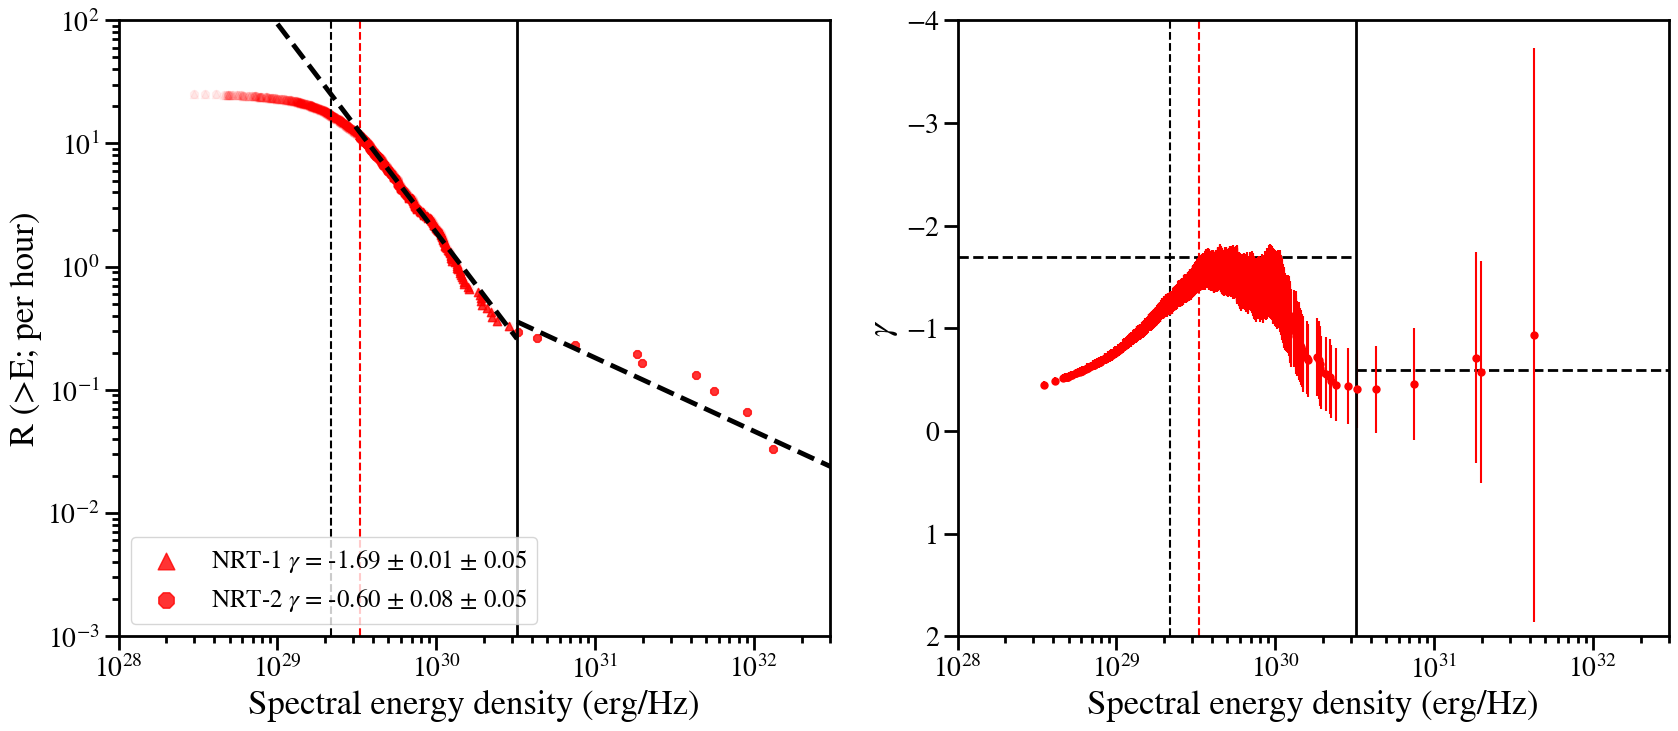

In [57]:
def distr_nancay(mjd_toggle=True):
    """
    Four panel analysis on the burst distirbution of Westerbork in the High energy tail
    top to bottom, left to right:
    panel 1: cummulative distribution with tail
    panel 2: cummulative distribution with the exclusion of the high enerfy tail, points are excluded based on eye.
    panel 3: differential distribution showing the fitted powerlaw of the cum. dist. plotted on top/
    panel 4: best gamma fit for the energies, vertical lines are the best fit gamma values for the two distributions.
    """
            
    fluence_df = nancay_r117(csv_file="/home/omar/git/nancay-r117/Burst-analyis-R117-Nancay/fixed_fluences.csv",\
                                 mjd_limit=mjd_toggle)
    fluences_nc_arr = fluences_arrays(fluence_df, telescope='nc')
    print(f"number of bursts used: {len(fluences_nc_arr)}")
    
    f_limit_nc = fluence_limit(sefd=35/1.4, bw=248.55874673629242, width =9.064, snr=15)
    energie_threshold = isotropic_energies([f_limit_nc])  

    if mjd_toggle == True:
        save_name = "mjd_limit"
        obs_h = 30.509
        
    else:
        save_name = "full_camp"  
        obs_h = 60.9933
        
    #Stockert    
    fluences_arr = fluences_nc_arr
    
    dish = ["Nancay"]
    color = ['red']
    limit = 4e30
    
    #Setting up the Figure
    fig = plt.figure(figsize=(20, 16))
    rows=2
    cols=2
    widths = [1,1]
    heights = [1,1]

    gs = gridspec.GridSpec(ncols=cols, nrows=rows,width_ratios=widths, height_ratios=heights, wspace=0.2, hspace=0.15)

    ax1 = fig.add_subplot(gs[0,0])
    ax2 = fig.add_subplot(gs[0,1])
    ax3 = fig.add_subplot(gs[1,0])
    ax4 = fig.add_subplot(gs[1,1])
    
    #plt.title("Cumulative distribution of burst densities", fontsize=28)
        
    sols_dict = {}
    tresh = {}
    
    for dish, color in zip(dish, color):
            
        print(f"Fitting: {dish}, obs hours is {obs_h}")
        #Energy is sorted from high-low
        energies_arr = isotropic_energies(fluences_arr)

        ############
        #Powerlaw distriutions
        ############
        
#         if dish == "Westerbork-excl-tail":
#             energies_fit, y_points_fit, energies_ex, y_points_ex, sol2, sol2_err, turning_point, b_alpha = \
#                     power_law_fit(energies_arr, observed_time=obs_h, scale=10**18, \
#                                   limit=(energie_threshold, limit),limit_b=True, ex_max=5)
    
#             ax_dist = ax2
        
        if dish == "Nancay":
            energies_fit, y_points_fit, energies_ex, y_points_ex, sol2, sol2_err, turning_point, b_alpha = \
                    power_law_fit(energies_arr, observed_time=obs_h, scale=10**18, \
                                  limit=(energie_threshold, limit),limit_b=True, ex_max=None)
                
            ax1.axvline(turning_point, color=color, linestyle='--')
            ax_dist = ax1
            
        ax_dist.plot(energies_fit,func_powerlaw(energies_fit,*sol2[0]),color=color,lw=0.8)
        ax_dist.scatter(np.sort(energies_ex), np.flip(y_points_ex), color=color, marker="^", alpha=0.2)
        ax_dist.scatter(np.sort(energies_fit), np.flip(y_points_fit), color=color, marker = "^", alpha=0.5, \
                     label = fr"{dish} $\gamma$ = {sol2[0][1]:.2f} $\pm$ {sol2_err[1]:.2f} $\pm$ {b_alpha:.2f}")

        #Get the poissonian errors on the points
        low_err = get_poisson_error(np.flip(y_points_fit)*obs_h, conf_level=0.95)[0]/obs_h
        upp_err = get_poisson_error(np.flip(y_points_fit)*obs_h, conf_level=0.95)[1]/obs_h
        ax_dist.errorbar(np.sort(energies_fit), np.flip(y_points_fit), \
                     yerr = (np.flip(y_points_fit)-low_err, upp_err-np.flip(y_points_fit)), \
                     alpha = 0.8, color =color,fmt='.', zorder =0)

        ax_dist.axvline(energie_threshold, color='black', linestyle='--')
        ax_dist.legend(loc='upper left', markerscale=2, fontsize=18)
        ax_dist.set_ylim(0.0001,100)
        ax_dist.set_ylabel("R (>E; per hour)", fontsize=25)
        
        sols_dict[color] = sol2, sol2_err
        tresh[color] = energie_threshold, b_alpha
        print(f"sols for fit: {sol2}")

        ############
        #Differential Distribution
        ############
        #Vertical line completeness threshold
        ax2.axvline(energie_threshold, color='black', linestyle='--')
        
        #print(fluence_arr)
        fluence_arr = np.sort(energies_arr)

        #Only include data points in the fit
        fluence_arr = np.array([element for element in energies_arr if element > energie_threshold])
        #bins
        bin_num = 10
        logbins = np.logspace(np.log10(np.min(fluence_arr)),np.log10(np.max(fluence_arr)),bin_num)
        
        counts_norm, bins = np.histogram(fluence_arr, bins=logbins, density=True)       
        counts, _ = np.histogram(fluence_arr, bins=logbins, density=False) ###
        
        if dish == "Nancay":
            
            counts_norm, bins, _ = ax2.hist(fluence_arr, bins=logbins, color=color, density=True, edgecolor = 'black', alpha=0.55)
            norm_fac_counts = sum(counts) * np.diff(bins)
            error_low, error_upp = get_rate_errors(counts, conf_level = 0.95) ###

            error_low /= norm_fac_counts ###
            error_upp /= norm_fac_counts ###
            bin_centers = np.sqrt(bins[0:-1]*bins[1:]) ###
            ax2.plot([bin_centers, bin_centers], [counts_norm - error_low, 
                                              counts_norm + error_upp], '-', color=color) ###
            
        #Slope def in postive, to convert to differential slope we add 1
        negative_slope = sol2[0][1]
        slope = abs(negative_slope) + 1.
        
        energies = np.sqrt(logbins[:-1]*logbins[1:])
        norm = quad(pl_dist_pdf, np.min(fluence_arr), np.max(fluence_arr), args=(energie_threshold, slope))[0]
        ax2.plot(energies, pl_dist_pdf(energies, energie_threshold, slope) / norm, color=color,lw=1.5, \
                 label = fr"{dish} $\gamma$ = {sol2[0][1]:.2f} $\pm$ {sol2_err[1]:.2f} $\pm$ {b_alpha:.2f}")  

        ax2.set_ylabel('Count density [au]', fontsize=25)
        #ax3.set_ylim(2e-35, 1e-31)

        
        ############
        #Gamma slopes
        ############    
        #Call the gamma_slopes function
        total_gamma, energy_threshold, error_ar = gamma_slopes(energies_arr, conf_level=2)
        print(len(total_gamma), len(energy_threshold), len(error_ar))
        
        ax3.errorbar(energy_threshold[:-2], total_gamma[:-2], yerr = np.abs(error_ar), fmt='.', color=color\
                     , markersize=10)
        ax3.axvline(energie_threshold, color='black', linestyle='--')
        ax3.axvline(1.5e30, color='black', linestyle='--')
        ax3.set_ylabel(r'$\gamma$', fontsize=25)
        ax3.set_ylim(3,-4)
        ax3.axhline(negative_slope, color=color, linestyle='dashdot', linewidth=2.5)
        ax3.yaxis.set_major_locator(ticker.MultipleLocator(1.0))
        ax3.axvline(turning_point, color='red', linestyle='--', linewidth=2)
        
        ############
        #Gamma slopes comparission
        ############  
        
        #Values that are excluded in the fit    
        eye_point = 2e30
        energies_left = energies_arr[(energie_threshold <= energies_arr) & (energies_arr <= eye_point)]
        energies_right = energies_arr[(eye_point <= energies_arr)]
        energies_fitting = [energies_left, energies_right]
        print(len(energies_fitting[0]), len(energies_fitting[1]))
        
        for energie_side in energies_fitting:
        
            ###
            #Gamma fitting
            ###
            total_gamma, energy_threshold, error_ar = gamma_slopes(energie_side, conf_level=2)
            ax4.errorbar(energy_threshold[:-2], total_gamma[:-2], yerr = np.abs(error_ar), fmt='.', color='red'\
                         ,markersize=10)
            ax4.set_ylabel(r'$\gamma$', fontsize=25)
            ax4.set_ylim(4,-8)
            ax4.axvline(turning_point, color='red', linestyle='--', linewidth=2)
            ax4.axvline(eye_point, color='black', linestyle='--', linewidth=2)
            ax4.axhline(total_gamma[0], color='red', linestyle='dashdot', linewidth=2)
        
        #ax4.axvline(turning_point)
        
    for ax in [ax1,ax2,ax3,ax4]:
        for axis in ['top','bottom','left','right']:
            
            ax.spines[axis].set_linewidth(2)
            ax.tick_params(axis='y', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='y', which='minor', direction='out', length=5, width=2)
            ax.tick_params(axis='x', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='x', which='minor', direction='out', length=5, width=2)
            
        if ax == ax1 or ax == ax2:
            ax.set_yscale('log')
            
            
        ax.set_xscale('log')
        ax.tick_params(axis='both', which='major', labelsize=20)
    
    ax1.set_xlim(1e28,3e32)
    ax3.set_xlim(1e28,3e32)
    
    ax2.set_xlim(1e29,3e32)
    ax4.set_xlim(1e29,3e32)
    
    ax3.set_xlabel("Spectral energy density (erg/Hz)", fontsize=25)
    ax4.set_xlabel("Spectral energy density (erg/Hz)", fontsize=25)
                
    save_name="full_camp_new"
    plt.savefig(f"../plots/nc_{save_name}_4panel_gammas.png", \
               bbox_inches='tight', facecolor='white', transparent=False, dpi=300)
    plt.show()

    return 

#distr_nancay(mjd_toggle=False)

In [39]:
# def nancay_fluence_test():

#     fluence_df = nancay_r117(csv_file="/home/omar/git/nancay-r117/Burst-analyis-R117-Nancay/fixed_fluences.csv",\
#                                  mjd_limit=True)
#     fluences_nc_arr = fluences_arrays(fluence_df, telescope='nc')

#     return fluences_nc_arr

# fluences_nc_tst = nancay_fluence_test()

In [38]:
# def func_powerlaw_t(x, scale=5, gamma=1):
#     return x**gamma * scale
    

        
# def test_powerlaw():

#     energies_fit = np.sort(fluences_nc_tst)[400:]
#     y_points_fit = np.arange(1, len(energies_fit)+1, 1) 
    
#     #apply curve_fit to do the fit
#     popt, pcov = curve_fit(func_powerlaw, np.sort(energies_fit), np.flip(y_points_fit),
#                                p0 = np.asarray([1e19, -1]), maxfev=50000)

#     #apply curve_fit to do the fit
#     popt2, pcov2 = curve_fit(func_broken_powerlaw, np.sort(energies_fit), np.flip(y_points_fit),
#                                p0 = np.asarray([1e10, -1.3,-0.8,100]), maxfev=50000)

#     print(popt2)
#     #plt.plot(energies_fit,func_powerlaw(energies_fit,*popt),color='black',lw=1.5)
#     plt.plot(energies_fit,func_broken_powerlaw(energies_fit,*popt2),color='black',lw=1.5)
#     plt.scatter(np.sort(energies_fit), np.flip(y_points_fit), color='black', marker="^", s=10)

#     plt.xscale('log')
#     plt.yscale('log')
#     print(popt)
#     return

# test_powerlaw()

In [25]:
# def histogram_compare_stockert(energy_tail, wo_energy_tail,fluences_stk):

#     """
#     Input is a list consisting of 
#     """
    
#     energies_array_stk = isotropic_energies(fluences_stk)

#     f_limit_stk = fluence_limit(sefd=385, width=3, bw=80, snr=15)
#     energie_threshold_stk = isotropic_energies([f_limit_stk])
    
#     f, ax = plt.subplots(1, figsize=(12,10))
    
#     for axis in ['top','bottom','left','right']:
#         ax.spines[axis].set_linewidth(2)
            
#         ax.tick_params(axis='y', which='major', direction='out', length=10, width=2)
#         ax.tick_params(axis='y', which='minor', direction='out', length=5, width=2)
#         ax.tick_params(axis='x', which='major', direction='out', length=10, width=2)
#         ax.tick_params(axis='x', which='minor', direction='out', length=5, width=2)
 
#     fluences = [energies_array_stk, energies_array_stk]
#     thresholds = [energie_threshold_stk, energie_threshold_stk]
#     dish = ["Stockert-tail", "Stockert-excl-tail"]
#     color = ['purple', 'black']

#     scales = energy_tresh

    
#     for fluence_arr, energie_threshold, dish, color_dish in zip(fluences, thresholds, dish, color):
        
#         #Retrieve the energy threshold 
#         threshold = energy_tresh[color_dish][0]
        
#         #Vertical line completeness threshold
#         plt.axvline(energie_threshold, color=color_dish, linestyle='--')
        
#         #print(fluence_arr)
#         fluence_arr = np.sort(fluence_arr)
        
#         #Only include data points in the fit
#         fluence_arr = np.array([element for element in fluence_arr if element > threshold])
                
#         #bins
#         bin_num = 12 
#         logbins = np.logspace(np.log10(np.min(fluence_arr)),np.log10(np.max(fluence_arr)),bin_num)
        
#         counts_norm, bins = np.histogram(fluence_arr, bins=logbins, density=True)       
#         counts, _ = np.histogram(fluence_arr, bins=logbins, density=False) ###
        
#         print(counts)
#         if dish == "Stockert-tail":
#             counts_norm, bins, _ = plt.hist(fluence_arr, bins=logbins, color=color_dish, density=True, edgecolor = 'black', alpha=0.55)
        
#             norm_fac_counts = sum(counts) * np.diff(bins)
#             error_low, error_upp = get_rate_errors(counts, conf_level = 0.95) ###

#             error_low /= norm_fac_counts ###
#             error_upp /= norm_fac_counts ###
#             bin_centers = np.sqrt(bins[0:-1]*bins[1:]) ###
#             plt.plot([bin_centers, bin_centers], [counts_norm - error_low, 
#                                               counts_norm + error_upp], '-', color=color_dish) ###
    
#         #Slope def in postive, so add one
#         slope = abs(sols_dict_dist[color_dish][0][0][1]) + 1.
#         sol2 = sols_dict_dist[color_dish][0]
#         sol2_err = sols_dict_dist[color_dish][1]
#         b_alpha = energy_tresh[color_dish][1]
        
#         energies = np.sqrt(logbins[:-1]*logbins[1:])
#         norm = quad(pl_dist_pdf, np.min(fluence_arr), np.max(fluence_arr), args=(threshold, slope))[0]
#         plt.plot(energies, pl_dist_pdf(energies, threshold, slope) / norm, color=color_dish,lw=1.5, \
#                  label = fr"{dish} $\gamma$ = {sol2[0][1]:.2f} $\pm$ {sol2_err[1]:.2f} $\pm$ {b_alpha:.2f}")
        
#     #plt.ylabel("Counts", fontsize=25)
#     plt.xlabel("Spectral energy density (erg/Hz)", fontsize=25)
#     plt.xticks(fontsize=22)
#     plt.yticks(fontsize=22)
#     #plt.xlim(2e29,5e32)
    
#     plt.xscale('log')
#     plt.yscale('log')
#     plt.legend(markerscale=2, fontsize=18)
#     #plt.ylim(0,10)
#     plt.show()
    
# histogram_compare_stockert(sols_dict_dist, energy_tresh, fluences_stk)

In [26]:
# def distr_fast_r117():
#     "Cum disstribution of burst densities of Westerbork"
#     "Pband bursts"

#     f_limit_wb = fluence_limit(sefd=2100, width=10, bw=50, snr=15)
#     energie_threshold_wb = isotropic_energies([f_limit_wb])
    
#     #Westerbork    
#     fluences = [fluences_wb_p_arr]
#     obs_hours = [760.01]
#     thresholds = [energie_threshold_wb]
#     dish = ['Westerbork']
#     color = ['blue']
#     limit = [9e31]
    
#     #   Figure
#     plt.figure(figsize=(12,10))
#     plt.title("Cumulative distribution of burst densities", fontsize=28)
    
#     for fluences_arr, obs_h, energie_threshold, dish, color, limit in zip(fluences, obs_hours, thresholds, dish, color, limit):
        
#         energies_arr = isotropic_energies(fluences_arr)
        
#         energies_fit, y_points_fit, energies_ex, y_points_ex, sol2, sol2_err, turning_point, b_alpha = \
#                 power_law_fit(energies_arr, observed_time=obs_h, scale=10**18, \
#                               limit=(energie_threshold, limit),limit_b=True)

#         plt.plot(energies_fit,func_powerlaw(energies_fit,*sol2[0]),color=color,lw=0.8)
#         plt.scatter(np.sort(energies_ex), np.flip(y_points_ex), color=color, marker="^", alpha=0.25)
#         plt.scatter(np.sort(energies_fit), np.flip(y_points_fit), color=color, marker = "^", \
#                      label = fr"{dish} $\gamma$ = {sol2[0][1]:.2f} $\pm$ {sol2_err[1]:.2f} $\pm$ {b_alpha:.2f}")

#         low_err = get_poisson_error(np.flip(y_points_fit)*obs_h)[0]/obs_h
#         upp_err = get_poisson_error(np.flip(y_points_fit)*obs_h)[1]/obs_h
#         plt.errorbar(np.sort(energies_fit), np.flip(y_points_fit), \
#                      yerr = (np.flip(y_points_fit)-low_err, upp_err-np.flip(y_points_fit)), \
#                      alpha = 0.8, color =color,fmt='.', zorder =0)
        
#         plt.axvline(energie_threshold, color=color, linestyle='--')
    
#     plt.ylabel("R (>E; per hour)", fontsize=21)
#     plt.xlabel("Spectral energy density (erg/Hz)", fontsize=21)
#     plt.xscale('log')
#     plt.yscale('log')
#     plt.xticks(fontsize=22)
#     plt.yticks(fontsize=22)
#     plt.ylim(0.0001,1)
#     plt.xlim(1e31,8e32)
#     #plt.legend(loc='lower left', markerscale=2, fontsize=16)
#     #plt.savefig("../plots/burstrate_pband_nolegend.png", bbox_inches='tight', facecolor='white', transparent=False, dpi=600)
#     plt.show()

# distr_fast_r117()

In [27]:
# def gamma_slope():
    
#     energies_array_stk = isotropic_energies(fluences_stk_arr)
#     sorted_energy = np.sort(energies_array_stk)
    
#     f_limit_stk = fluence_limit(sefd=385, width=3, bw=80, snr=15)
#     energie_threshold_stk = isotropic_energies([f_limit_stk])
    
#     total_gamma = []
#     energy_threshold = []
#     error_ar = []
    
#     f, ax = plt.subplots(1, figsize=(10,10))
    
#     plt.axvline(energie_threshold_stk, linestyle='--', color='purple')
    
#     plt.axhline(-0.65, linestyle="--", color='black')
#     plt.axhline(-0.99, linestyle="--", color='black')
    
#     for axis in ['top','bottom','left','right']:
#         ax.spines[axis].set_linewidth(2)
            
#         ax.tick_params(axis='y', which='major', direction='out', length=10, width=2)
#         ax.tick_params(axis='y', which='minor', direction='out', length=5, width=2)
#         ax.tick_params(axis='x', which='major', direction='out', length=10, width=2)
#         ax.tick_params(axis='x', which='minor', direction='out', length=5, width=2)
        
#     for j in range(1,len(sorted_energy)-1):
#         alpha = (1/( -1/len(sorted_energy[sorted_energy>sorted_energy[j]]) * \
#                     np.sum(np.log(sorted_energy[sorted_energy>sorted_energy[j]] / sorted_energy[j]))))
#         M = len(sorted_energy[sorted_energy>sorted_energy[j]])
#         alpha = ((M-1)/M) * alpha
#         total_gamma.append(alpha)
#         energy_threshold.append(sorted_energy[j])

#         if M > 2:
#         #We multiply by 2 to convert the 1-sigma error to 2 sigma errors
#             error = M * alpha / ((M-1)*(M-2)**0.5) * 2 
#             error_ar.append(error)
        
#     print(len(total_gamma), len(energy_threshold), len(error_ar))
#     plt.errorbar(energy_threshold[:-2], total_gamma[:-2], yerr = np.abs(error_ar), fmt='.', color='purple')
#     plt.ylim(0.0, -4.0)
#     plt.ylabel(r'$\gamma$', fontsize=25)
#     plt.xlabel("Spectral energy density (erg/Hz)", fontsize=25)
#     plt.xticks(fontsize=22)
#     plt.yticks(fontsize=22)
#     plt.xscale('log')
#     #plt.ylim(ax2.get_ylim()[::-1])
#     #plt.xlim(1e30, 2e32)
#     plt.show()
    
# gamma_slope()

In [28]:
# ##Old code with no forlooop
# def distr_fast_r117():
#     "Cum disstribution of burst densities of Westerbork"
    
#     energies_array_stk = isotropic_energies(fluences_stk_arr)
#     energies_array_wb = isotropic_energies(fluences_wb_arr)
#     energies_array_fast = isotropic_energies(fast_fluence_r117)  
#     energies_array_nc = isotropic_energies(fluences_nc_arr)  
    
#     f_limit_wb = fluence_limit(sefd=420, width=3, bw=100, snr=15)
#     energie_threshold_wb = isotropic_energies([f_limit_wb])

#     f_limit_stk = fluence_limit(sefd=385, width=3, bw=80, snr=15)
#     energie_threshold_stk = isotropic_energies([f_limit_stk])
    
#     f_limit_nc = fluence_limit(sefd=35/1.4, bw=248.55874673629242, width =9.064, snr=20)
#     energie_threshold_nc = isotropic_energies([f_limit_nc])
    
#     #Stockert    
#     ob_time_stk_l = 567.4
#     energies_fit_stk, y_points_fit_stk, energies_ex_stk, y_points_ex_stk, \
#         sol2_stk, sol2_err_stk, turning_point_stk, b_alpha_stk = \
#             power_law_fit(energies_array_stk, observed_time=ob_time_stk_l,
#                           scale=10**18, limit=(energie_threshold_stk, 1e30),
#                           limit_b=True)
    
#     #Westerbork
#     ob_time_wb_l = 185.72
#     energies_fit_wb, y_points_fit_wb, energies_ex_wb, y_points_ex_wb, \
#         sol2_wb, sol2_err_wb, turning_point_wb, b_alpha_wb = \
#             power_law_fit(energies_array_wb, observed_time=ob_time_wb_l,
#                           scale=10**18, limit=(energie_threshold_wb, 1e35),
#                           limit_b=True)
    
#     #Nancay (total is 61)
#     ob_time_nc_l = 30.5
#     energies_fit_nc, y_points_fit_nc, energies_ex_nc, y_points_ex_nc, \
#         sol2_nc, sol2_err_nc, turning_point_nc, b_alpha_nc = \
#             power_law_fit(energies_array_nc, observed_time=ob_time_nc_l,
#                           scale=10**18, limit=(energie_threshold_nc, 1e35),
#                           limit_b=True)
#     #Fast 
#     ob_time_fast = 8.67
#     energies_fit_fast, y_points_fit_fast, energies_ex_fast, y_points_ex_fast, \
#     sol2_fast, sol2_err_fast, turning_point_fast, b_alpha_f = \
#             power_law_fit(energies_array_fast, observed_time=ob_time_fast, \
#                           scale=10**18)
    
#     #joint
# #     energies_array_wb_st = np.concatenate([energies_fit_wb, energies_fit_stk])
# #     y_points_wb_stk = np.concatenate([y_points_fit_wb, y_points_fit_stk])
# #     print(energies_array_wb_st)
# #     print(len(energies_array_wb_st), len(y_points_wb_stk))
    
# #     energies_fit_wb_st, y_points_fit_wb_st, \
# #         sol2_wb_st, sol2_err_wb_st, b_alpha_wb_st = \
# #             joint_powerlaw_fit(energies_array_wb_st, y_points_wb_stk,
# #                                scale=10**18)
    
    
# #   Figure
#     plt.figure(figsize=(12,10))
#     plt.title("Cumulative distribution of burst densities", fontsize=28)
    
#     #Westerbork--plot
#     plt.plot(energies_fit_wb,func_powerlaw(energies_fit_wb,*sol2_wb[0]),color='blue',lw=0.8)
#     plt.scatter(np.sort(energies_ex_wb), np.flip(y_points_ex_wb), color='blue', marker="^", alpha=0.25)
#     plt.scatter(np.sort(energies_fit_wb), np.flip(y_points_fit_wb), color="blue", marker = "^", \
#                  label = fr"Westerbork $\gamma$ = {sol2_wb[0][1]:.2f} $\pm$ {sol2_err_wb[1]:.2f} $\pm$ {b_alpha_wb:.2f}")
    
#     low_err = get_poisson_error(np.flip(y_points_fit_wb)*ob_time_wb_l)[0]/ob_time_wb_l
#     upp_err = get_poisson_error(np.flip(y_points_fit_wb)*ob_time_wb_l)[1]/ob_time_wb_l
#     plt.errorbar(np.sort(energies_fit_wb), np.flip(y_points_fit_wb), yerr = (np.flip(y_points_fit_wb)-low_err, upp_err-np.flip(y_points_fit_wb)), alpha = 0.8, color ='blue',fmt='.', zorder =0)
#     plt.axvline(energie_threshold_wb, color='blue', linestyle='--')
    
#     #Nancay--lines
#     plt.plot(energies_fit_nc,func_powerlaw(energies_fit_nc,*sol2_nc[0]),color='orange',lw=0.8)
#     plt.scatter(np.sort(energies_ex_nc), np.flip(y_points_ex_nc), color='orange', marker="^", alpha=0.25)
#     plt.scatter(np.sort(energies_fit_nc), np.flip(y_points_fit_nc), color="orange", marker = "^", \
#                  label = fr"Nancay $\gamma$ = {sol2_nc[0][1]:.2f} $\pm$ {sol2_err_nc[1]:.2f} $\pm$ {b_alpha_nc:.2f}")
#     plt.axvline(energie_threshold_nc, color='orange', linestyle='--')
    
#     #fast
#     #plt.plot(energies_fit_fast,func_powerlaw(energies_fit_fast,*sol2_fast[0]),color='black',lw=1.4)
#     plt.scatter(np.sort(energies_ex_fast), np.flip(y_points_ex_fast), color='#e66101', marker="2", s=16, alpha=0.25)
#     plt.scatter(np.sort(energies_fit_fast), np.flip(y_points_fit_fast), color="#e66101", marker = "2",s=16,\
#                 label="FAST")
#                 #label= fr"Stockert $\gamma$ = {sol2_fast[0][1]:.2f} $\pm$ {sol2_err_fast[1]:.2f} $\pm$ {b_alpha_f:.2f}")
    
#     #Stockert--plot
#     plt.plot(energies_fit_stk,func_powerlaw(energies_fit_stk,*sol2_stk[0]),color='purple',lw=0.8)
#     plt.scatter(np.sort(energies_ex_stk), np.flip(y_points_ex_stk), color='purple', marker="^", alpha=0.25)
#     plt.scatter(np.sort(energies_fit_stk), np.flip(y_points_fit_stk), color="purple", marker = "^", \
#                label = fr"Stockert $\gamma$ = {sol2_stk[0][1]:.2f} $\pm$ {sol2_err_stk[1]:.2f} $\pm$ {b_alpha_stk:.2f}")
#     plt.axvline(energie_threshold_stk, color='purple', linestyle='--')
    
# #     plt.plot(energies_fit_wb_st, func_powerlaw(energies_fit_wb_st, *sol2_wb_st[0]),
# #             color='gray', lw=1.8,
# #             label = fr"O8+St $\gamma$ = {sol2_wb_st[0][1]:.2f} $\pm$ {sol2_err_wb_st[1]:.2f} $\pm$ {b_alpha_wb_st:.2f}")
        
#     plt.ylabel("R (>E; per hour)", fontsize=21)
#     plt.xlabel("Spectral energy density (erg/Hz)", fontsize=21)
#     plt.xscale('log')
#     plt.yscale('log')
#     plt.xticks(fontsize=22)
#     plt.yticks(fontsize=22)
#     plt.ylim(0.0001,200)
#     plt.xlim(5e26,5e32)
#     plt.legend(loc='lower left', markerscale=2, fontsize=16)
#     #plt.savefig("burstrate_fast_only_nac_limit.png", bbox_inches='tight', facecolor='white', transparent=False, dpi=600)
#     plt.show()

# distr_fast_r117()

In [29]:
# def wb_pband_r117():
#     "Cum disstribution of burst densities of Westerbork"
    
#     energies_wb = isotropic_energies(fluences_wb_p_arr)
    
#     f_limit_wb = fluence_limit(sefd=2100, width=10, bw=50, snr=15)
#     energie_threshold_wb = isotropic_energies([f_limit_wb])
#     print(energie_threshold_wb)
    
#     #Westerbork
#     ob_time_wb_p = 760.01
        
#     #Westerbork
#     energies_fit_wb, y_points_fit_wb, energies_ex_wb, y_points_ex_wb, \
#         sol2_wb, sol2_err_wb, turning_point_wb, b_alpha_wb = \
#             power_law_fit(energies_wb, observed_time=ob_time_wb_p,
#                           scale=10**18, limit=(energie_threshold_wb, 9e31),
#                           limit_b=True)
    
# #     #Figure
#     plt.figure(figsize=(12,8))
#     plt.title("Cumulative distribution Wb P-band", fontsize=28)
    
#     #Westerbork--plot
#     plt.plot(energies_fit_wb,func_powerlaw(energies_fit_wb,*sol2_wb[0]),color='blue',lw=0.8)
#     plt.scatter(np.sort(energies_ex_wb), np.flip(y_points_ex_wb), color='blue', marker="^", alpha=0.5)
#     plt.scatter(np.sort(energies_fit_wb), np.flip(y_points_fit_wb), color="blue", marker = "^", \
#                  label = fr"Westerbork $\gamma$ = {sol2_wb[0][1]:.2f} $\pm$ {sol2_err_wb[1]:.2f} $\pm$ {b_alpha_wb:.2f}")
#     plt.axvline(energie_threshold_wb, color='blue', linestyle='--')
    
#     plt.ylabel("R (>E; per hour)", fontsize=21)
#     plt.xlabel("Spectral energy density (erg/Hz)", fontsize=21)
#     plt.xscale('log')
#     plt.yscale('log')
#     plt.xticks(fontsize=22)
#     plt.yticks(fontsize=22)
#     plt.ylim(0.0001,200)
#     plt.xlim(5e26,5e32)
#     plt.legend(loc='lower left', markerscale=2, fontsize=20)
#     plt.savefig("burstrate_pband_version1.png", bbox_inches='tight', facecolor='white', transparent=False, dpi=600)
#     plt.show()

# wb_pband_r117()

Calculating best minimal value for power law fit
No limit_b, Turning point: 7.240563616505654e+30
7.240563616505654e+30 None
[[3.396996149864702e+35, -1.1816989734292187], array([[1.35127387e+58, 2.87342662e+27],
       [2.87342662e+27, 6.74953417e-04]])]
Bootstrapping, only using 43 points out of 48 points


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 2207.57it/s]


boot_alpha: 0.0663899476483635
Calculating best minimal value for power law fit
No limit_b, Turning point: 3.7707541675590537e+30
3.7707541675590537e+30 None
[[5.632639418232804e+21, -0.7417024738215419], array([[1.06749923e+57, 1.54727279e+27],
       [1.54727279e+27, 2.42667441e-03]])]
Bootstrapping, only using 20 points out of 23 points


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 3347.40it/s]


boot_alpha: 0.08007260187820198
Calculating best minimal value for power law fit
Turning point: 5.608936343767962e+29
5.608936343767962e+29 None
[[4.8481964802763625e+55, -1.840584069769515], array([[ 7.65540217e+57, -2.33684748e+27],
       [-2.33684748e+27,  1.03847045e-03]])]
Bootstrapping, only using 48 points out of 54 points


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 3036.90it/s]


boot_alpha: 0.13881502866798048
[3.77075417e+30 4.28086534e+30 4.57267937e+30 4.78922432e+30
 5.10021497e+30 5.43659236e+30 5.61825072e+30 5.65170135e+30
 6.10601345e+30 6.50761402e+30 8.00835107e+30 8.28355172e+30
 1.05278983e+31 1.23167722e+31 1.24989405e+31 1.25715191e+31
 3.40048874e+31 4.25988848e+31 4.35632677e+31 5.53229661e+31
 8.96827342e+31 9.26482715e+31 2.14995444e+32 7.24056362e+30
 7.48230914e+30 9.18679056e+30 1.00586698e+31 1.13979165e+31
 1.21340178e+31 1.22566348e+31 1.27231824e+31 1.29338962e+31
 1.32918706e+31 1.42117903e+31 1.42122578e+31 1.54728076e+31
 1.57077678e+31 1.76980969e+31 1.78157472e+31 1.82142188e+31
 1.90044430e+31 1.91500093e+31 1.96451690e+31 2.02775178e+31
 2.04793659e+31 2.06272850e+31 2.48016981e+31 3.17276812e+31
 3.30708719e+31 3.45060318e+31 3.71263720e+31 4.73707489e+31
 4.93326888e+31 5.10761282e+31 5.56103447e+31 5.62552426e+31
 5.68193755e+31 6.18934532e+31 6.40383426e+31 6.45945236e+31
 6.82857978e+31 6.83562827e+31 8.58566637e+31 8.85130

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 2140.99it/s]


boot_alpha: 0.048507008252298756


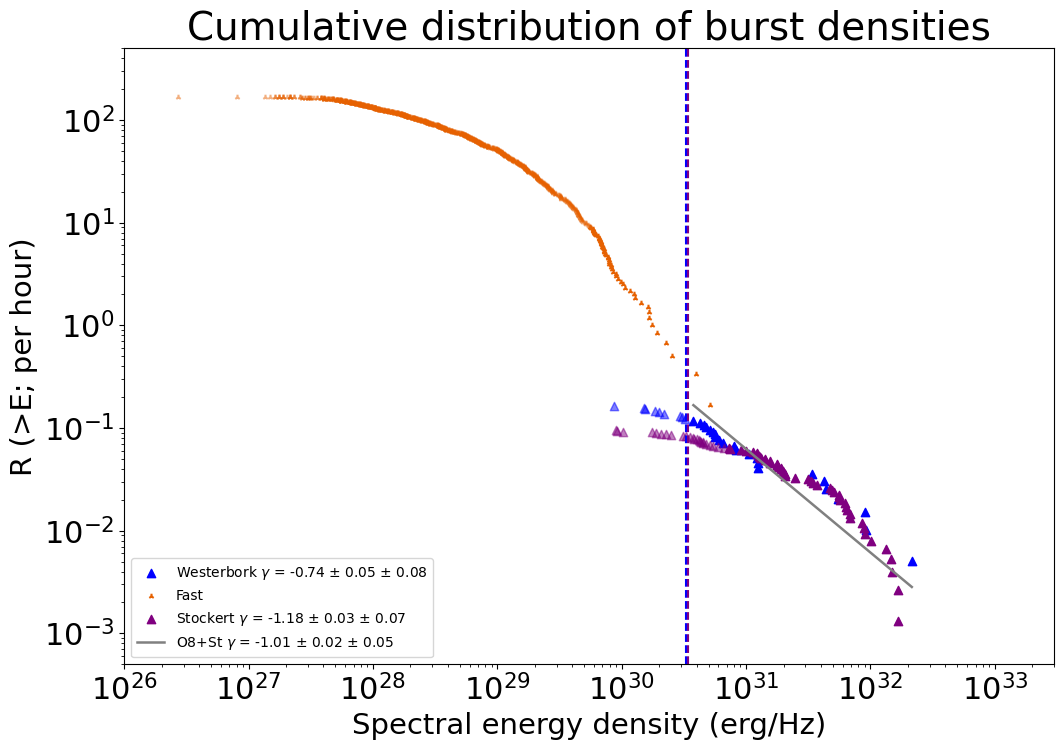

In [76]:
def plot_window1_fast():
    "Cum disstribution of burst densities of Westerbork"
    
    cent_frequency=1.4e9
    energies_array_wb = isotropic_energies(fluences_wb_arr)    
    energies_array_stk = isotropic_energies(fluences_stk_arr) 
    energies_array_fast = isotropic_energies(fast_fluence_r117)  
    
    f_limit_wb = fluence_limit(sefd=420, width=3, bw=100, snr=15)
    energie_threshold_wb = isotropic_energies([f_limit_wb])

    f_limit_stk = fluence_limit(sefd=385, width=3, bw=80, snr=15)
    energie_threshold_stk = isotropic_energies([f_limit_stk])
    
    #Stockert
    ob_time_stk_l = 760.10
    
    #Westerbork
    ob_time_wb_l = 196.58
    
    #Stockert
    energies_fit_stk, y_points_fit_stk, energies_ex_stk, y_points_ex_stk, \
        sol2_stk, sol2_err_stk, turning_point_stk, b_alpha_stk = \
            power_law_fit(energies_array_stk, observed_time=ob_time_stk_l,
                          scale=10**18, limit=(energie_threshold_stk, 1e31),
                          limit_b=True)
    
    #Westerbork
    energies_fit_wb, y_points_fit_wb, energies_ex_wb, y_points_ex_wb, \
        sol2_wb, sol2_err_wb, turning_point_wb, b_alpha_wb = \
            power_law_fit(energies_array_wb, observed_time=ob_time_wb_l,
                          scale=10**18, limit=(energie_threshold_wb, 1e35),
                          limit_b=True)
        
    #Fast 
    ob_time_fast = 6.0
    energies_fit_fast, y_points_fit_fast, energies_ex_fast, y_points_ex_fast, \
    sol2_fast, sol2_err_fast, turning_point_fast, b_alpha_f = \
            power_law_fit(energies_array_fast, observed_time=ob_time_fast, \
                          scale=10**18)
    
    #joint
    energies_array_wb_st = np.concatenate([energies_fit_wb, energies_fit_stk])
    y_points_wb_stk = np.concatenate([y_points_fit_wb, y_points_fit_stk])
    print(energies_array_wb_st)
    print(len(energies_array_wb_st), len(y_points_wb_stk))
    
    energies_fit_wb_st, y_points_fit_wb_st, \
        sol2_wb_st, sol2_err_wb_st, b_alpha_wb_st = \
            joint_powerlaw_fit(energies_array_wb_st, y_points_wb_stk,
                               scale=10**18)
    
    
#     #Figure
    plt.figure(figsize=(12,8))
    plt.title("Cumulative distribution of burst densities", fontsize=28)
    
    #Westerbork--plot
    #plt.plot(energies_fit_wb,func_powerlaw(energies_fit_wb,*sol2_wb[0]),color='blue',lw=0.8)
    plt.scatter(np.sort(energies_ex_wb), np.flip(y_points_ex_wb), color='blue', marker="^", alpha=0.5)
    plt.scatter(np.sort(energies_fit_wb), np.flip(y_points_fit_wb), color="blue", marker = "^", \
                label = fr"Westerbork $\gamma$ = {sol2_wb[0][1]:.2f} $\pm$ {sol2_err_wb[1]:.2f} $\pm$ {b_alpha_wb:.2f}")
    plt.axvline(energie_threshold_wb, color='blue', linestyle='--')
    
    #fast
    plt.scatter(np.sort(energies_ex_fast), np.flip(y_points_ex_fast), color='#e66101', marker="2", s=16, alpha=0.5)
    plt.scatter(np.sort(energies_fit_fast), np.flip(y_points_fit_fast), color="#e66101", marker = "2",s=16, \
                label= fr"Fast")
    
    #Stockert--plot
    #plt.plot(energies_fit_stk,func_powerlaw(energies_fit_stk,*sol2_stk[0]),color='purple',lw=0.8)
    plt.scatter(np.sort(energies_ex_stk), np.flip(y_points_ex_stk), color='purple', marker="^", alpha=0.5)
    plt.scatter(np.sort(energies_fit_stk), np.flip(y_points_fit_stk), color="purple", marker = "^", \
                label = fr"Stockert $\gamma$ = {sol2_stk[0][1]:.2f} $\pm$ {sol2_err_stk[1]:.2f} $\pm$ {b_alpha_stk:.2f}")
    plt.axvline(energie_threshold_stk, color='purple', linestyle='--')
    
    plt.plot(energies_fit_wb_st, func_powerlaw(energies_fit_wb_st, *sol2_wb_st[0]),
             color='gray', lw=1.8,
             label = fr"O8+St $\gamma$ = {sol2_wb_st[0][1]:.2f} $\pm$ {sol2_err_wb_st[1]:.2f} $\pm$ {b_alpha_wb_st:.2f}")
        
    plt.ylabel("R (>E; per hour)", fontsize=21)
    plt.xlabel("Spectral energy density (erg/Hz)", fontsize=21)
    plt.xscale('log')
    plt.yscale('log')
    plt.xticks(fontsize=22)
    plt.yticks(fontsize=22)
    plt.ylim(0.0005,500)
    plt.xlim(1e26,3e33)
    plt.legend(loc='lower left')
    plt.savefig("burstrate_wb_stk_seperate.png", bbox_inches='tight', facecolor='white', transparent=False, dpi=600)
    plt.show()

plot_window1_fast()

In [75]:
# def joint_powerlaw_fit(energies, y_points_fit, scale):
#     # sorting things by energy
#     tmp = np.sort(np.vstack([energies, y_points_fit]), axis=1)
#     energies, y_points_fit = tmp
#     ###
#     #Curve_fit for the slope
#     a_star, a_err = slope_est(energies)
#     #print(f"estimate: {a_star:.4f} {a_err:.4f}")

#     #apply curve_fit to do the fit
#     popt, pcov = curve_fit(func_powerlaw, energies, np.flip(y_points_fit),
#                            p0 = np.asarray([scale, a_star]), maxfev=50000)

#     #flip x and y to use the x-error
#     popt_flip, pcov_flip = curve_fit(func_powerlaw, np.flip(y_points_fit), energies,
#                                      p0=[popt[0]**(1./-popt[1]), 1./popt[1]],
#                                      sigma=np.asarray(energies*0.2),\
#                                      absolute_sigma=True)

#     #Calculate the popt values in the xy frame, use the errors on the fit
#     popt_back=[popt_flip[0]**(1./-popt_flip[1]), 1./popt_flip[1]]
#     sol2 = [popt_back, pcov_flip]

#     sol2_err = np.sqrt(np.diag(sol2[1]))
#     xx = np.linspace(np.min(energies), np.max(energies), 500)
#     p_y = func_powerlaw(xx, *sol2[0])

#     ##Bootstrapping
#     subset_int = int(len(energies) * 0.9)
#     print(f"Bootstrapping, only using {subset_int} points out of {len(energies)} points")

#     N=1000
#     alpha_list = []
#     for trial in tqdm(range(N)):

#         #subset_list = random.sample(list(energies_fit), k = subset_int)

#         #Get a random sample of 90% from the fitted energies
#         ss_energie, ss_ypoint = zip(*random.sample(list(zip(energies, y_points_fit)),                                                                k=subset_int))

#         #Sort them again from big to small
#         ss_energie_1, ss_ypoint_1 = zip(*sorted(zip(ss_energie, ss_ypoint)))

#         popt_bs_yx, pcov_bs_yx = curve_fit(func_powerlaw,np.flip(ss_ypoint_1),ss_energie_1,                            p0=[popt[0]**(1./-popt[1]),1./popt[1]],                                sigma=np.asarray(ss_energie_1)*0.2,absolute_sigma=True)

#         #Covert back to values, bootstramp reversed
#         popt_bs_r=[popt_bs_yx[0]**(1./-popt_bs_yx[1]),1./popt_bs_yx[1]]

#         #Append the value for the slope the list
#         alpha_list.append(popt_bs_r[1])

#     #Calculate the boot_alpha
#     boot_alpha = np.std(alpha_list)
#     print(f"boot_alpha: {boot_alpha}")

#     return energies, y_points_fit, sol2, sol2_err, boot_alpha

In [78]:
# def joint_powerlaw_fit(energies, y_points_fit, scale):
#     # sorting things by energy
#     tmp = np.sort(np.vstack([energies, y_points_fit]), axis=1)
#     energies, y_points_fit = tmp
#     ###
#     #Curve_fit for the slope
#     a_star, a_err = slope_est(energies)
#     #print(f"estimate: {a_star:.4f} {a_err:.4f}")

#     #apply curve_fit to do the fit
#     popt, pcov = curve_fit(func_powerlaw, energies, np.flip(y_points_fit),
#                            p0 = np.asarray([scale, a_star]), maxfev=50000)

#     #flip x and y to use the x-error
#     popt_flip, pcov_flip = curve_fit(func_powerlaw, np.flip(y_points_fit), energies,
#                                      p0=[popt[0]**(1./-popt[1]), 1./popt[1]],
#                                      sigma=np.asarray(energies*0.2),\
#                                      absolute_sigma=True)

#     #Calculate the popt values in the xy frame, use the errors on the fit
#     popt_back=[popt_flip[0]**(1./-popt_flip[1]), 1./popt_flip[1]]
#     sol2 = [popt_back, pcov_flip]

#     sol2_err = np.sqrt(np.diag(sol2[1]))
#     xx = np.linspace(np.min(energies), np.max(energies), 500)
#     p_y = func_powerlaw(xx, *sol2[0])

#     ##Bootstrapping
#     subset_int = int(len(energies) * 0.9)
#     print(f"Bootstrapping, only using {subset_int} points out of {len(energies)} points")

#     N=1000
#     alpha_list = []
#     for trial in tqdm(range(N)):

#         #subset_list = random.sample(list(energies_fit), k = subset_int)

#         #Get a random sample of 90% from the fitted energies
#         ss_energie, ss_ypoint = zip(*random.sample(list(zip(energies, y_points_fit)),                                                                k=subset_int))

#         #Sort them again from big to small
#         ss_energie_1, ss_ypoint_1 = zip(*sorted(zip(ss_energie, ss_ypoint)))

#         popt_bs_yx, pcov_bs_yx = curve_fit(func_powerlaw,np.flip(ss_ypoint_1),ss_energie_1,                            p0=[popt[0]**(1./-popt[1]),1./popt[1]],                                sigma=np.asarray(ss_energie_1)*0.2,absolute_sigma=True)

#         #Covert back to values, bootstramp reversed
#         popt_bs_r=[popt_bs_yx[0]**(1./-popt_bs_yx[1]),1./popt_bs_yx[1]]

#         #Append the value for the slope the list
#         alpha_list.append(popt_bs_r[1])

#     #Calculate the boot_alpha
#     boot_alpha = np.std(alpha_list)
#     print(f"boot_alpha: {boot_alpha}")
    
#     return energies, y_points_fit, sol2, sol2_err, boot_alpha

In [79]:
# energies_wb_limit = energies_wb[energies_wb > energie_threshold_wb]
# energies_tr_limit = energies_tr[energies_tr > energie_threshold_tr]
# energies_st_limit = energies_st[energies_st > energie_threshold_st]

# wb_weights = np.array([1./ob_time_wb] * len(energies_wb_limit))
# tr_weights = np.array([1./ob_time_tr] * len(energies_tr_limit))
# st_weights = np.array([1./ob_time_st] * len(energies_st_limit))

# #All info for doing a global fit on the fluences
# energies_for_hist = np.concatenate([energies_wb_limit, energies_tr_limit, energies_st_limit])
# weights_for_hist = np.concatenate([wb_weights, tr_weights, st_weights])
# # separate plot for global average of rates; we collect all energies and their
# # respective weights into one array, sort by energies and compute the cumulative sum
# # of the weights. This we then fit with a power law.

# global_rates = np.vstack([energies_for_hist, weights_for_hist]).T # shape = (nburst, 2)
# global_rates = global_rates[global_rates[:, 0].argsort()] # sort by energies, lowest first
# energies_global = global_rates[:, 0]
# weights_global  = global_rates[:, 1] 
# # these are sorted by lowest energy first, we want the cumsum > E,
# # i.e. we sum the rates starting with largest E

# rates_global = weights[::-1].cumsum() 
# # cumulative sum with highest E first
# # in the power_law_fit function, energies are sorted and rates are computed by
# # summing equal weights per burst, i.e. with rate for highest E first too. Flipping done in
# # the function.

# print('Global fit.')
# energies_fit_global, y_points_fit_global, energies_ex_global, y_points_ex_global, \
#     sol2_global, sol2_err_global, turning_point_global, b_alpha_global = \
#             power_law_fit(energies=energies, observed_time=rates,
#                           scale=10**18, limit_b=False, fit=True,
#                           ignore_turnover=True,
#                           time_is_weights=True)

In [83]:
##Old Version -- before adding the ATA to the function -- just added for backup
# def global_fit_energies():
#     """
#     Global cumulative distribution on R117
#     In this fit we only take bursts above the completeness threshold of the least sensitive telescope
    
#     No duplicate bursts are taken into account -- we filter those out before fitting
    
#     Overlap between Stockert and the ATA with Fluences 
#     B40-st 145 -  5-ATA 168
#     B41-st  32 -  6-ATA 224
#     B60-st 504 - 15-ATA 281
#     B93-st 420 - 25-ATA 1129
#     B98-st 662 - 26-ATA 625
    
#     Our campaign: 59867 -- 59983
#     ATA campaign: 59872 -- 59933
#     Would be fair to make a global plot for detections between 59867 -- 59933
#     Between 59933 and 59983 we had only 3 L-band detections in ~50 days. 
#     """
    
#     #Importing the Fluences
#     fluence_df = load_df("../dbs/burst_stats_r117.csv", band="L", mjd_limit=False)
    
#     fluences_stk_arr = fluences_arrays(fluence_df, telescope='st')
#     fluences_wb_arr = fluences_arrays(fluence_df, telescope='wb')
#     fluences_tr_arr = fluences_arrays(fluence_df, telescope='tr')
    
#     energies_wb = isotropic_energies(fluences_wb_arr)
#     energies_st = isotropic_energies(fluences_stk_arr)
#     energies_tr = isotropic_energies(fluences_tr_arr)
    
#     f_limit_wb = fluence_limit(sefd=420, width=3, bw=100, snr=15)
#     energie_threshold_wb = isotropic_energies([f_limit_wb])

#     f_limit_stk = fluence_limit(sefd=385, width=3, bw=80, snr=15)
#     energie_threshold_st = isotropic_energies([f_limit_stk])
    
#     f_limit_tr = fluence_limit(sefd=250, width=3, bw=100, snr=15)
#     energie_threshold_tr = isotropic_energies([f_limit_tr])
    
#     ob_time_wb = 185.72
#     ob_time_tr = 65.35 + 3.23
#     ob_time_st = 567.4
    
#     print("lenght of arr:", len(energies_wb), len(energies_tr), len(energies_st))
#     energies_wb_limit = energies_wb[energies_wb > energie_threshold_wb]
#     energies_tr_limit = energies_tr[energies_tr > energie_threshold_tr]
#     energies_st_limit = energies_st[energies_st > energie_threshold_st]
#     print(len(energies_wb_limit), len(energies_tr_limit), len(energies_st_limit))
    
#     wb_weights = np.array([1./ob_time_wb] * len(energies_wb_limit))
#     tr_weights = np.array([1./ob_time_tr] * len(energies_tr_limit))
#     st_weights = np.array([1./ob_time_st] * len(energies_st_limit))

#     #All info for doing a global fit on the fluences
#     energies_for_hist = np.concatenate([energies_wb_limit, energies_tr_limit, energies_st_limit])
#     weights_for_hist = np.concatenate([wb_weights, tr_weights, st_weights])
#     #print(len(energies_for_hist), len(weights_for_hist), energies_for_hist)
#     # separate plot for global average of rates; we collect all energies and their
#     # respective weights into one array, sort by energies and compute the cumulative sum
#     # of the weights. This we then fit with a power law.

#     global_rates = np.vstack([energies_for_hist, weights_for_hist]).T # shape = (nburst, 2)
#     global_rates = global_rates[global_rates[:, 0].argsort()] # sort by energies, lowest first
#     energies_global = global_rates[:, 0]
#     weights_global  = global_rates[:, 1] 
#     # these are sorted by lowest energy first, we want the cumsum > E,
#     # i.e. we sum the rates starting with largest E

#     rates_global = weights_global[::-1].cumsum() 
#     # cumulative sum with highest E first
#     # in the power_law_fit function, energies are sorted and rates are computed by
#     # summing equal weights per burst, i.e. with rate for highest E first too. Flipping done in
#     # the function.

#     print('Global fit.')
#     energies_fit_global, y_points_fit_global, energies_ex_global, y_points_ex_global, \
#         sol2_global, sol2_err_global, turning_point_global, b_alpha_global = \
#                 power_law_fit(energies=energies_global, observed_time=rates_global,
#                               scale=10**18, limit_b=False, fit=True,
#                               ignore_turnover=True,
#                               time_is_weights=True)

#     #energies_array_fast = isotropic_energies(fast_fluence_r117)
#     #*1.25e9
        
#     #Fast 
# #     ob_time_fast = 8.67
# #     energies_fit_fast, y_points_fit_fast, energies_ex_fast, y_points_ex_fast, \
# #     sol2_fast, sol2_err_fast, turning_point_fast, b_alpha_f = \
# #             power_law_fit(energies_array_fast, observed_time=ob_time_fast, \
# #                           scale=10**18)
    
# #     f_limit_wb = fluence_limit(sefd=420, width=3, bw=100, snr=15)
# #     energie_threshold_wb = isotropic_energies([f_limit_wb])

# #     f_limit_stk = fluence_limit(sefd=385, width=3, bw=80, snr=15)
# #     energie_threshold_stk = isotropic_energies([f_limit_stk])
    
# #     #Stockert
# #     ob_time_stk_l = 760.10
    
# #     #Westerbork
# #     ob_time_wb_l = 196.58
    
# #     #Stockert
# #     energies_fit_stk, y_points_fit_stk, energies_ex_stk, y_points_ex_stk, \
# #         sol2_stk, sol2_err_stk, turning_point_stk, b_alpha_stk = \
# #             power_law_fit(energies_array_stk, observed_time=ob_time_stk_l,
# #                           scale=10**18, limit=(energie_threshold_stk, 1e31),
# #                           limit_b=True)
    
# #     #Westerbork
# #     energies_fit_wb, y_points_fit_wb, energies_ex_wb, y_points_ex_wb, \
# #         sol2_wb, sol2_err_wb, turning_point_wb, b_alpha_wb = \
# #             power_law_fit(energies_array_wb, observed_time=ob_time_wb_l,
# #                           scale=10**18, limit=(energie_threshold_wb, 1e35),
# #                           limit_b=True)
        
# #     #Fast 
# #     ob_time_fast = 6.0
# #     energies_fit_fast, y_points_fit_fast, energies_ex_fast, y_points_ex_fast, \
# #     sol2_fast, sol2_err_fast, turning_point_fast, b_alpha_f = \
# #             power_law_fit(energies_array_fast, observed_time=ob_time_fast, \
# #                           scale=10**18)
    
# #     #joint
# #     energies_array_wb_st = np.concatenate([energies_fit_wb, energies_fit_stk])
# #     y_points_wb_stk = np.concatenate([y_points_fit_wb, y_points_fit_stk])
# #     print(energies_array_wb_st)
# #     print(len(energies_array_wb_st), len(y_points_wb_stk))
    
# #     energies_fit_wb_st, y_points_fit_wb_st, \
# #         sol2_wb_st, sol2_err_wb_st, b_alpha_wb_st = \
# #             joint_powerlaw_fit(energies_array_wb_st, y_points_wb_stk,
# #                                scale=10**18)
    
    
#     #Figure
#     plt.figure(figsize=(12,8))
#     plt.title("Cumulative distribution of burst densities", fontsize=28)
    
        
#     #Global--plot
#     plt.plot(energies_fit_global,func_powerlaw(energies_fit_global,*sol2_global[0]),color='blue',lw=0.8)
#     plt.scatter(np.sort(energies_ex_global), np.flip(y_points_ex_global), color='blue', marker="o", alpha=0.5)
#     plt.scatter(np.sort(energies_fit_global), np.flip(y_points_fit_global), color="blue", marker = "o", \
#                 label = "25-m dishes")
#                 #label = fr"Global-fit $\gamma$ = {sol2_global[0][1]:.2f} $\pm$ {sol2_err_global[1]:.2f} $\pm$ {b_alpha_global:.2f}")
#     #plt.axvline(energie_threshold_tr, color='blue', linestyle='--')
    
#     #fast
#     #plt.plot(energies_fit_fast,func_powerlaw(energies_fit_fast,*sol2_fast[0]),color='black',lw=1.4)
# #     plt.scatter(np.sort(energies_ex_fast), np.flip(y_points_ex_fast), color='#e66101', marker="2", s=16, alpha=0.5)
# #     plt.scatter(np.sort(energies_fit_fast), np.flip(y_points_fit_fast), color="#e66101", marker = "2",s=16, \
# #                 label="FAST")
# #                 #label= fr"FAST $\gamma$ = {sol2_fast[0][1]:.2f} $\pm$ {sol2_err_fast[1]:.2f} $\pm$ {b_alpha_f:.2f}")
    
    
# #     #Stockert--plot
# #     #plt.plot(energies_fit_stk,func_powerlaw(energies_fit_stk,*sol2_stk[0]),color='purple',lw=0.8)
# #     plt.scatter(np.sort(energies_ex_stk), np.flip(y_points_ex_stk), color='purple', marker="^", alpha=0.5)
# #     plt.scatter(np.sort(energies_fit_stk), np.flip(y_points_fit_stk), color="purple", marker = "^", \
# #                 label = fr"Stockert $\gamma$ = {sol2_stk[0][1]:.2f} $\pm$ {sol2_err_stk[1]:.2f} $\pm$ {b_alpha_stk:.2f}")
#     plt.axvline(energie_threshold_tr, color='blue', linestyle='--')
    
# #     plt.plot(energies_fit_wb_st, func_powerlaw(energies_fit_wb_st, *sol2_wb_st[0]),
# #              color='gray', lw=1.8,
# #              label = fr"O8+St $\gamma$ = {sol2_wb_st[0][1]:.2f} $\pm$ {sol2_err_wb_st[1]:.2f} $\pm$ {b_alpha_wb_st:.2f}")
        
#     plt.ylabel("R (>E; per hour)", fontsize=21)
#     plt.xlabel("Spectral energy density (erg/Hz)", fontsize=21)
#     plt.xscale('log')
#     plt.yscale('log')
#     plt.xticks(fontsize=22)
#     plt.yticks(fontsize=22)
#     #plt.ylim(0.001,500)
#     #plt.xlim(1e26,3e33)
#     plt.tick_params(axis='x', which='minor')
#     plt.legend(loc='lower left', fontsize=20, markerscale=2)
#     #plt.savefig("burstrate_global_nac_nolines.png", bbox_inches='tight', facecolor='white', transparent=False, dpi=600)
#     plt.show()

# global_fit_energies()